# Implementación propia de extracción de features

En esta sección detallaremos el proceso de visualización del dataset y haremos un reporte general de nuestro código de extracción de features y cómo hemos llegado al mismo justificando las decisiones que hemos tomado.


In [1]:
%matplotlib inline
%reload_ext autoreload
%autoreload 2
%config InlineBackend.figure_format='retina'
import sys; print(sys.version)

3.8.2 (default, Mar 26 2020, 15:53:00) 
[GCC 7.3.0]


In [2]:
from import_all import *

In [3]:
def hang_path(t_in,t_out,rename_base):
    return lambda fn : t_out/rename_base(t_in)/Path(os.path.relpath(str(fn),str(t_in)))

In [5]:
#IN_PATH = Path('./data/cedar')
IN_PATH = Path('./data/sigcomp2009')

OUT_PATH = Path('./data/parodi_out/preprocessed')

rename_base = lambda x : x.name

#get_fns = get_image_files
get_fns = ds_sigcomp2009.get_authentic_signatures


fns = L(get_fns(IN_PATH))
nf_func = hang_path(IN_PATH,OUT_PATH,rename_base)
def preproc_fmap(fn):
    nf = nf_func(fn)
    nf.parent.mkdir(parents=True, exist_ok=True)
    return otsu_preprocess(ds_sigcomp2009.get_x(fn)).save(nf)
preproc_fns = parallel(preproc_fmap,fns)

In [4]:
IN_PATH = Path('./data/parodi_out/preprocessed/sigcomp2009')
OUT_PATH = Path('./data/parodi_out/preprocessed/augmented')
get_fns = ds_sigcomp2009.get_authentic_signatures
rename_base = lambda x : x.name

fns = L(get_fns(IN_PATH))
nf_func = hang_path(IN_PATH,OUT_PATH,rename_base)
def augment_fmap(fn):
    new_parent = nf_func(fn).parent
    new_parent.mkdir(parents=True, exist_ok=True)
    augmented_imgs = data_augmentation(np.array(ds_sigcomp2009.get_x(fn)), 10)
    res = []
    for i, nimg in enumerate(augmented_imgs):
        new_filename = str(fn.name)[:-7] + str(i) + '_6g.PNG'
        new_path = new_parent/Path(new_filename) 
        nimg.save(new_path)
        res.append(new_path)
    return res
aug_fns = parallel(augment_fmap,fns)


In [41]:
%%time
IN_PATH = Path('./data/parodi_out/preprocessed/augmented-sigcomp2009')
ds_name = IN_PATH.name

for NDIV in [8,16,32,64,128]:
    print(NDIV)
    get_fns = get_image_files
    fns = L(get_fns(IN_PATH))
    def extract_fmap(fn):
        g = FastGrid(fn, lambda f : PILImageBW.create(f), N_divisions=NDIV)
        return g.features()

    OUT_PATH = Path('./data/parodi_out/features')/Path(str(NDIV))
    OUT_PATH.mkdir(parents=True, exist_ok=True)

    extracted = parallel(extract_fmap,fns)
    with open(OUT_PATH/Path(ds_name+'.npy'), 'wb') as f:
        np.save(f,np.array(extracted))
    with open(OUT_PATH/Path(ds_name+'.txt'), 'w') as f:
        f.write('\n'.join(fns.map(str)))

8
16
32
64
128
CPU times: user 40.5 s, sys: 5.03 s, total: 45.5 s
Wall time: 2h 46min 21s


In [38]:
def load_features(in_name,ndiv):
    OUT_PATH = Path('./data/parodi_out/features')/Path(str(ndiv))
    with open(OUT_PATH/Path(in_name+'.npy'), 'rb') as f:
        x = np.load(f)
    with open(OUT_PATH/Path(in_name+'.txt'), 'r') as f:
        fns = L(f.readlines()).map(lambda x : x.rstrip())
    return fns,x
fns,x=load_features('sigcomp2009',8)
len(fns),x.shape

(1000, (1000, 3, 8))

In [13]:
aug_fns

(#1000) [[Path('data/augmented/sigcomp2009/NISDCC/NISDCC-005_005_0040_6g.PNG'), Path('data/augmented/sigcomp2009/NISDCC/NISDCC-005_005_0041_6g.PNG'), Path('data/augmented/sigcomp2009/NISDCC/NISDCC-005_005_0042_6g.PNG'), Path('data/augmented/sigcomp2009/NISDCC/NISDCC-005_005_0043_6g.PNG'), Path('data/augmented/sigcomp2009/NISDCC/NISDCC-005_005_0044_6g.PNG'), Path('data/augmented/sigcomp2009/NISDCC/NISDCC-005_005_0045_6g.PNG'), Path('data/augmented/sigcomp2009/NISDCC/NISDCC-005_005_0046_6g.PNG'), Path('data/augmented/sigcomp2009/NISDCC/NISDCC-005_005_0047_6g.PNG'), Path('data/augmented/sigcomp2009/NISDCC/NISDCC-005_005_0048_6g.PNG'), Path('data/augmented/sigcomp2009/NISDCC/NISDCC-005_005_0049_6g.PNG')],[Path('data/augmented/sigcomp2009/NISDCC/NISDCC-002_002_0030_6g.PNG'), Path('data/augmented/sigcomp2009/NISDCC/NISDCC-002_002_0031_6g.PNG'), Path('data/augmented/sigcomp2009/NISDCC/NISDCC-002_002_0032_6g.PNG'), Path('data/augmented/sigcomp2009/NISDCC/NISDCC-002_002_0033_6g.PNG'), Path('dat

In [ ]:
def augmentation_callback(output_dir, pack):
    pa, sa, sid, fp = pack
    print((sa,pa,sid))
    np_image = imageio.imread(fp)
    augmented_imgs = data_augmentation(np_image, 10)
    result = []
    for i, augmented_img in enumerate(augmented_imgs):
        augmented_sid = sid + str(i)
        augmented_basename = os.path.basename(fp)[:-10] + augmented_sid + '_6g.PNG'
        augmented_fp = os.path.join(output_dir, augmented_basename)
        augmented_img.save(augmented_fp)
        result.append((pa,sa,sid,augmented_fp))
    return result



In [3]:
""" Load all the train images. """
TRAIN_PATH = './data/sigcomp2009/NISDCC'
PREPROCESSED_PATH='./data/parodi_out/preproc'
FEATURES_PATH = './data/parodi_out/features'
AUGMENTATION_PATH = './data/parodi_out/augmented'
FEATURE_FFT_ON = False

get_fns = ds_sigcomp2009.get_authentic_signatures
get_x = ds_sigcomp2009.get_x
get_y = ds_sigcomp2009.get_y

In [4]:
raw_dataset = L(get_fns(TRAIN_PATH))
print("Lodaded {} files.".format(len(raw_dataset)))
raw_dataset

Lodaded 60 files.


(#60) [Path('data/sigcomp2009/NISDCC/NISDCC-005_005_004_6g.PNG'),Path('data/sigcomp2009/NISDCC/NISDCC-002_002_003_6g.PNG'),Path('data/sigcomp2009/NISDCC/NISDCC-008_008_004_6g.PNG'),Path('data/sigcomp2009/NISDCC/NISDCC-005_005_005_6g.PNG'),Path('data/sigcomp2009/NISDCC/NISDCC-010_010_002_6g.PNG'),Path('data/sigcomp2009/NISDCC/NISDCC-007_007_003_6g.PNG'),Path('data/sigcomp2009/NISDCC/NISDCC-009_009_003_6g.PNG'),Path('data/sigcomp2009/NISDCC/NISDCC-010_010_003_6g.PNG'),Path('data/sigcomp2009/NISDCC/NISDCC-010_010_001_6g.PNG'),Path('data/sigcomp2009/NISDCC/NISDCC-002_002_001_6g.PNG')...]

## Preprocesamiento

Para el preprocesamiento decidimos binarizar la imagen. Este es un procedimiento clásico en la literatura. Se optó por aplicar un filtro gaussiano y luego binarización Otsu puesto que así se observaron los mejores (más nítidos y representativos) resultados, como se pueden observar en las figuras a continuación. Para ver los métodos de binarización se consultó la documentación de OpenCV(https://docs.opencv.org/master/d7/d4d/tutorial_py_thresholding.html).


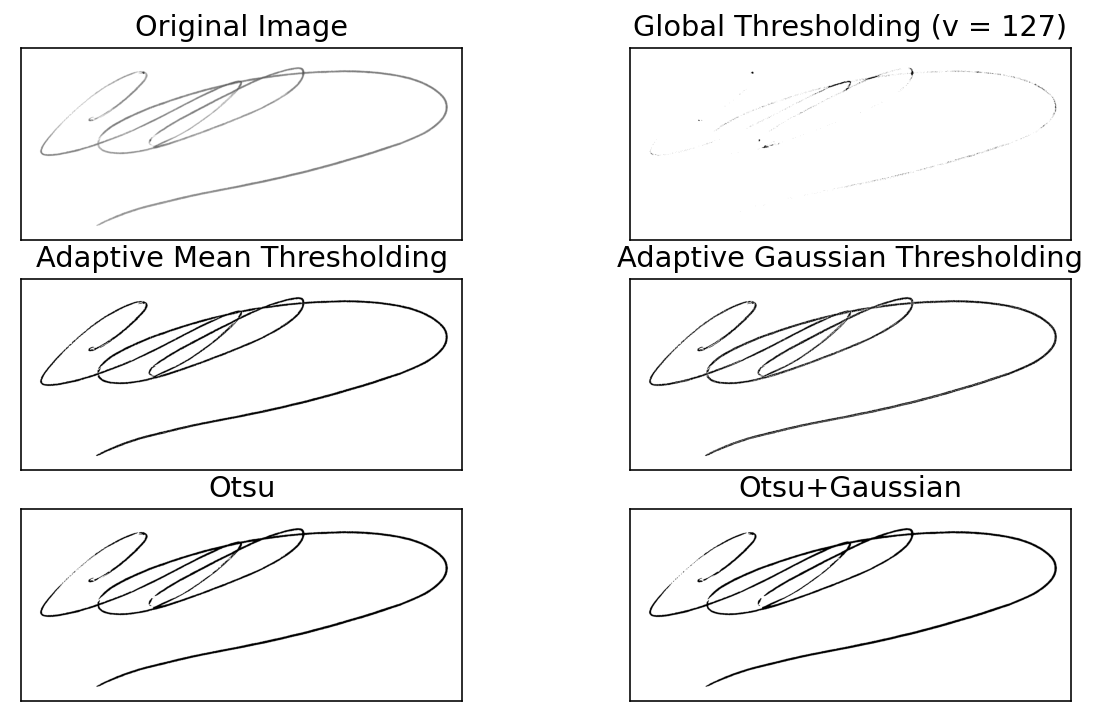

In [5]:
image_fp = random.choice(list(raw_dataset))
img = Image.open(image_fp)
preprocess_choose(img)

## Visualización del dataset

Es importante a la hora de encarar un problema de Machine Learning visualizar los datos para ver que forma tienen. Es un error de principiante aventurarse a implementar sin visualizar que pinta tienen.
La grilla de imágenes abajo impresa muestra firmas originales en la primera fila y firmas de otros autores en las filas subsiguientes (el título es el id del autor de la firma).

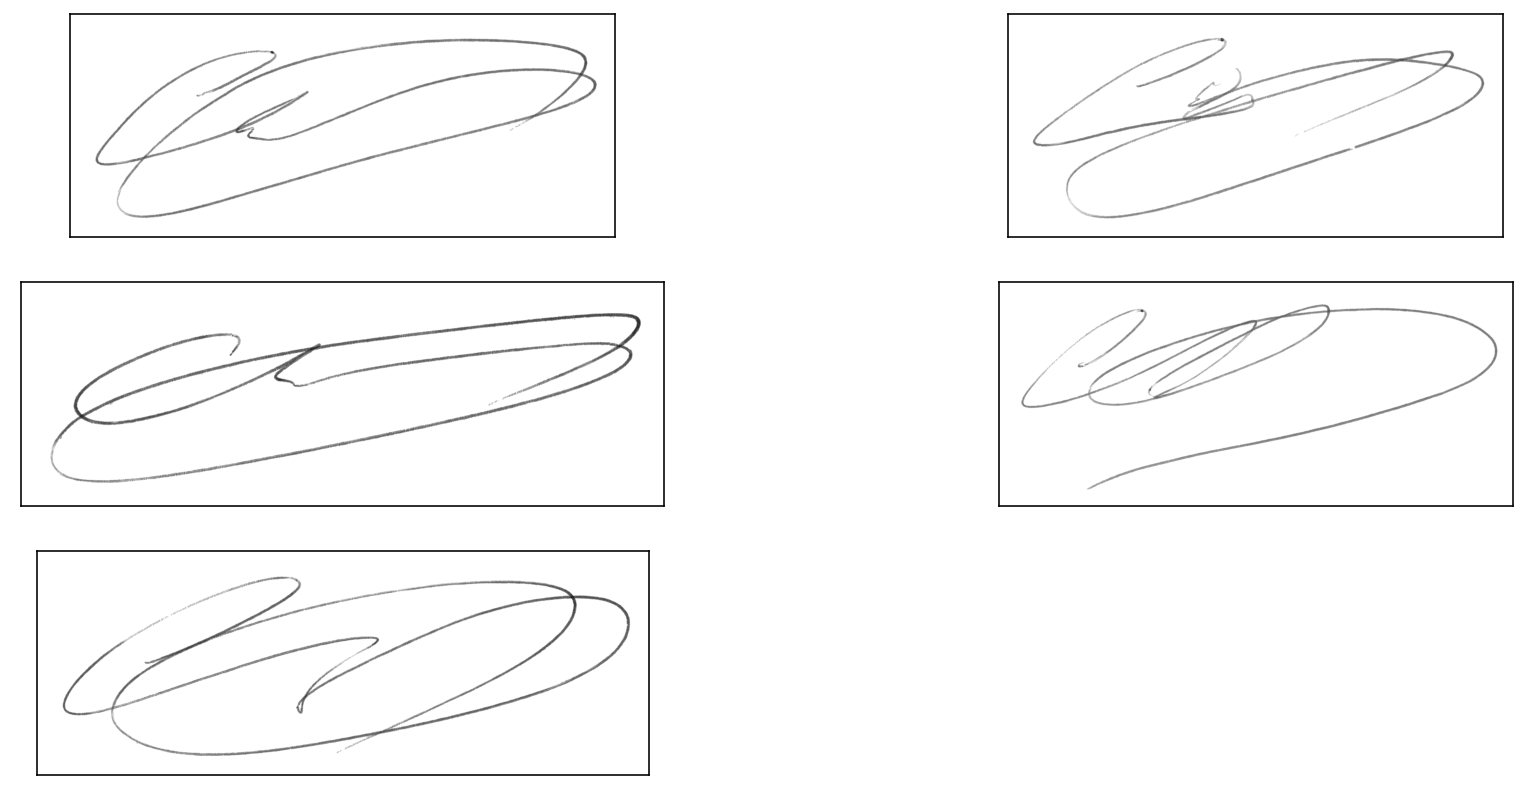

In [6]:
""" Show dataset """
author = ds_sigcomp2009.get_y(image_fp)
images_fp = [f for f in raw_dataset if ds_sigcomp2009.get_y(f)==author ]

imgs = [ds_sigcomp2009.get_x(f) for f in images_fp]
plot_images_grid(imgs,width=2, figsize=(15,7))

In [9]:
""" Preprocess dataset. """
empty_dir(PREPROCESSED_PATH)

Are you sure to delete ./data/parodi_out/preproc? ['yes' for yes]
yes


In [7]:
%%time
def f(x): return preproc_pipeline(PREPROCESSED_PATH, ds_sigcomp2009.get_x, x)
preprocess_dataset = parallel(f,raw_dataset)
len(preprocess_dataset)

CPU times: user 43.6 ms, sys: 51.3 ms, total: 95 ms
Wall time: 754 ms


60

In [5]:
""" Load preprocessed dataset. """
preprocess_dataset = L(get_fns(PREPROCESSED_PATH))
print("Lodaded {} files.".format(len(preprocess_dataset)))

Lodaded 60 files.


## Preprocesamiento (cont.)

Además en el trabajo de procesamiento se decidió negar las imágenes, de modo que los bytes altos (255) correspondan a las firmas (esto lo hacemos porque muchos algoritmos como el de determinar el centro de masa toman al fondo como los bytes en 0).
Finalmente aquí abajo mostramos una imagen que ha pasado por el pipeline de preprocesamiento:

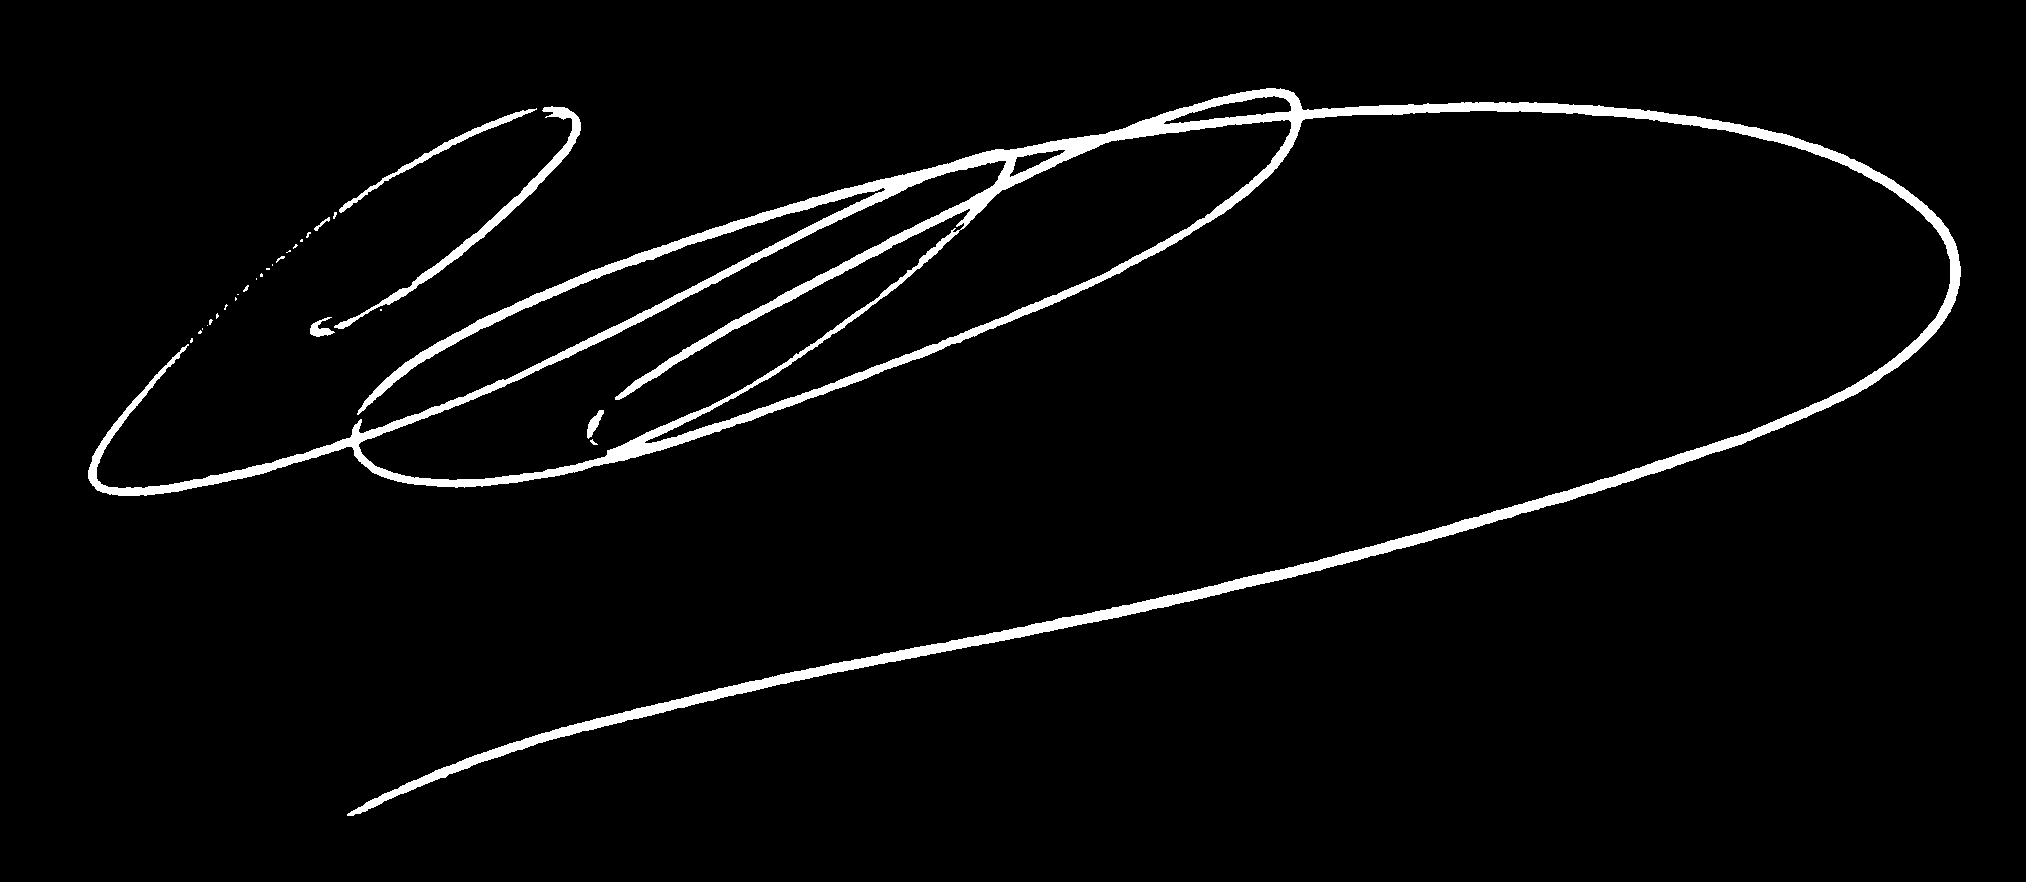

In [6]:
""" Show preprocessed image. """
image_fp = random.choice(preprocess_dataset)
img_preprocessed = Image.open(image_fp)
img_preprocessed

## Data Augmentation

En las secciones en donde entrenamos los clasificadores, podemos ver que el training score es significativamente más alto que el validation score en nuestros clasificadores y eso nos da la pauta de que tenemos problemas de sobreajuste.

Como explicamos en el marco teórico, el data aumentation es un proceso por el cuál obtenemos más datos para entrenar y validar, creando datos sintéticos. Tener más datos nos permite entrenar mejor, y es especialmente útil si tenemos problemas de sobreajuste.

En el caso de las imágenes podemos crear imágenes sintética aplicando transformaciones propias de este tipo de datos como transformaciones afines. En este caso aplicamos rotaciones y escalamiento independiente en los ejes verticales y horizontales.
Es importante aplicar transformaciones que no varíen cualidades semánticas de los datos. Por ejemplo si estuvieramos reconociendo animales tendría sentido espejar las imágenes horizontalmente pero no verticalmente. En este caso, y en el caso general del reconocimiento de texto los espejados le hacen perder sentido a los datos. De este modo también debemos cuidar que las rotaciones no sean significativas para no cambiar demasiado el sentido de los datos. Para ello decidimos rotaciones de entre \[-15, 15\] que juzgamos visualmente que no hacen perder sentido a las firmas. Del mismo modo los parámetros de escalamiento fueron seleccionados con un criterio de prueba/visualización.

Es de suma importancia aclarar que como particionamos por autores en la generación de conjuntos de validación es posible hacer 'data augmentation' antes de la separación en entrenamiento validación. De lo contrario se podrían incurrir en el problema metodológico de 'hermanamiento' del conjunto de datos, incluyendo muestras muy similares en entrenamiento y validación.

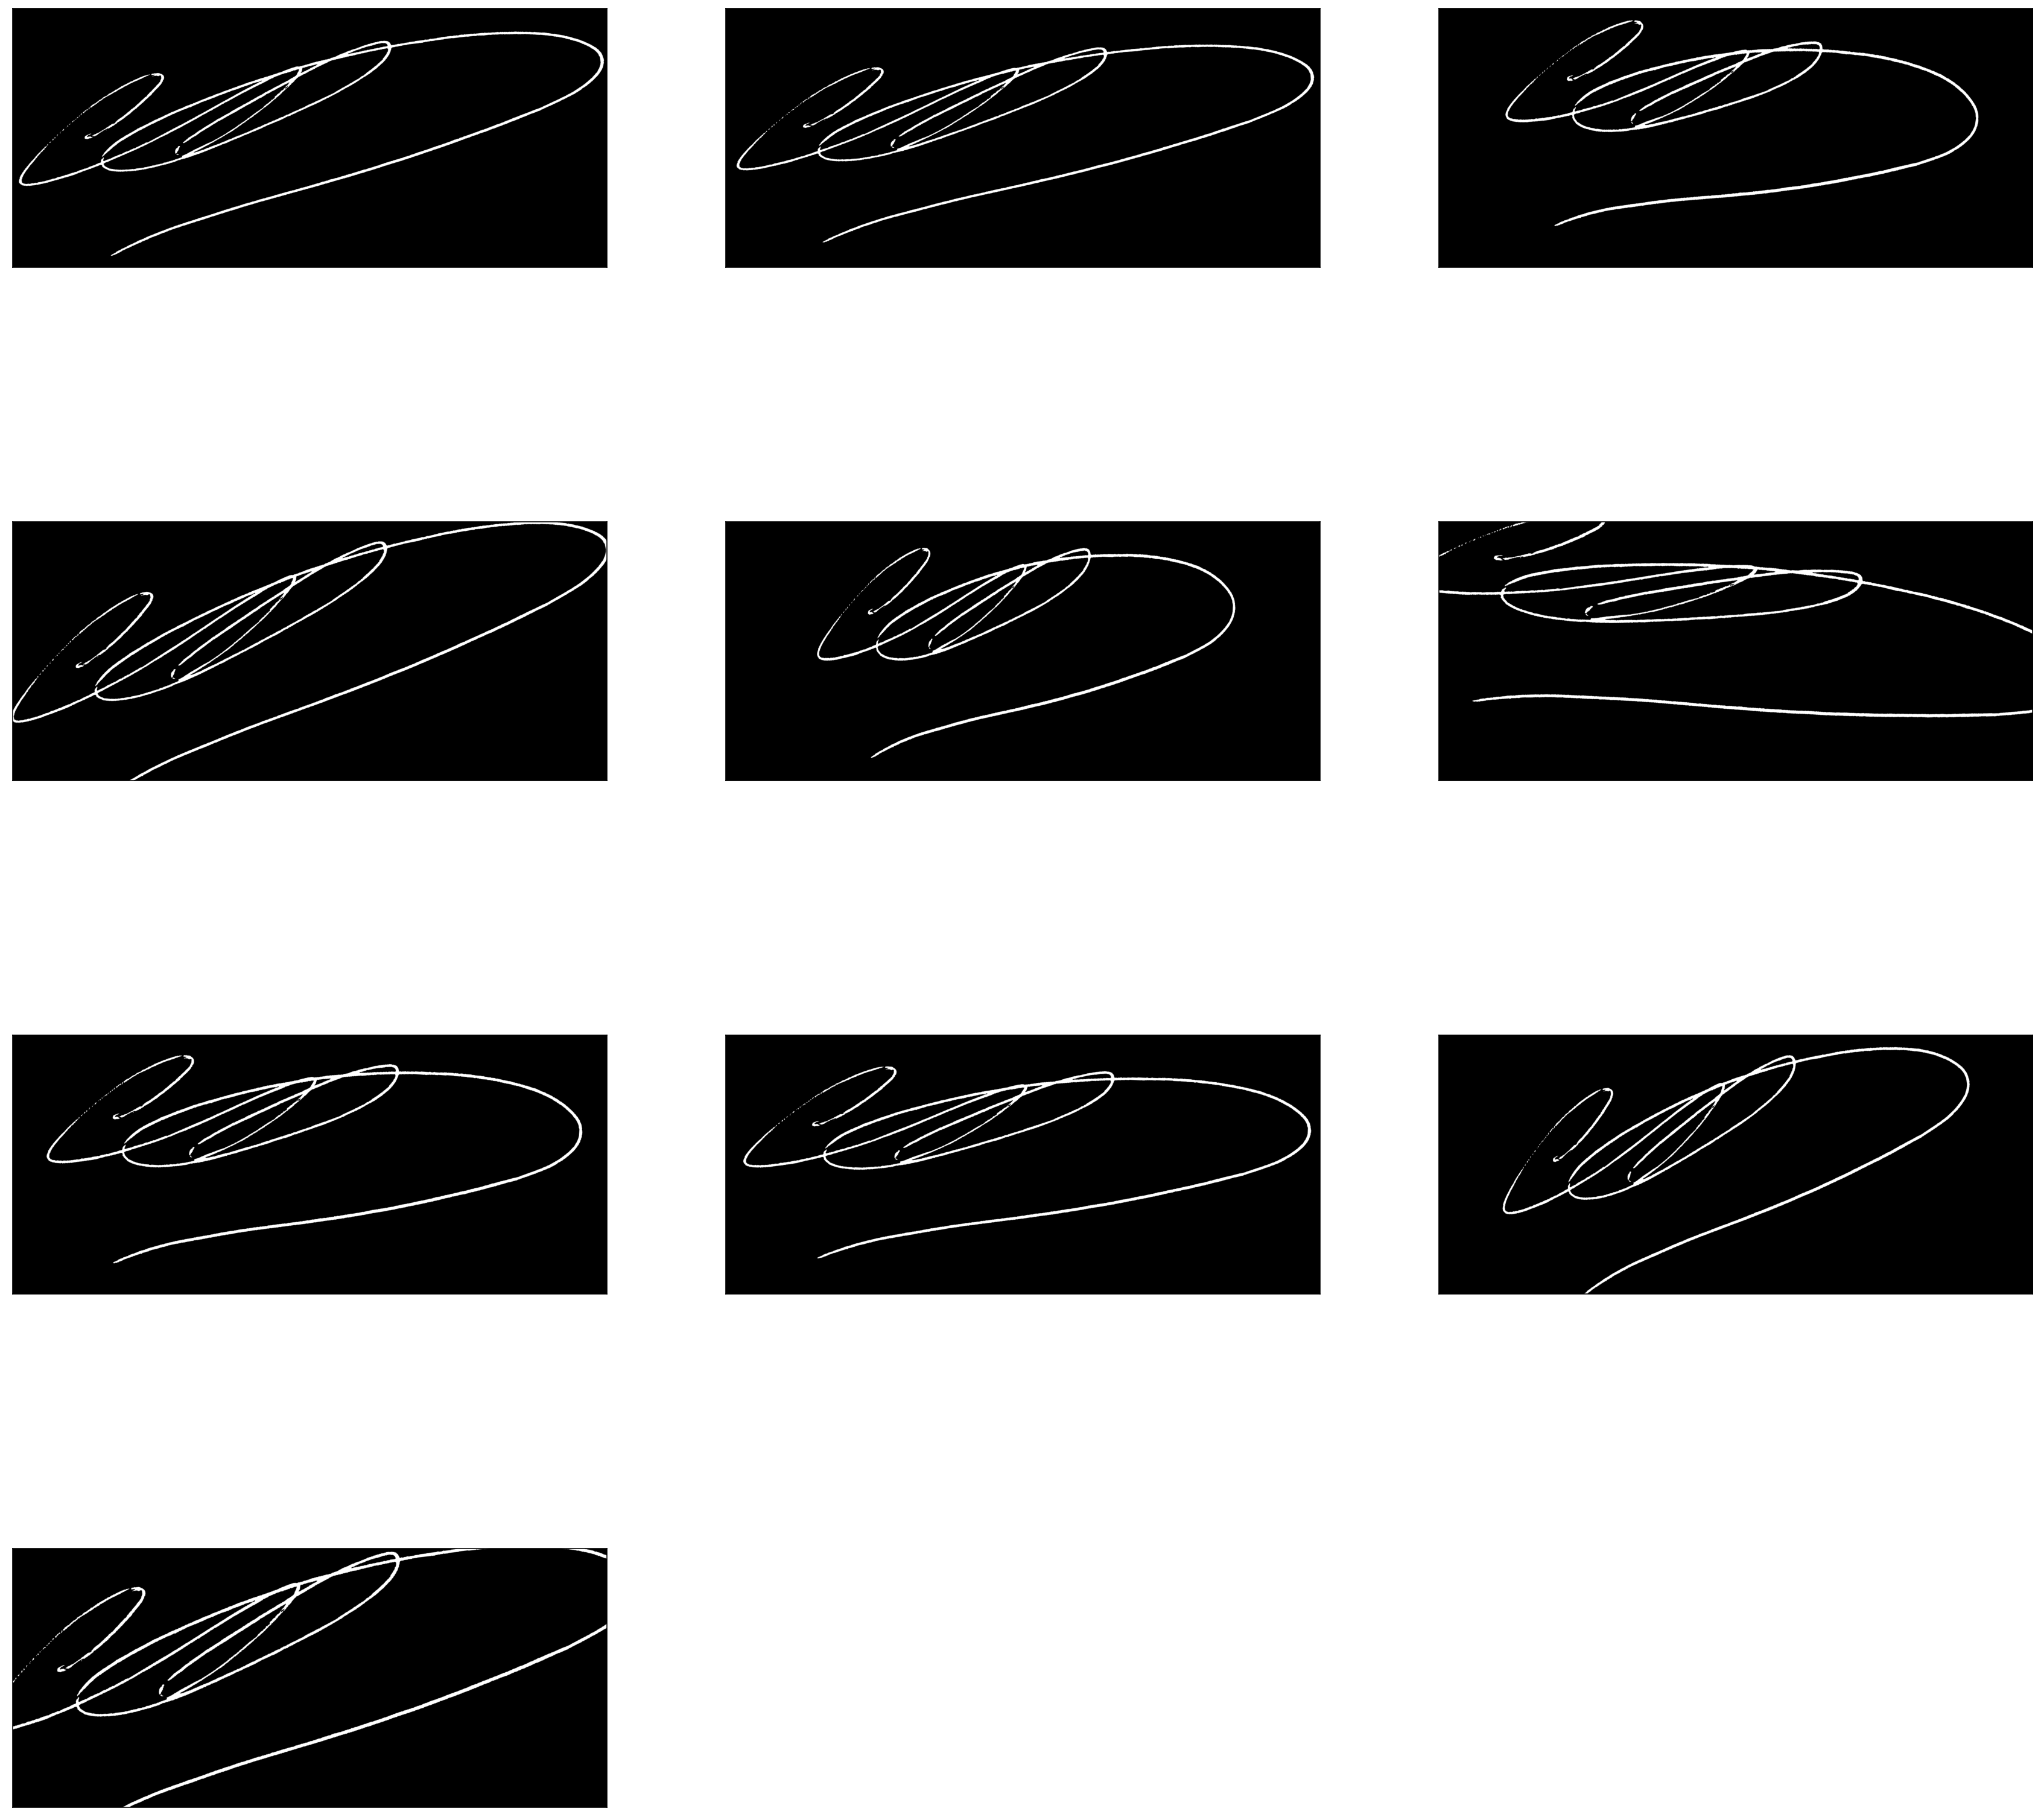

In [37]:
augmented_imgs = data_augmentation(get_x(image_fp), 10)
plot_images_grid(augmented_imgs, width=3, titles=None, figsize=(30,30))

## Extracción de features

Se ha implementado una clase que mantenga información de la grilla circular tal cómo se describi en la tesis de Marianela (cómo el ángulo, las características, un mapeo de cada píxel a la sección correspondiente).

La implementación hace la mayor parte de los loops necesarios gracias a operaciones vectoriales de numpy, valiéndose muchas veces de operaciones de broadcasting. Gracias a ello es posible hacer la extracción de features realmente rápido en "python" (las comillas es porque numpy realiza llamadas a código C/C++ optimizado).

Es importante que en cada paso de implementación se visualice para verificar si lo que se está haciendo es correcto, muchas veces se implementan algoritmos de extracción y clasificación que arrojan resultados finales desalentadores, pero es causa a errores de código en la extracción de características.

In [39]:
%%time
""" Calculate the feature Grid. """
grid = FastGrid(image_fp, ds_sigcomp2009.get_x, N_divisions=16)

CPU times: user 376 ms, sys: 28 ms, total: 404 ms
Wall time: 404 ms


En la siguiente imagen visualizamos las secciones de la grilla: dentro de la clase un miembro almacena las coordenadas de los píxeles de cada sección y hemos coloreado dichos píxeles de blanco, además hemos coloreado de gris el vector inicial de la sección para verificar que lo estamos calculando correctamente.

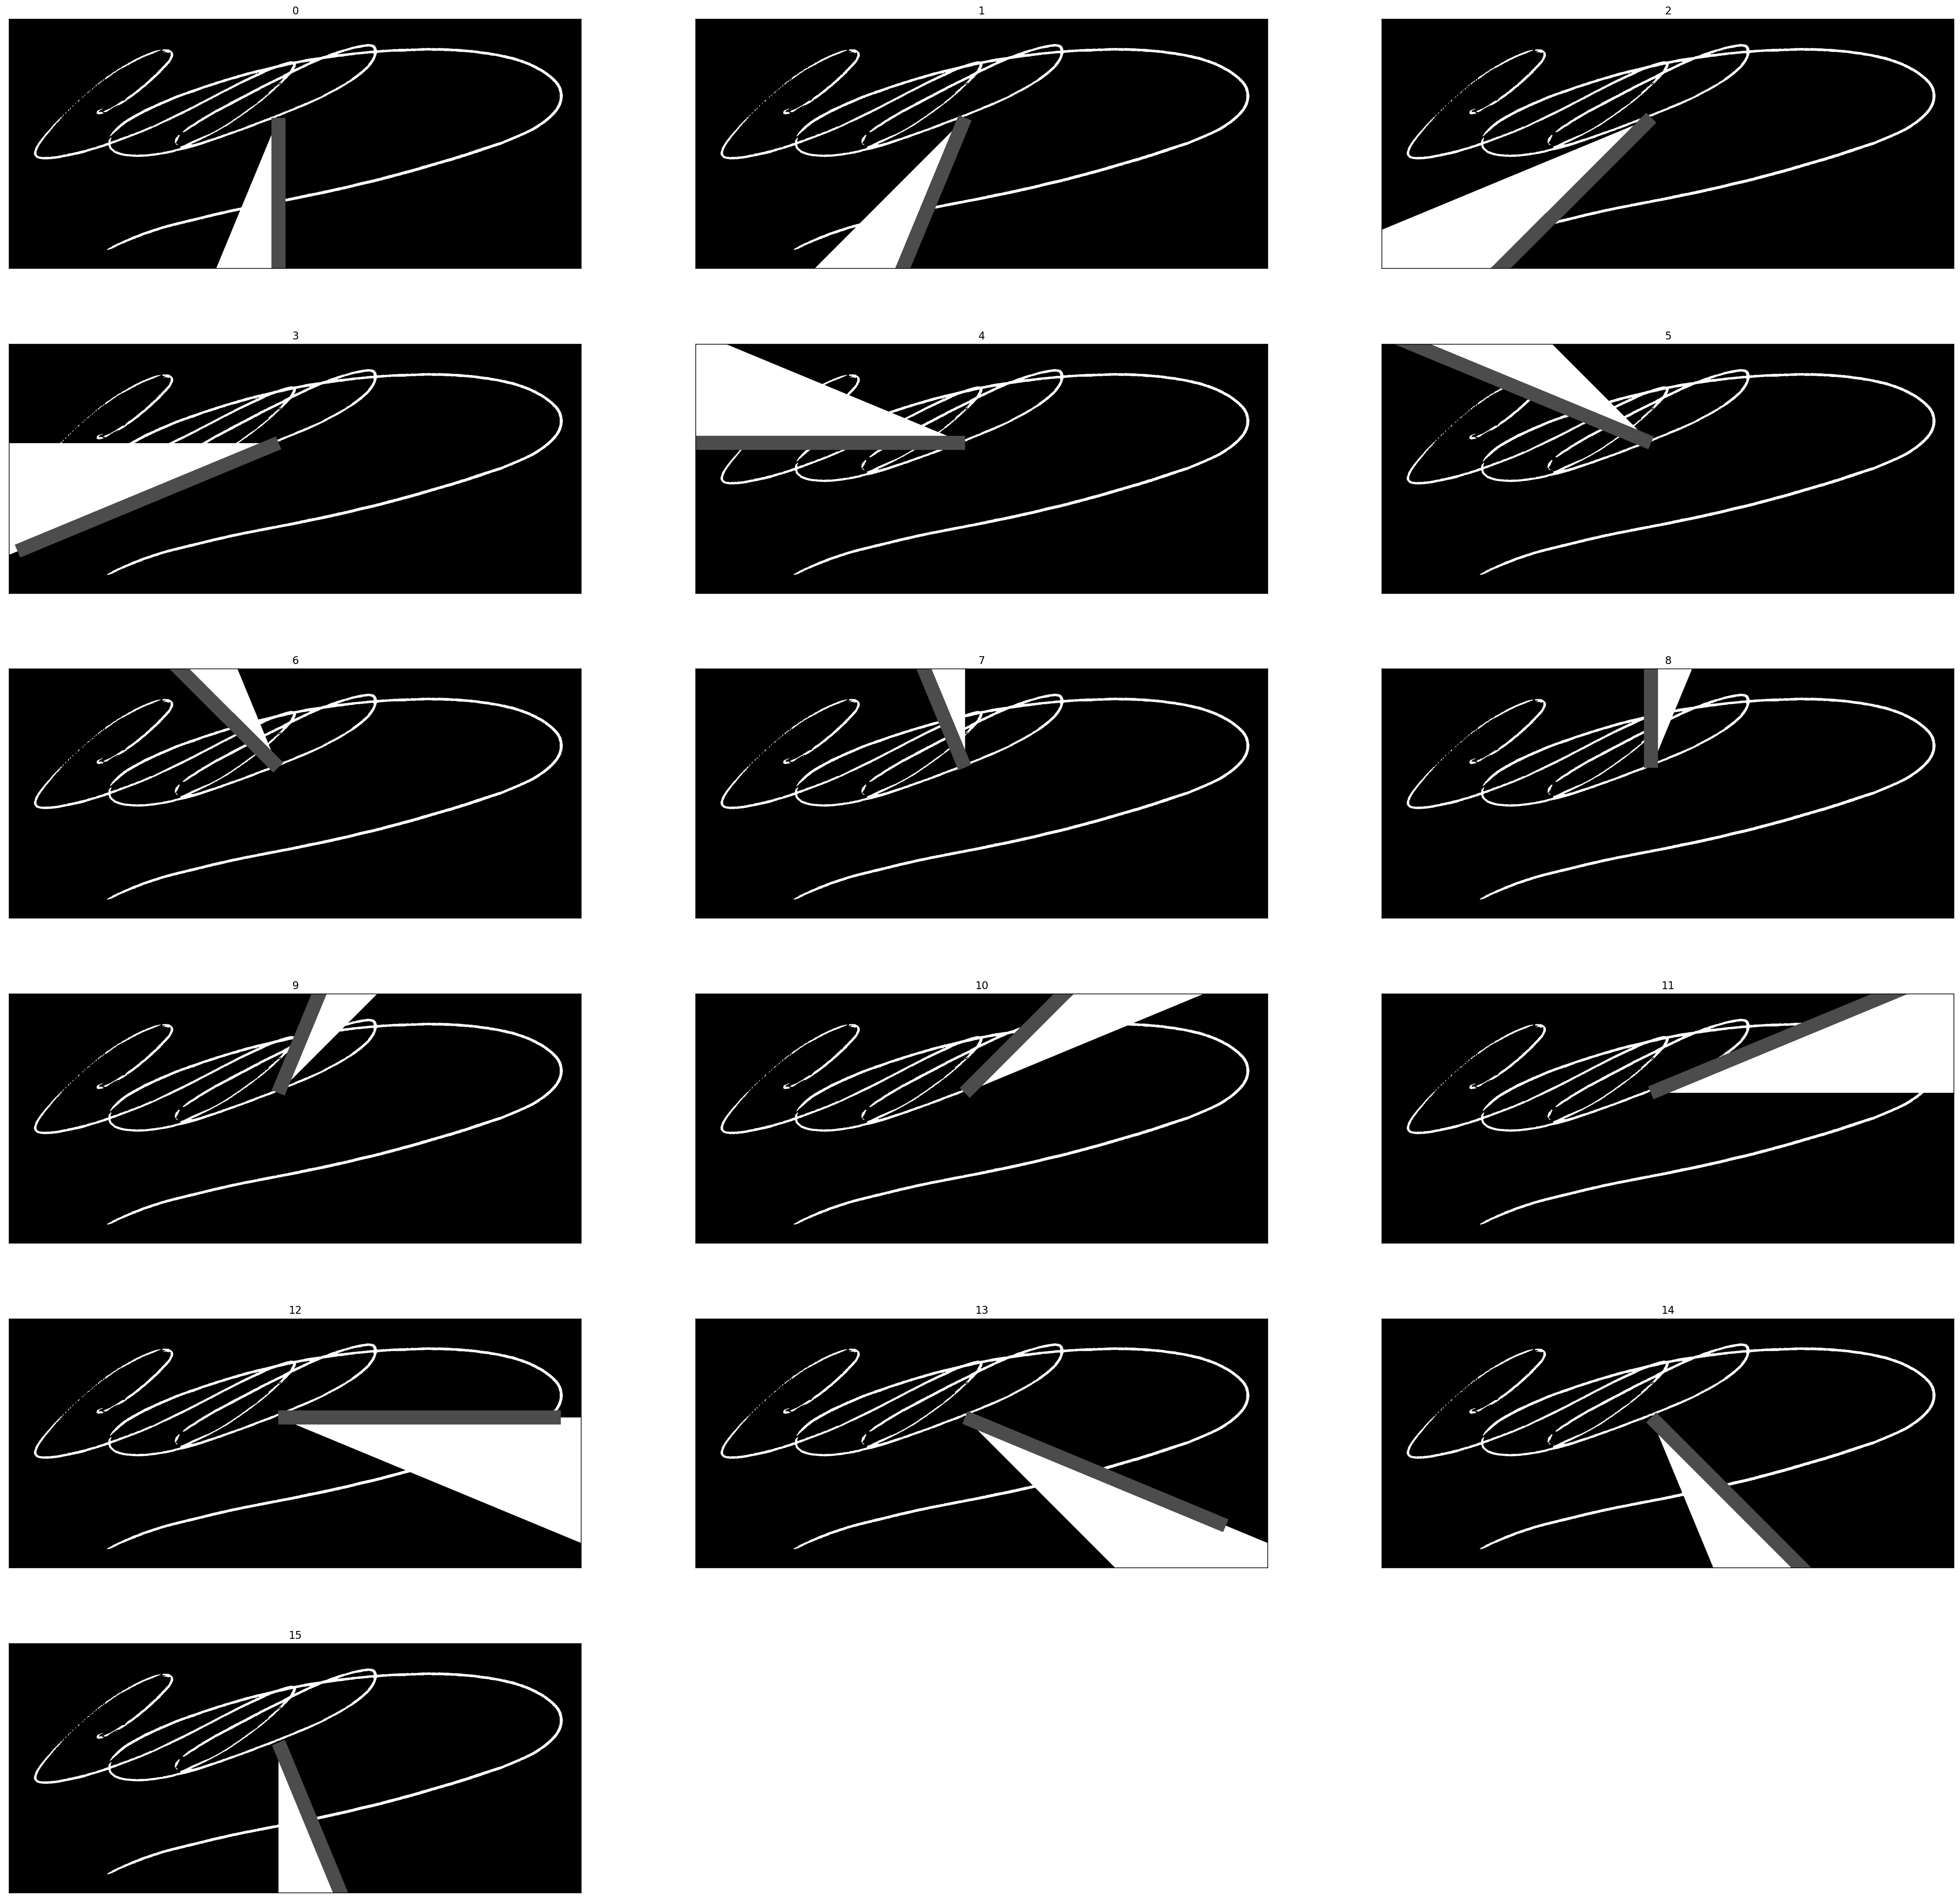

In [40]:
""" Show the image division grid. """
images = []
titles = []
for idx_to_modify in range(grid.N_divisions):
    np_img_copy = grid.npimg.copy()
    np_img_copy[grid.angs==idx_to_modify]=255
    img = Image.fromarray(np_img_copy)
    mark_img_line(img, grid.center, grid.center + (grid.idx_to_vector_end[idx_to_modify]-grid.center)*1000,w=50 )
    images.append(img)
    titles.append(idx_to_modify)
titles, images = zip(*sorted(zip(titles, images)))

plot_images_grid(images,width=3, titles=titles, figsize=(40,40))

En la imágen de abajo visualizamos la imágenes graficando el centro de masa, las secciones y los centros de masa de cada una (así como una línea entre estos y el centro de masa total).

También imprimimos las features para corroborar que tienen números que más o menos esperaríamos (distancia del centro de masa de la sección al de la imágen, ángulo relativo al inicio de sección, cantidad de píxeles de firma).

idx_to_dist
(0, 314.8963693195226)
(1, 432.90173267371455)
(2, 640.0642427609627)
(3, 465.87346028156696)
(4, 394.11774836023545)
(5, 292.1128379495593)
(6, 158.97810534071982)
(7, 147.16017335672518)
(8, 172.91994716274968)
(9, 251.90588774054746)
(10, 355.6516683374535)
(11, 863.3731081271368)
(12, 716.0703889251473)
(13, 414.10640167974617)
(14, 314.4441165207252)
(15, 289.5765291930118)

idx_to_angle
(0, 12.109469965203266)
(1, 13.727154679822105)
(2, 4.529785039714852)
(3, 12.995101649877572)
(4, 9.85096323169582)
(5, 7.0153107874616225)
(6, 10.827816990802217)
(7, 10.79449658371146)
(8, 12.220999427064205)
(9, 13.43922721432526)
(10, 13.711154006690284)
(11, 11.2468898556793)
(12, 8.871281738110214)
(13, 9.219458311086159)
(14, 10.330267429205641)
(15, 10.959767128121669)

idx_to_pixel_count
(0, 1312.0)
(1, 2450.0)
(2, 2040.0)
(3, 13010.0)
(4, 8600.0)
(5, 4029.0)
(6, 1998.0)
(7, 1711.0)
(8, 2240.0)
(9, 2637.0)
(10, 7452.0)
(11, 5475.0)
(12, 5341.0)
(13, 2303.0)
(14, 1388.0)
(15, 

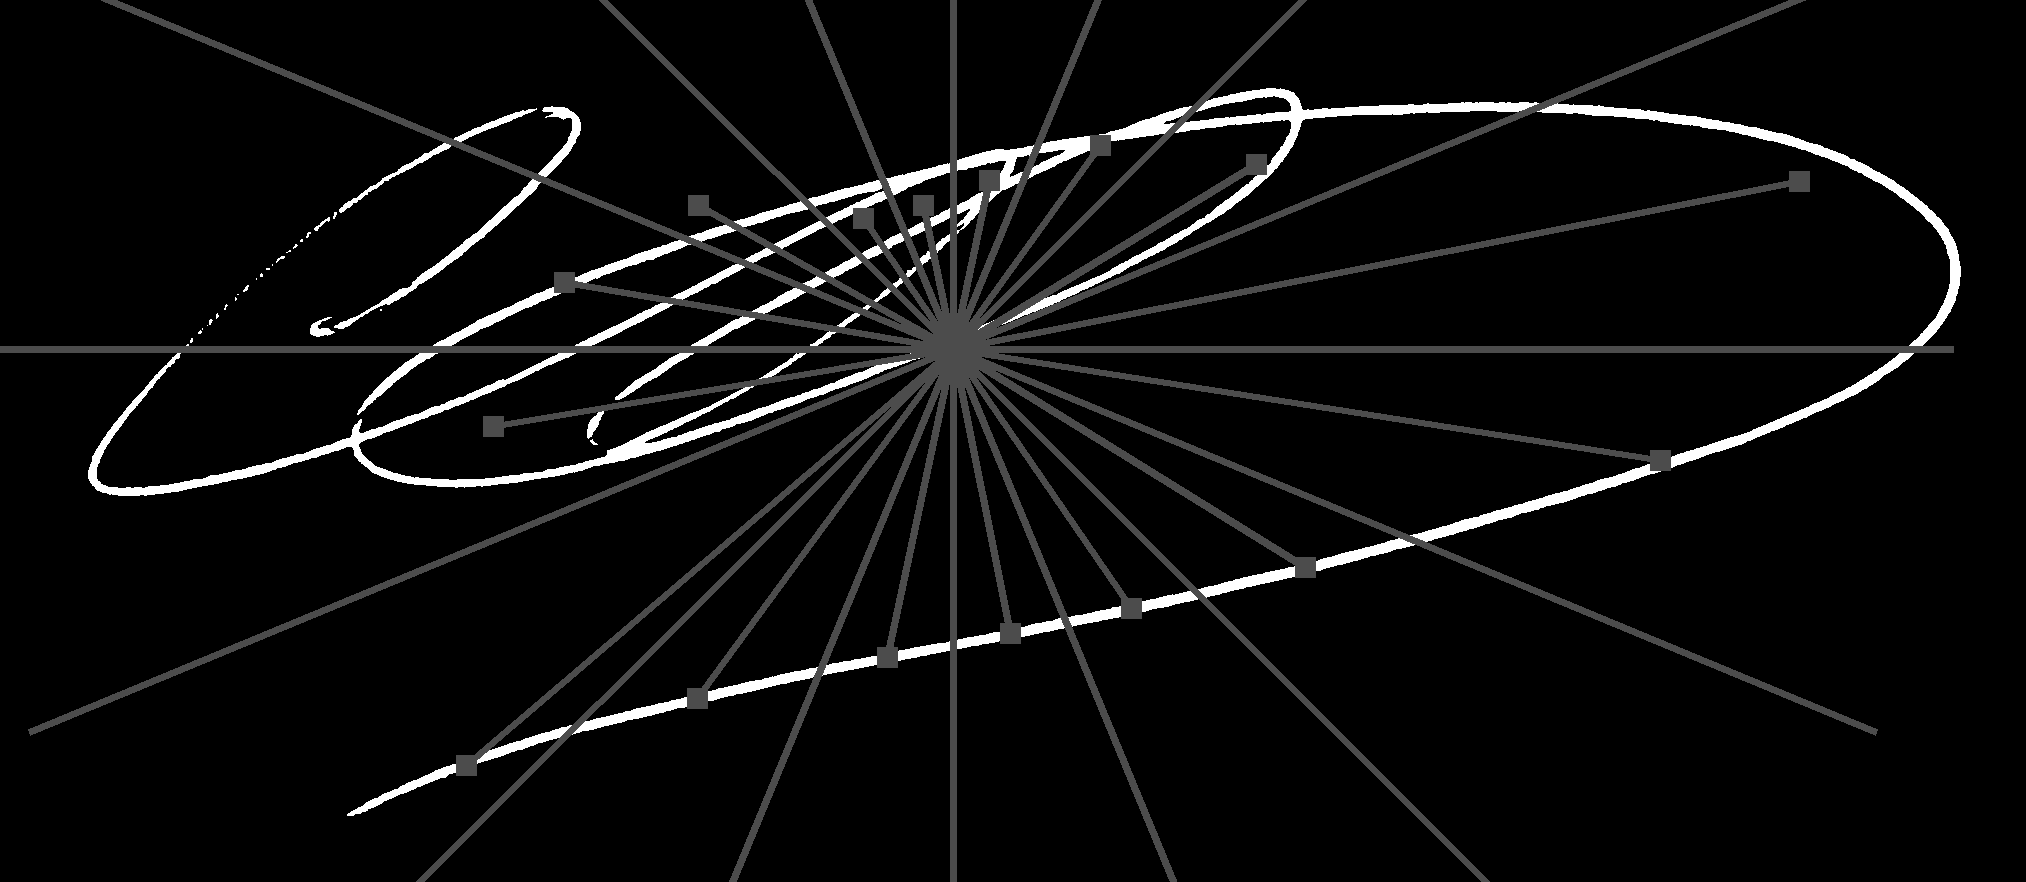

In [41]:
""" Show THE center + each division center + idx_to_dist + idx_to_vector_end + idx_to_angle """
def show_grid_data(gdata):
    img = Image.open(gdata.image_fp)
    mark_img(img, gdata.center[0], gdata.center[1], w=15)
    for idx in range(grid.N_divisions):
        mark_img(img,gdata.idx_to_center[idx][0],gdata.idx_to_center[idx][1],w=10)
        mark_img_line(img, gdata.center, gdata.idx_to_center[idx])
        mark_img_line(img, gdata.center, gdata.center + (gdata.idx_to_vector_end[idx]-gdata.center)*1000 )
        
    
    print("idx_to_dist")
    print('\n'.join(map(str,enumerate(list(gdata.idx_to_dist)))))
    print("\nidx_to_angle")
    print('\n'.join(map(str,enumerate(list(gdata.idx_to_angle*180/pi)))))
    print("\nidx_to_pixel_count")
    print('\n'.join(map(str,enumerate(list(gdata.idx_to_pixel_count)))))
    
    return img

show_grid_data(grid)

Imprimimos los dos puntos mas distantes de la firma. Esto es utilizado para calcular el radio de la firma, utilizado en la tesis de Marianela. Nuestro algoritmo lo hace calculando y considerando sólo los puntos de la cápsula convexa. Lo que optimiza mucho el tiempo debido a que en general los puntos de una firma no pertenecen a ella.

('R dist: ', 1883.9660294177281)


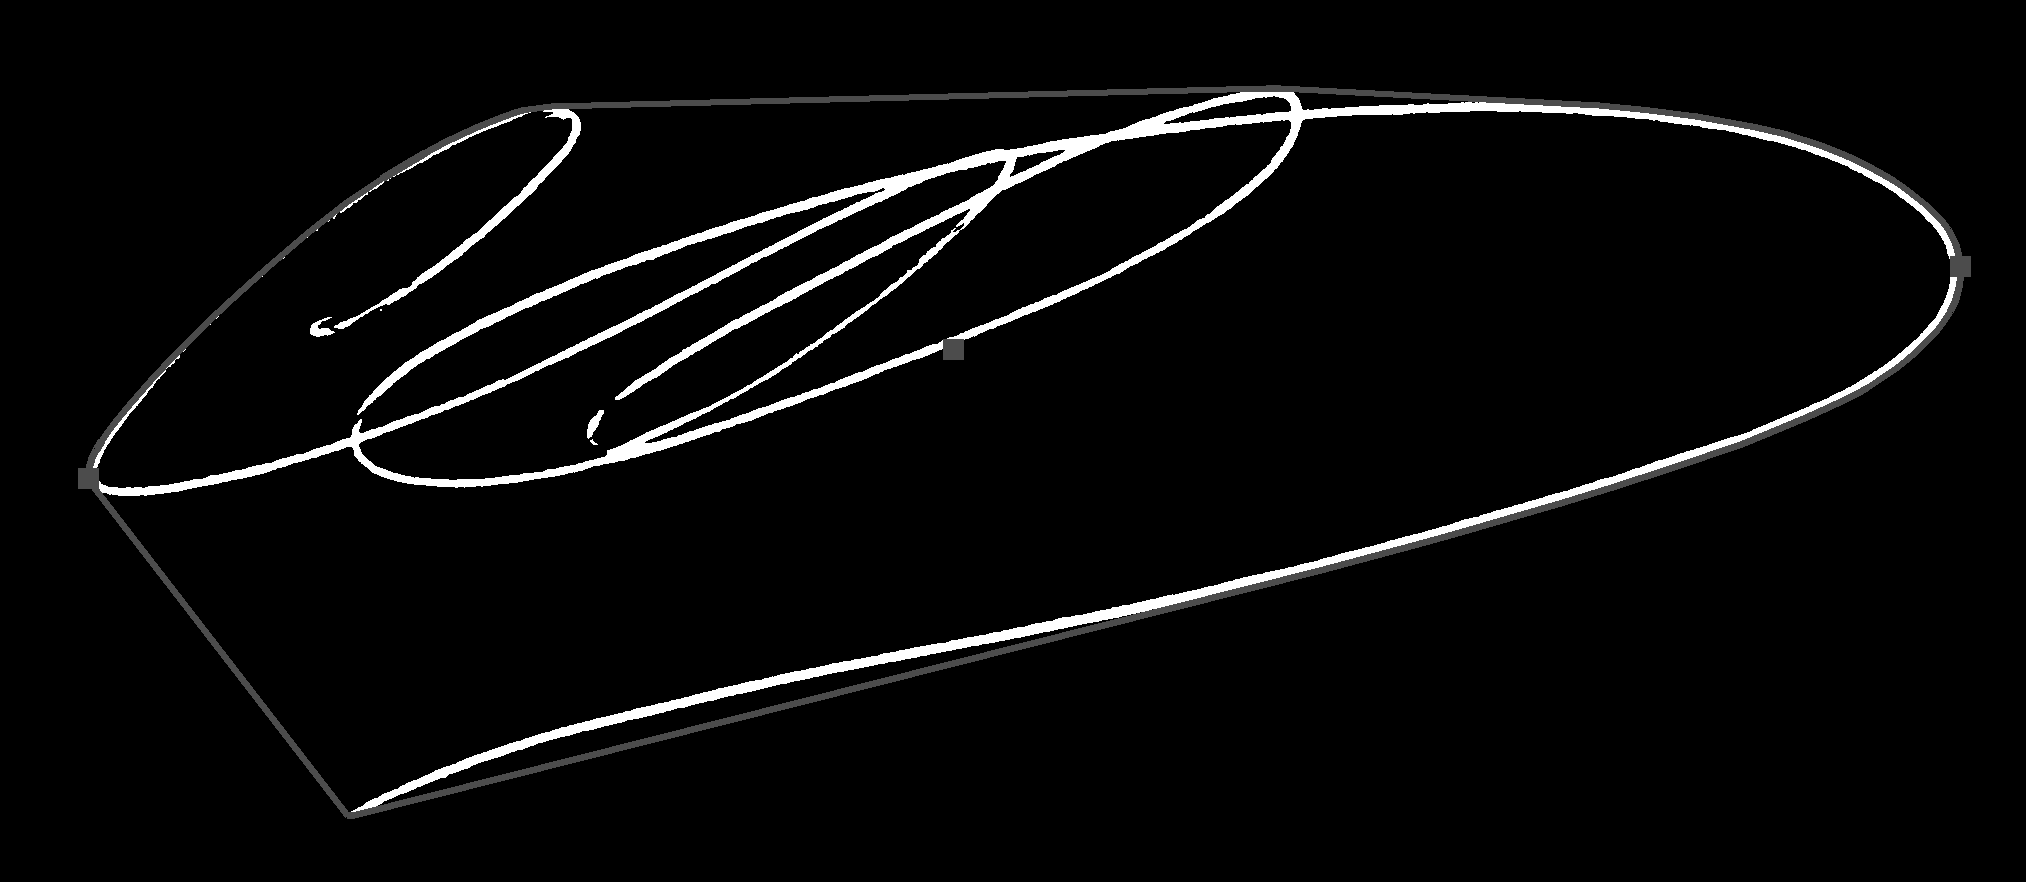

In [42]:
""" Show the CHULL + 2 farest point + distance between them """
def show_chull(grid):
    img = Image.open(grid.image_fp)
    for i in range(len(grid.chull_pts)):
        mark_img_line(img, grid.chull_pts[i-1], grid.chull_pts[i])
    print(('R dist: ', grid.R))
    mark_img(img,grid.farest[0][0],grid.farest[0][1], w=10)
    mark_img(img,grid.farest[1][0],grid.farest[1][1], w=10)
    mark_img(img,grid.center[0],grid.center[1],w=10)
    return img

show_chull(grid)

Utilizamos la clase GridData para guardar la data de la grilla en un archivo pkl.
Verificamos que la data de Grid se copia bien a GridData y que el proceso de guardar/cargar es correcto.

In [43]:
""" Check save/load GridData works ok. """
grid.save('./features22.pkl')
lgrid = FastGrid.load('./features22.pkl')
lgrid.__getstate__()==grid.__getstate__()

True

Con este código extraeríamos las features de nuestro dataset preprocesado. Es mejor utilizar *parallel_process_job*, porque es un proceso que dura mucho.

In [17]:
print(('N_divisions:', grid.N_divisions))
print(('R:', grid.R))
grid.features()

('N_divisions:', 16)
('R:', 1600.7029705726168)


(3, 16)

In [35]:
""" Extract the features. """
empty_dir(FEATURES_PATH)

Are you sure to delete ./data/parodi_out/features? ['yes' for yes]
yes


In [7]:
%%time
def f(x): return feature_extract_pipeline(FEATURES_PATH,ds_sigcomp2009.get_x,16,x)
    
features_dataset = parallel(f,preprocess_dataset, progress=True)
#features_dataset = list(map(f,preprocess_dataset))
len(features_dataset)

CPU times: user 173 ms, sys: 70.6 ms, total: 244 ms
Wall time: 9.93 s


60

# Clasificación

La extracción de características genera un archivo .pkl por cada imágen con el mismo nombre conteniendo el objeto GridData con las features extraídas.
Chequeamos ciertas propiedades (cantidad de archivos, de divisiones, de firmas, de features).

In [16]:
""" Load features file dataset. """
features_dataset = glob.glob(FEATURES_PATH+'/*.pkl')
len(features_dataset)

60

In [23]:
X = np.array([FastGrid.load(f).features() for f in features_dataset])
X.shape

(60, 3, 16)

En la tesina de Marianela se propone aplicar DFT a cada vector de features para proveer robustez a la invariancia de a la rotación.

In [29]:
if FEATURE_FFT_ON: 
    X = np.abs(np.fft.fft(X))

## Data normalization

Al igual que \[TESIS-MARIANELA\] nuestas features tienen escalamientos teniendo en cuenta el radio de la firma y/o por la cantidad de diviones usadas para hacerlo independiente de estas magnitudes. Nosotros hemos hecho algo parecido (ver método features de clase FastGrid en *features_grid.py*). A la cantidad de píxeles la escalamos por (N_division / R^2) tratando de hacerla independiente de la superficie de la imágenes y la cantidad de divisiones; a la distancia entre centros de masa la dividimos por R tratando de hacerla independiente del tamaño de la imágen y al ángulo del centro de masa al inicio de la sección lo multiplicamos por N_division tratando de hacerla independiente de la cantidad de divisiones.

En \[TESIS-MARIANELA\] tenemos 3 features con unidades distintas (cantidad de píxeles, ángulos, distancia) por lo que sería razonable aplicar algún método de preprocesamiento (además que existen clasificadores que asumen normalización de los datos). En el marco teórico hemos explayado los métodos de normalización de datos aplicable a las features antes de enviarlas al clasificador. 

La distribución de los datos vemos que las dos primeras features (cantidad de píxeles por sección y distancia entre el centro de masa de la sección y de la firma) son distribuciones skewed.
No obstante aplicaremos StandardScaler ya que separan mejor estas distribuciones, haciéndo que sea más fácil de aprender con métodos como SVM.


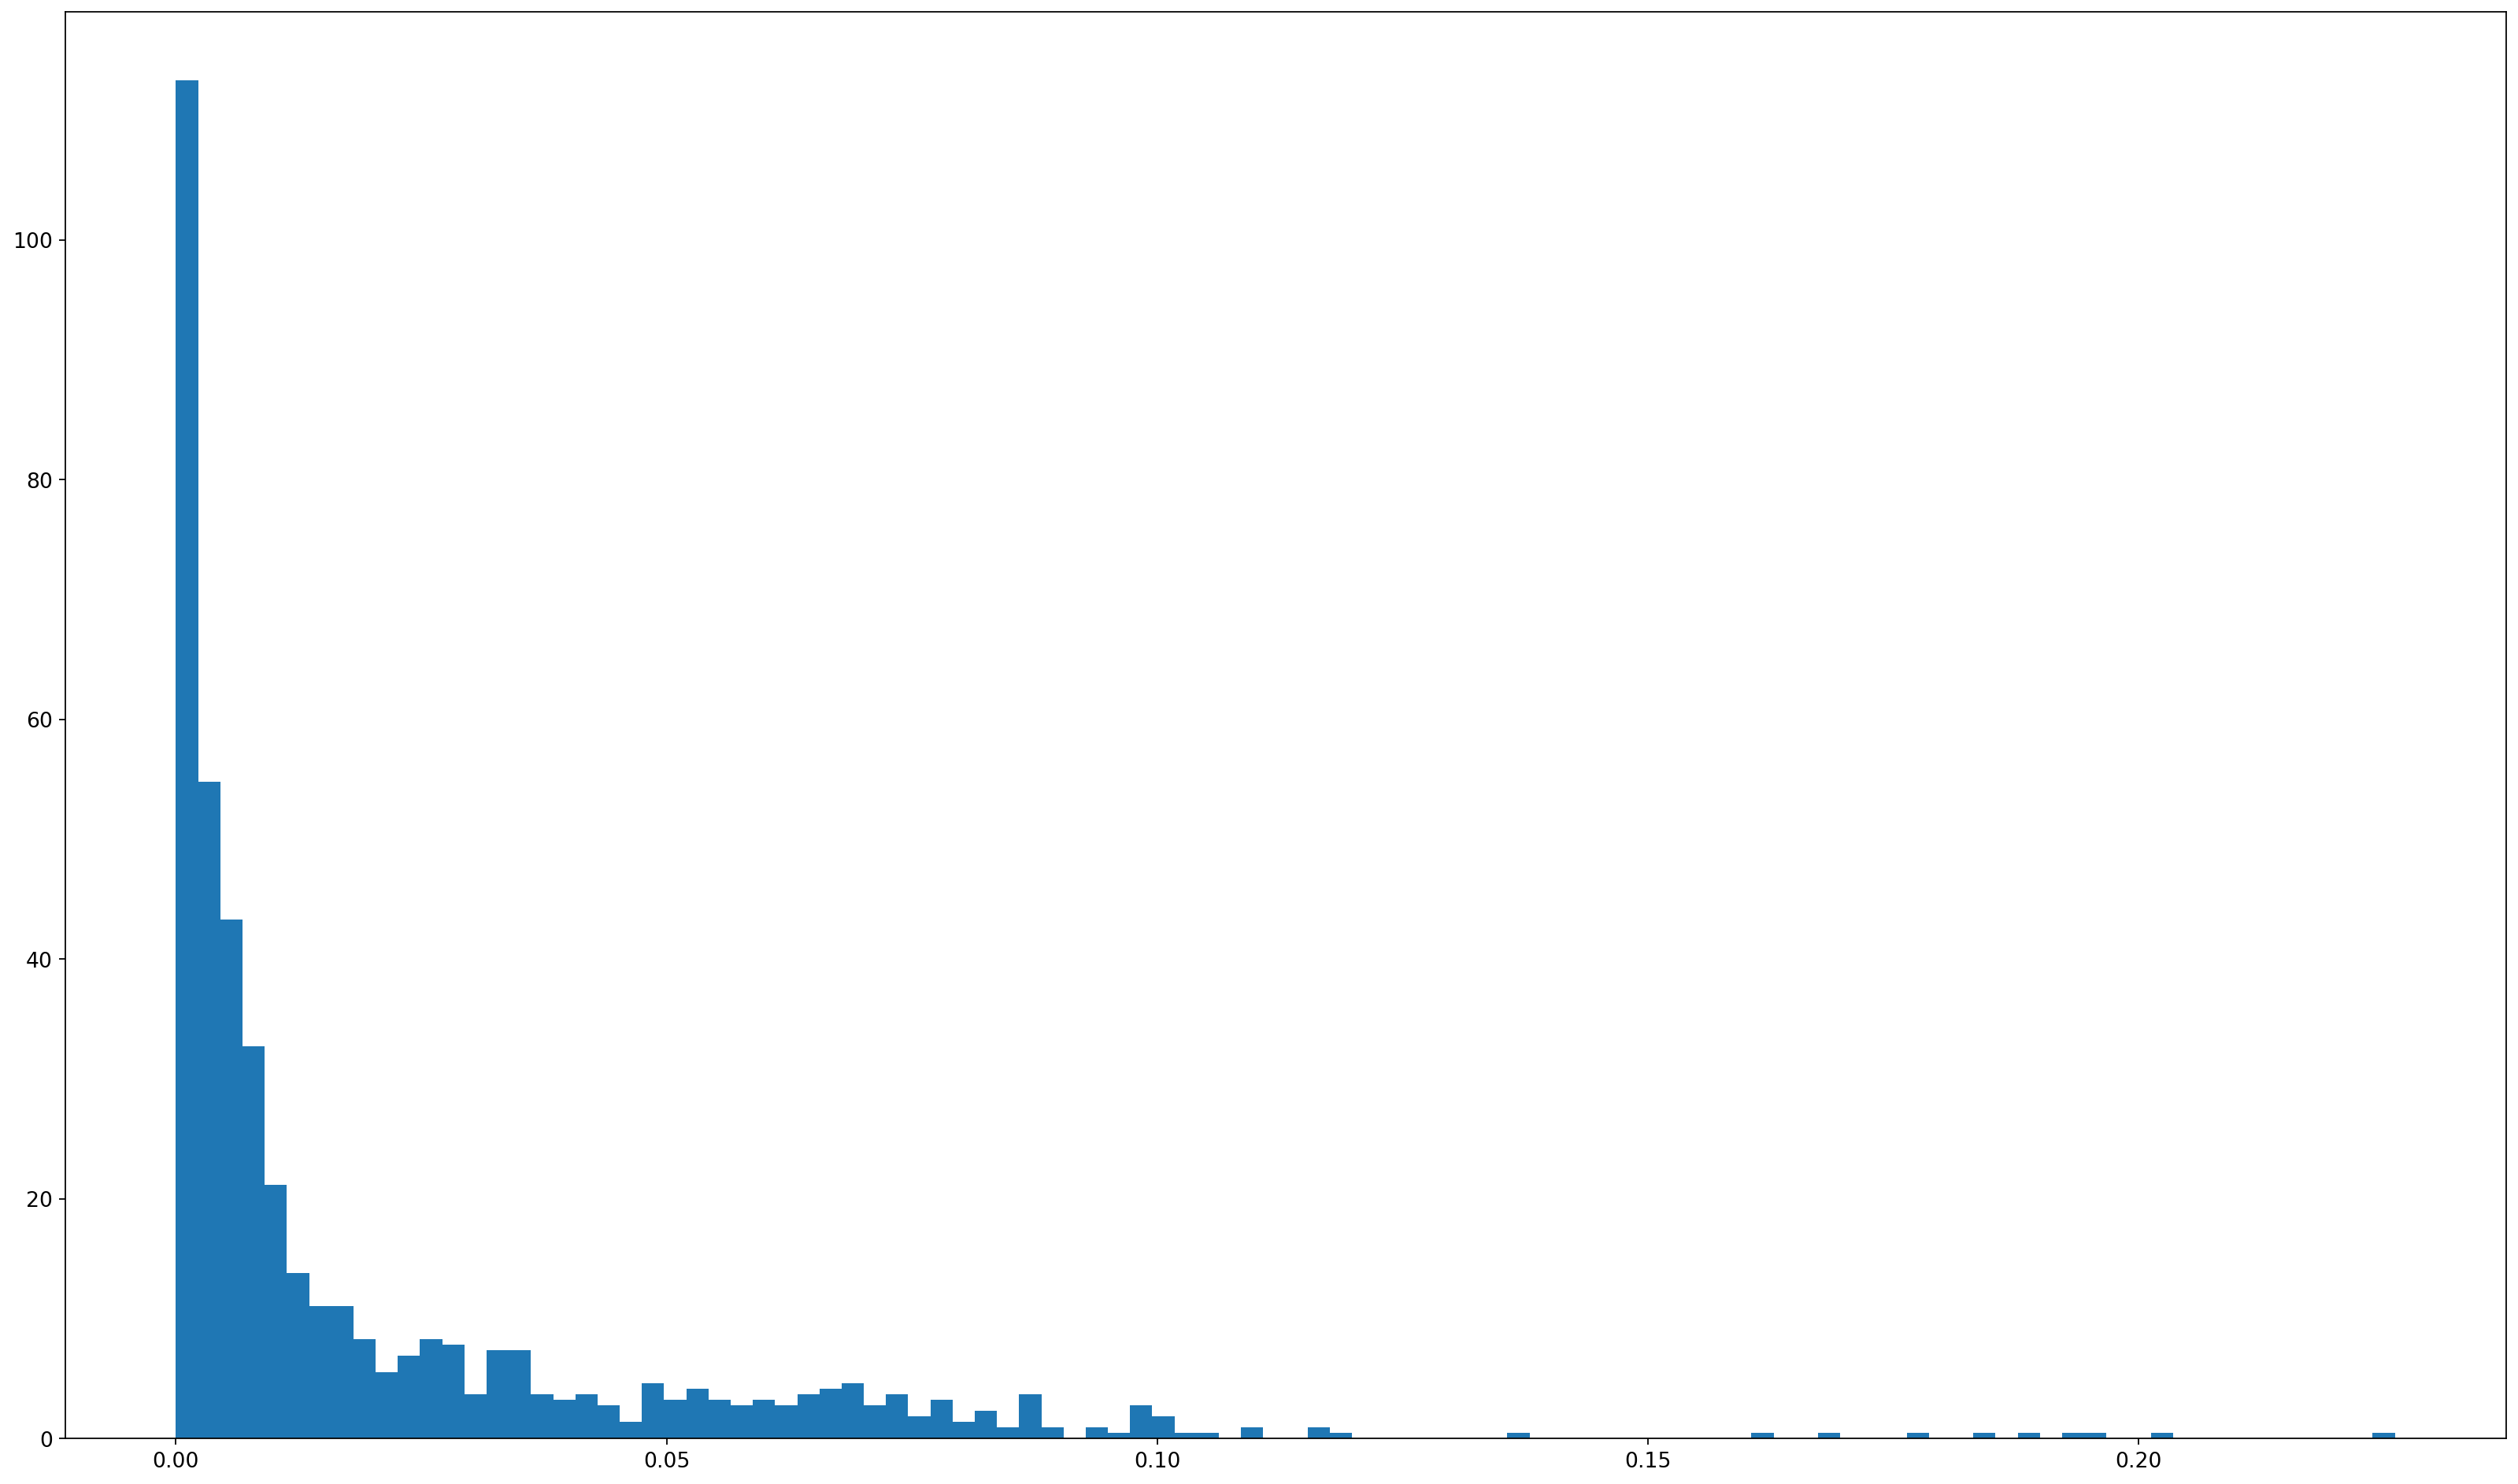

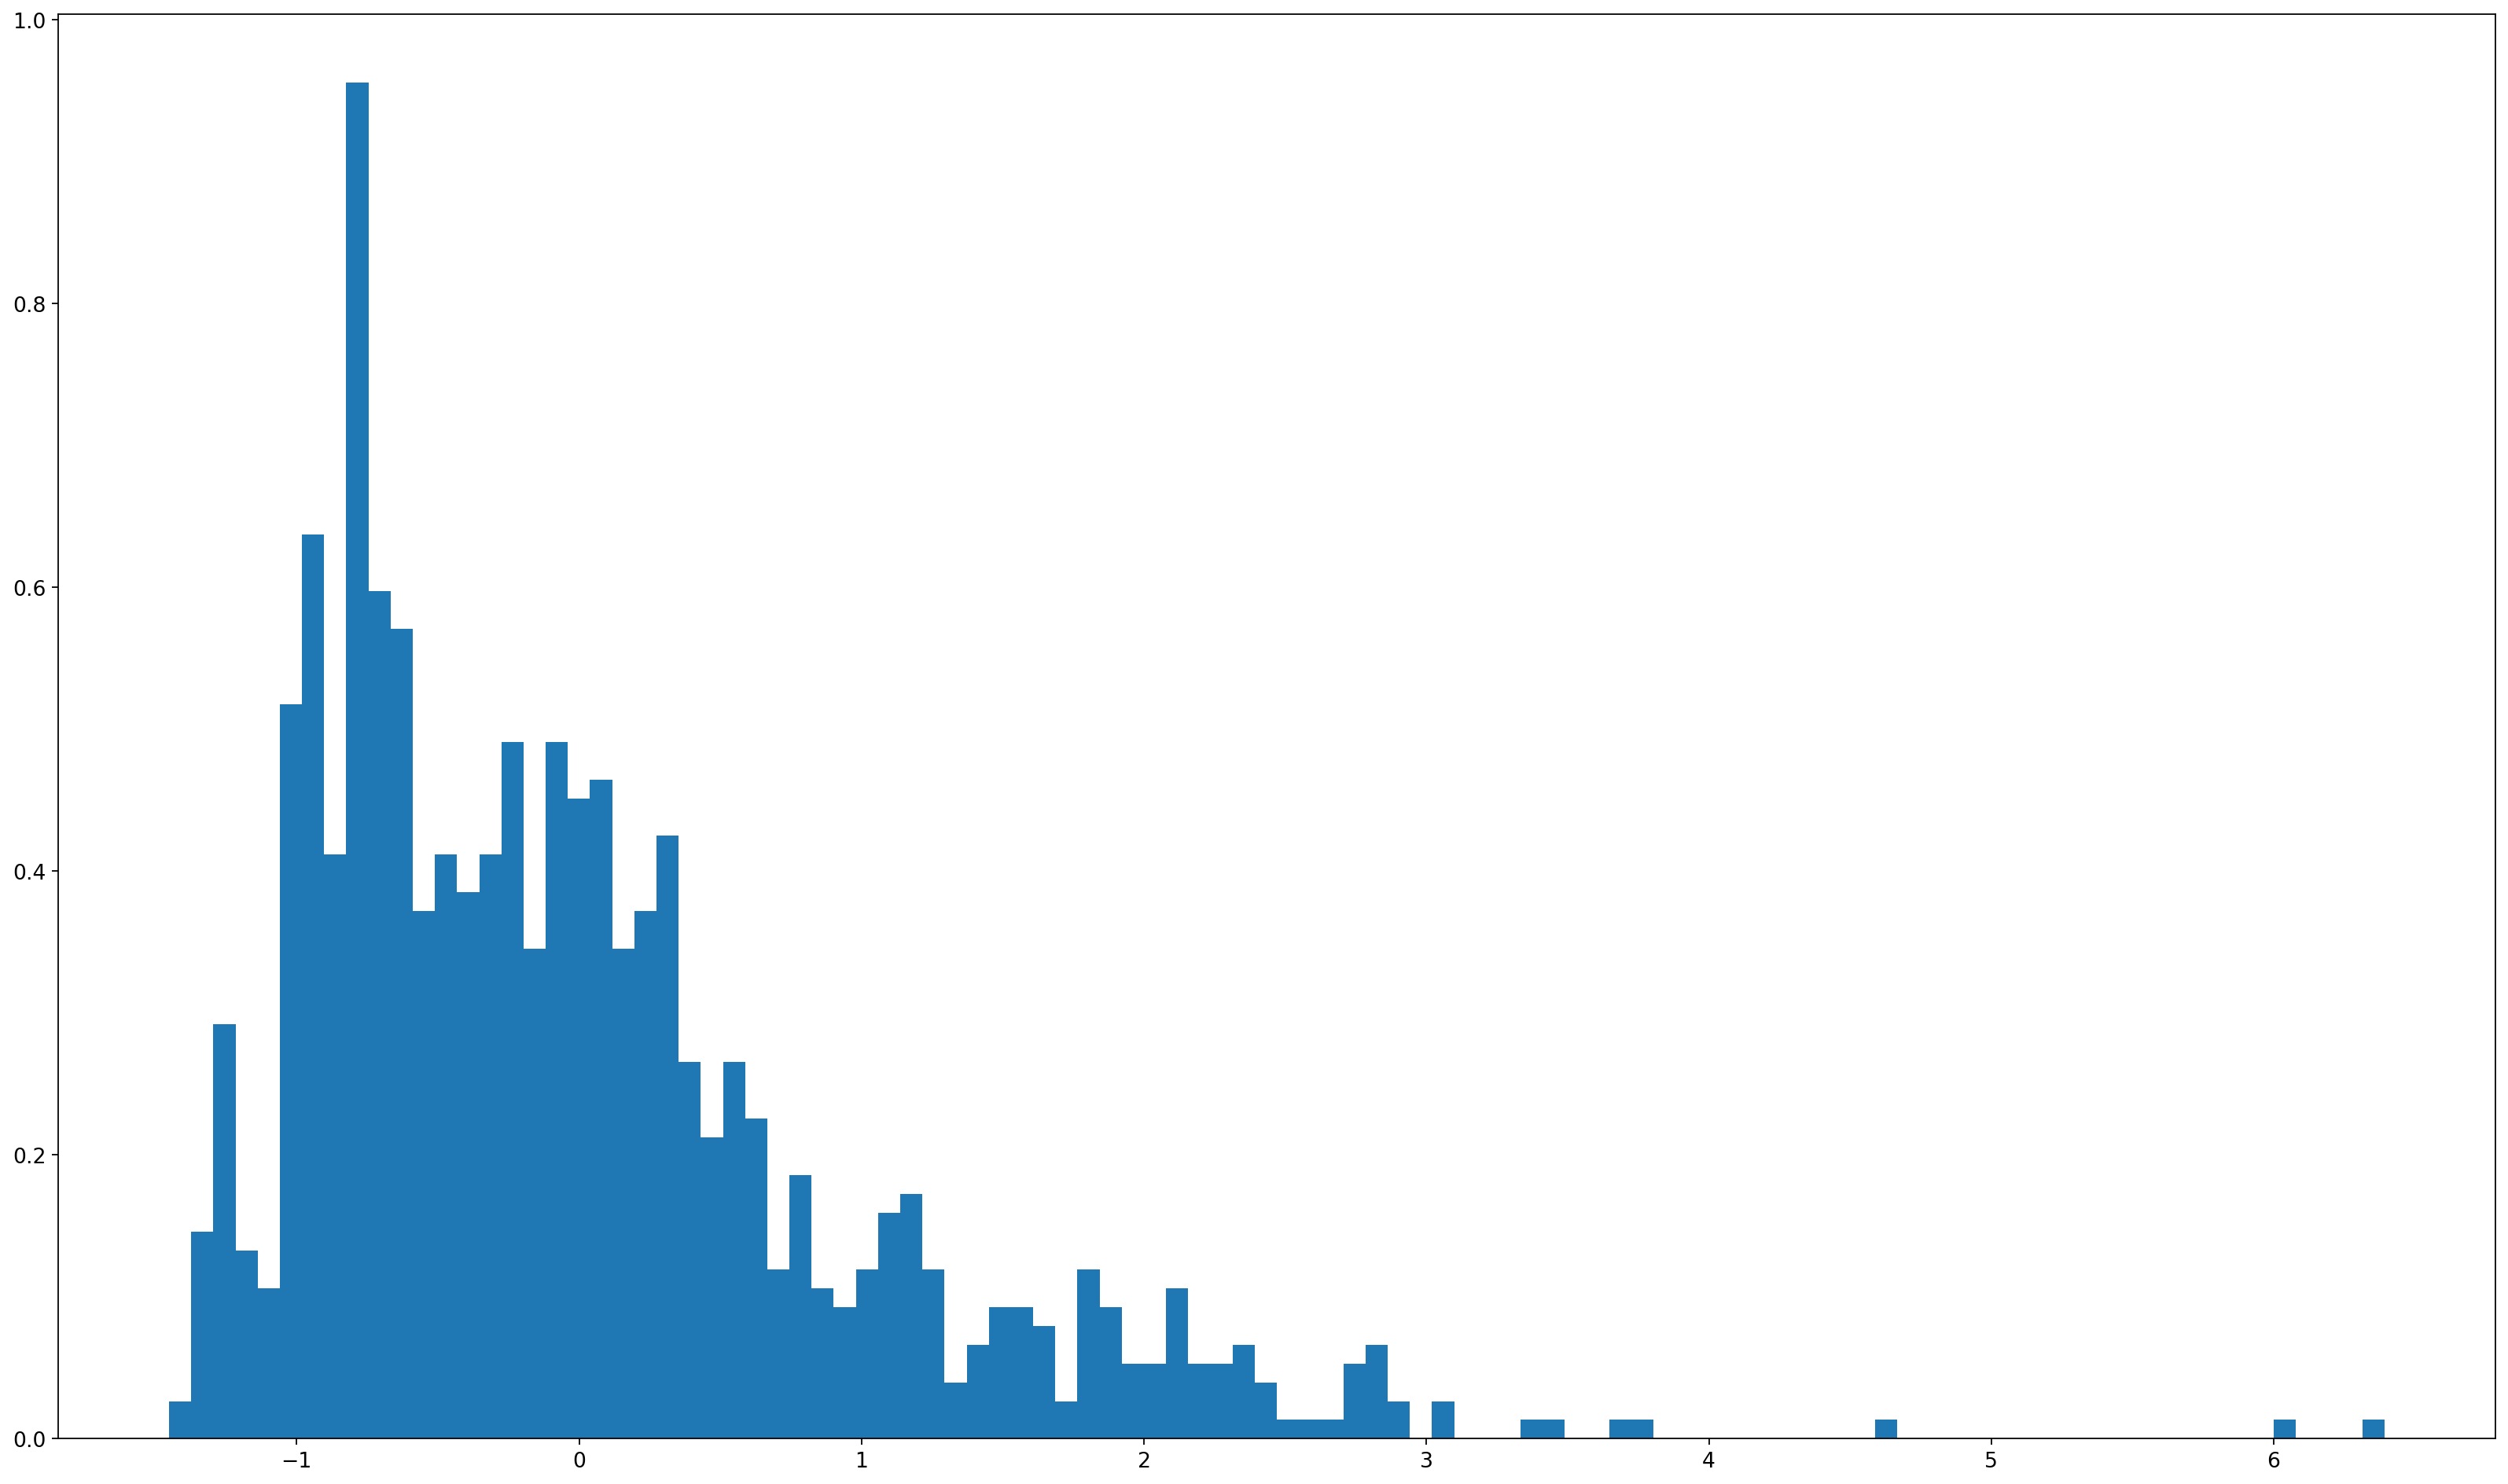

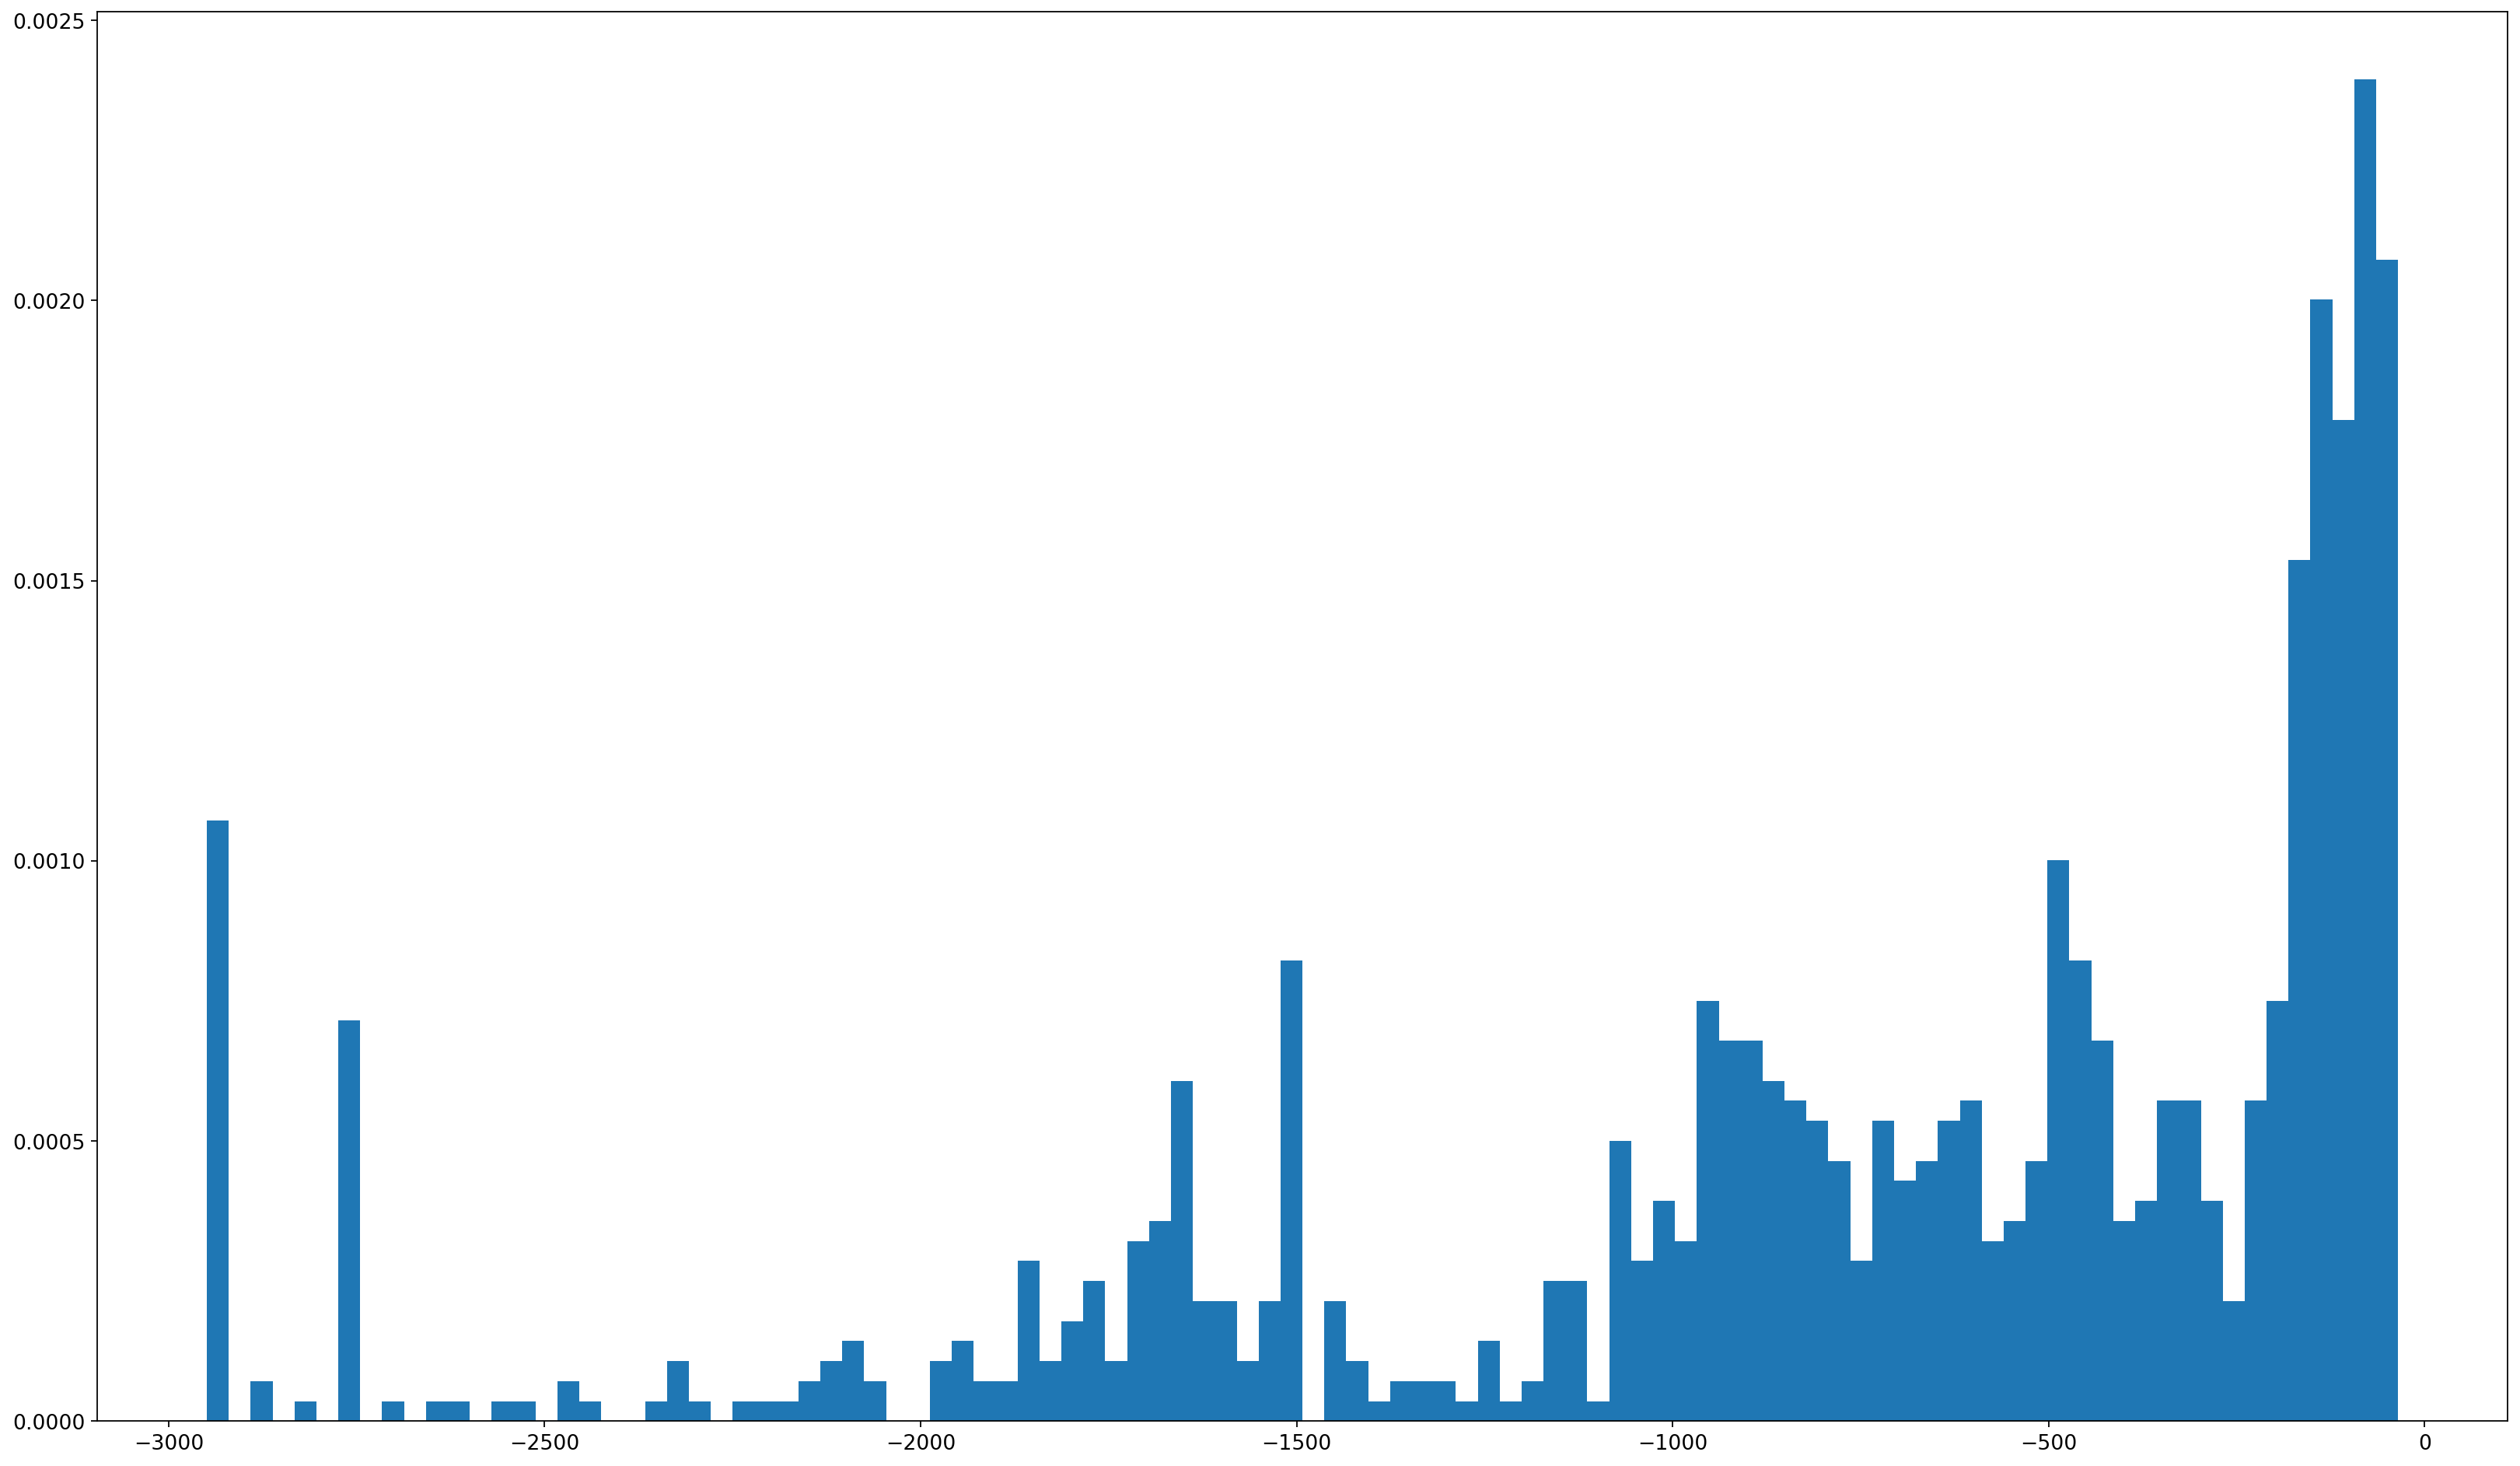

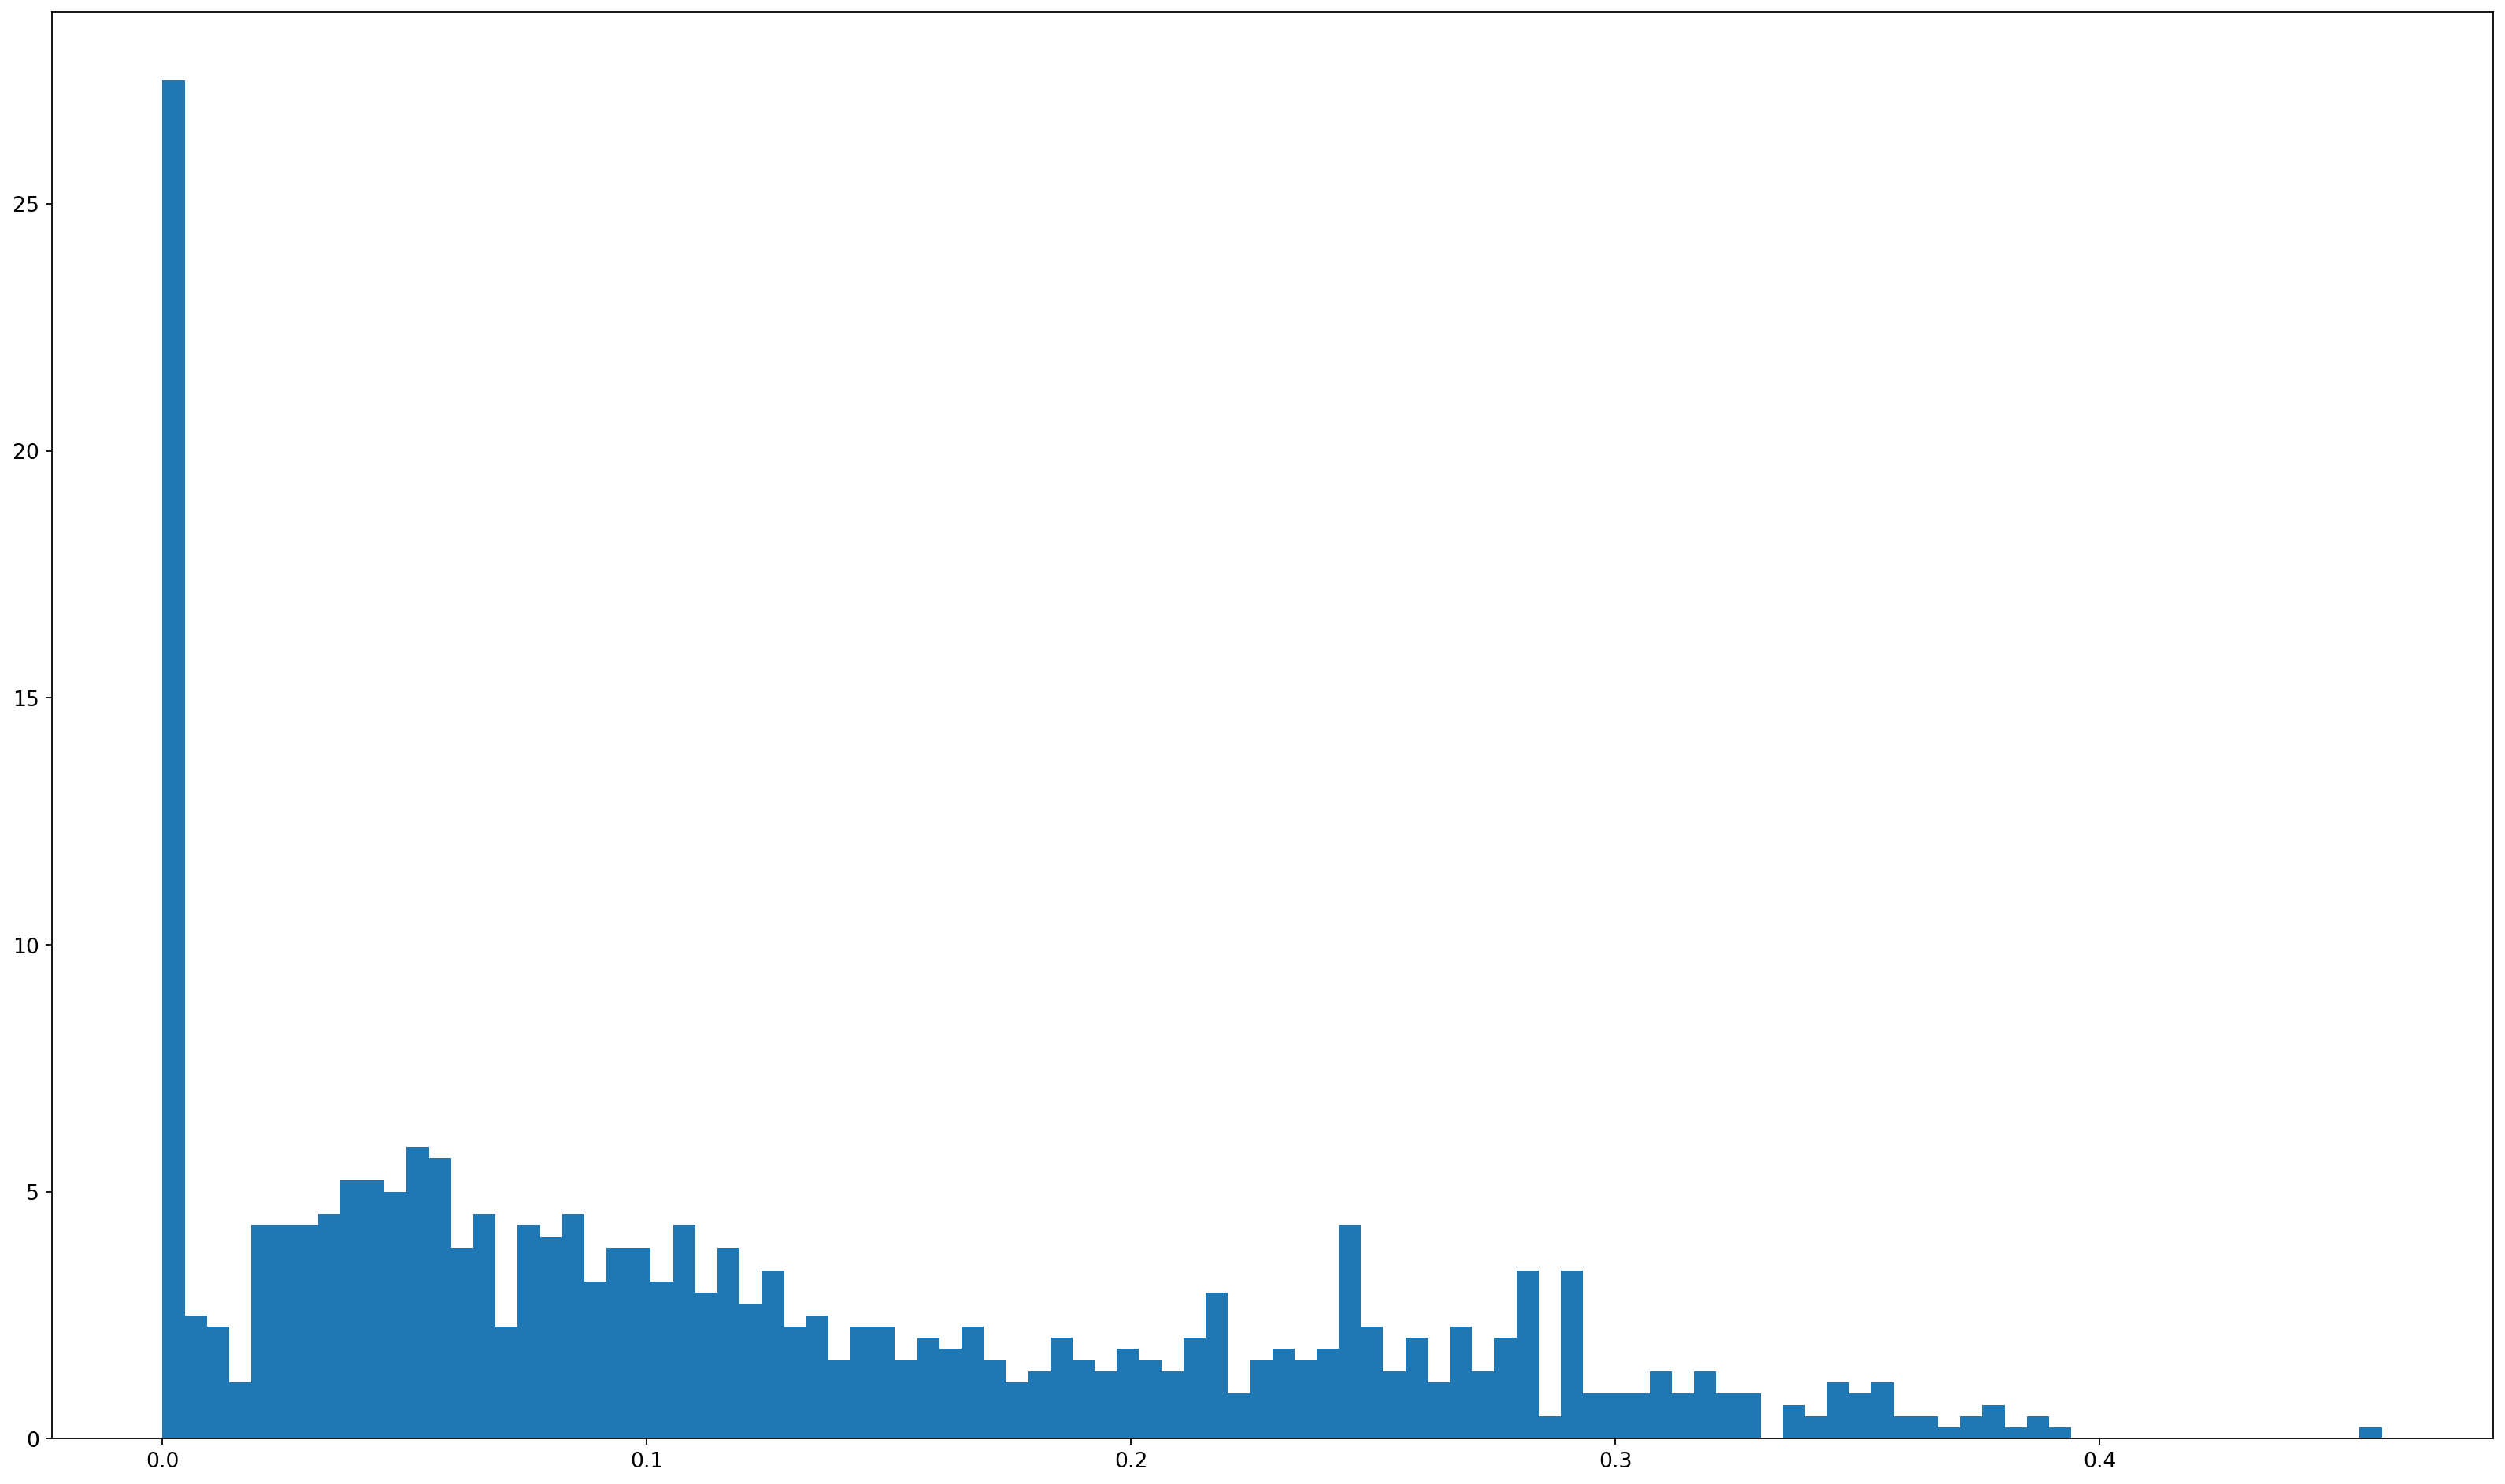

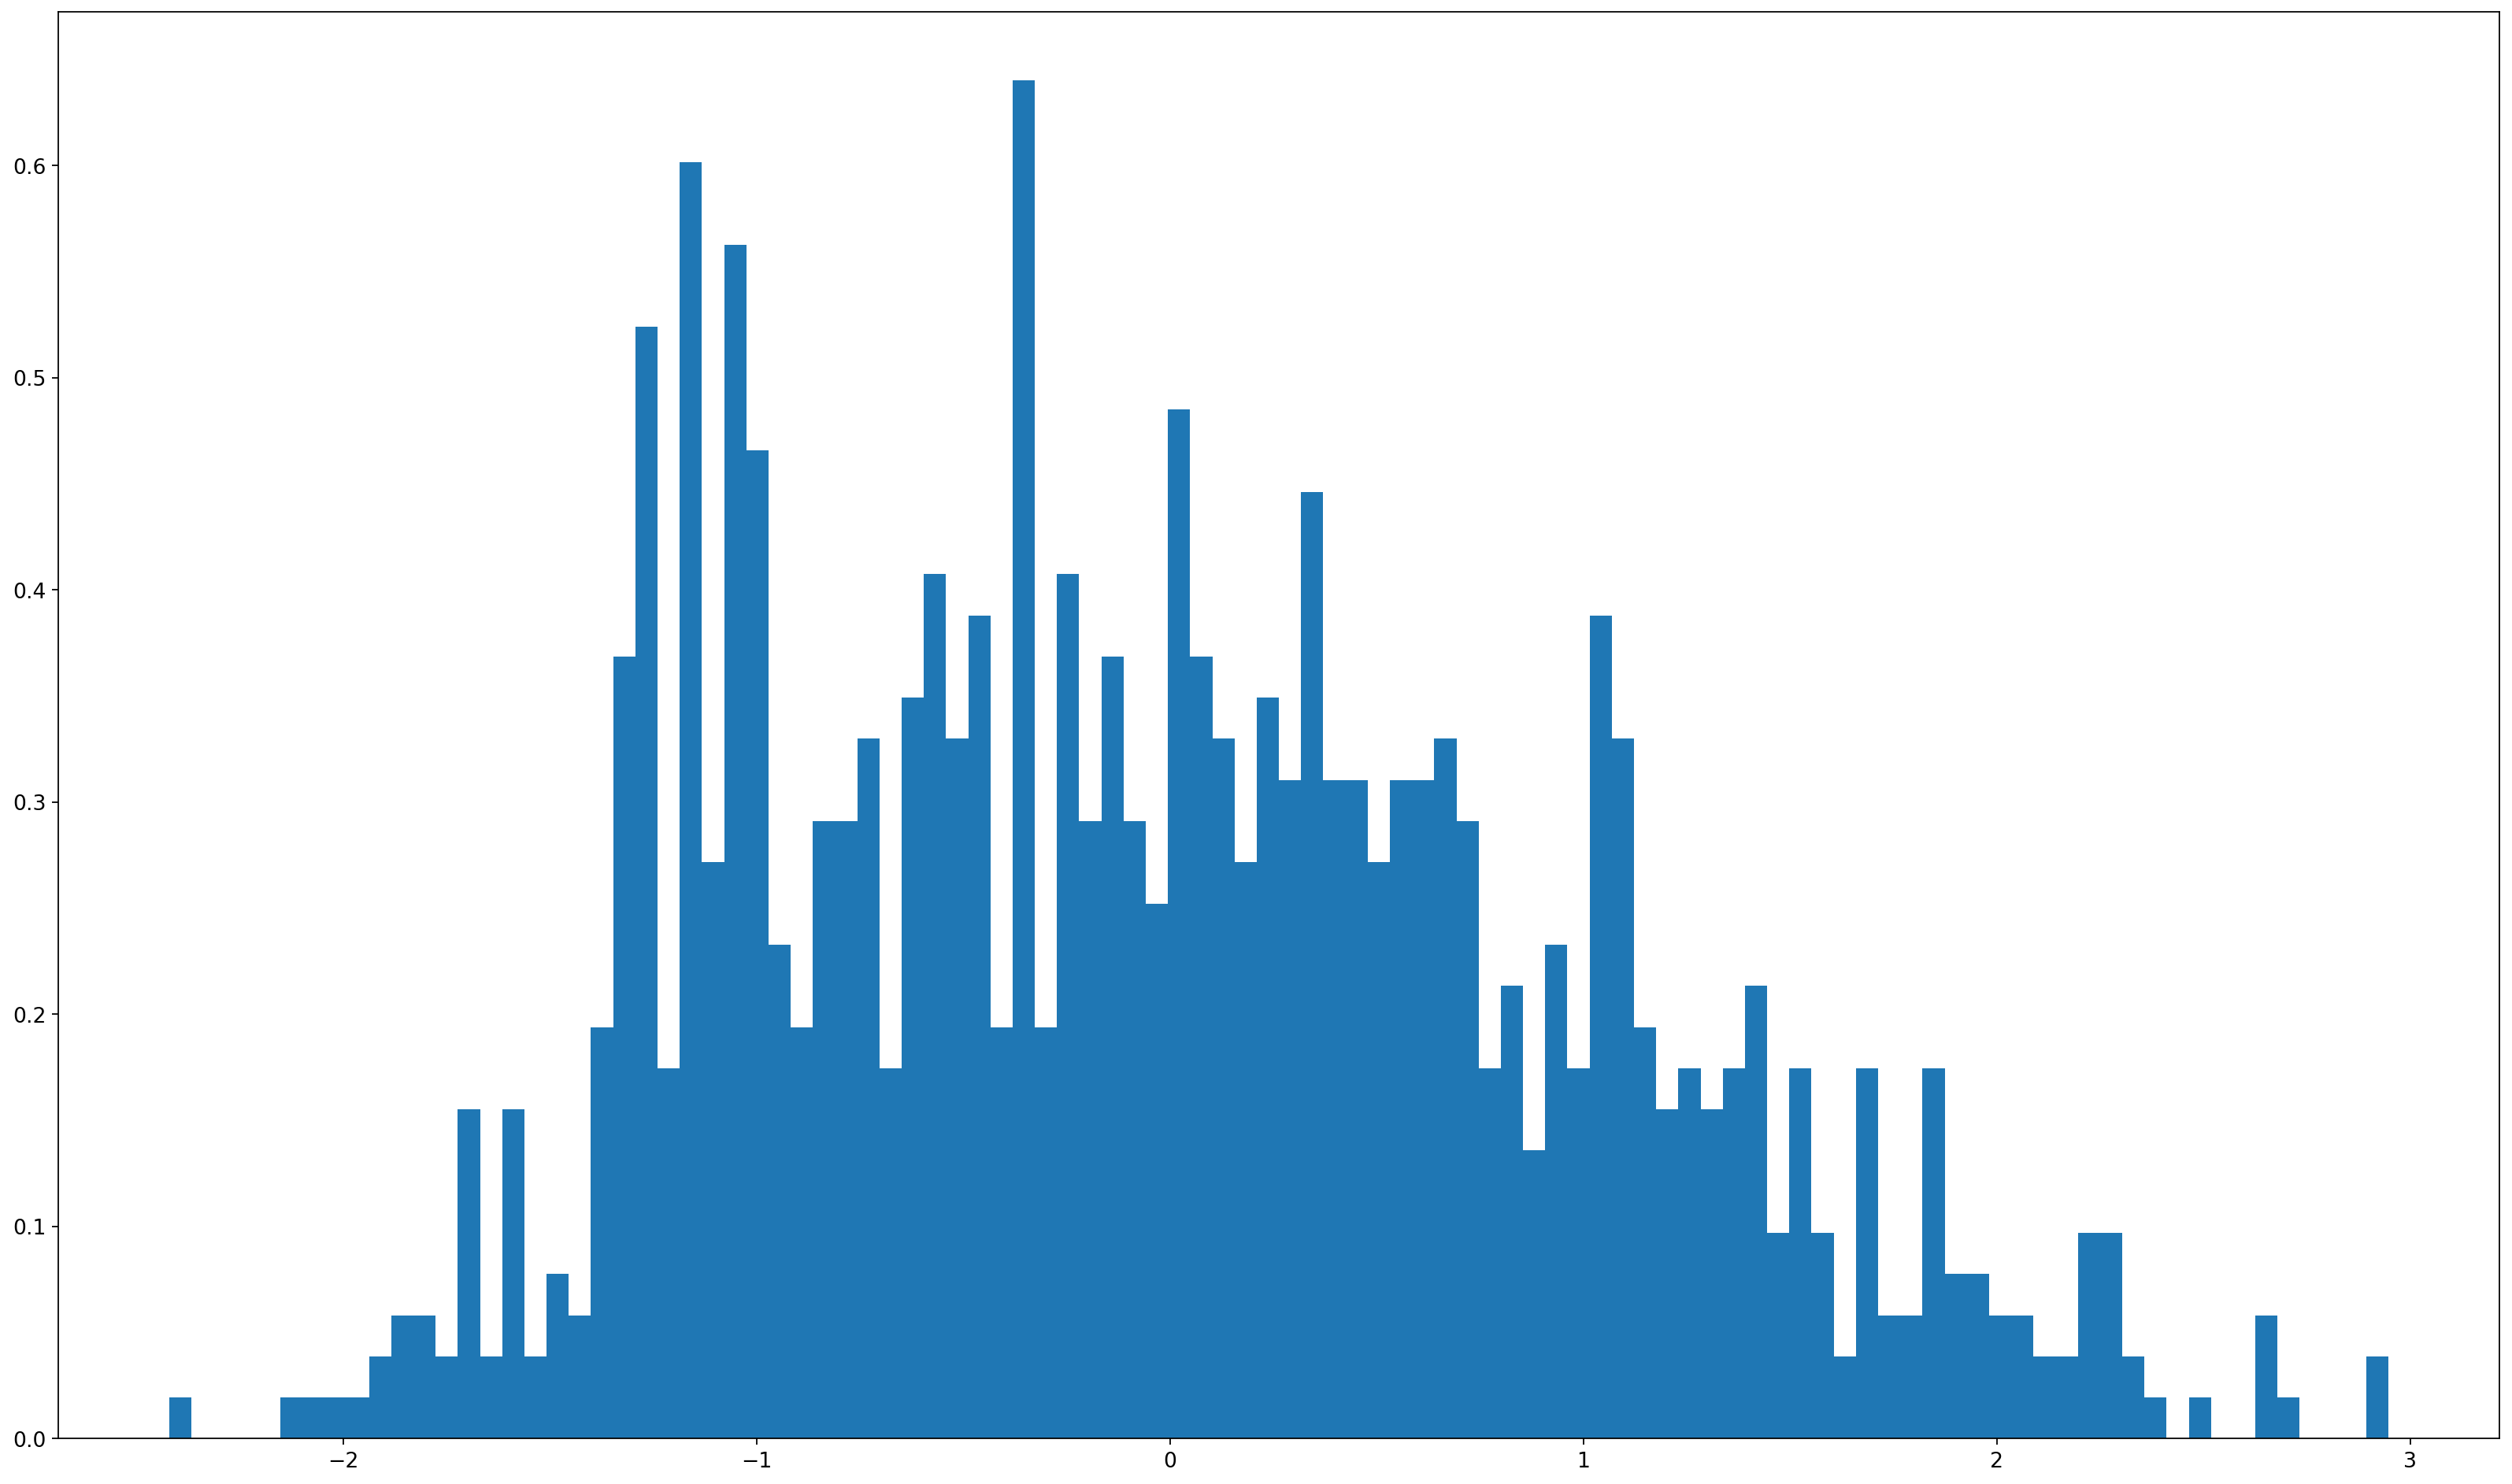

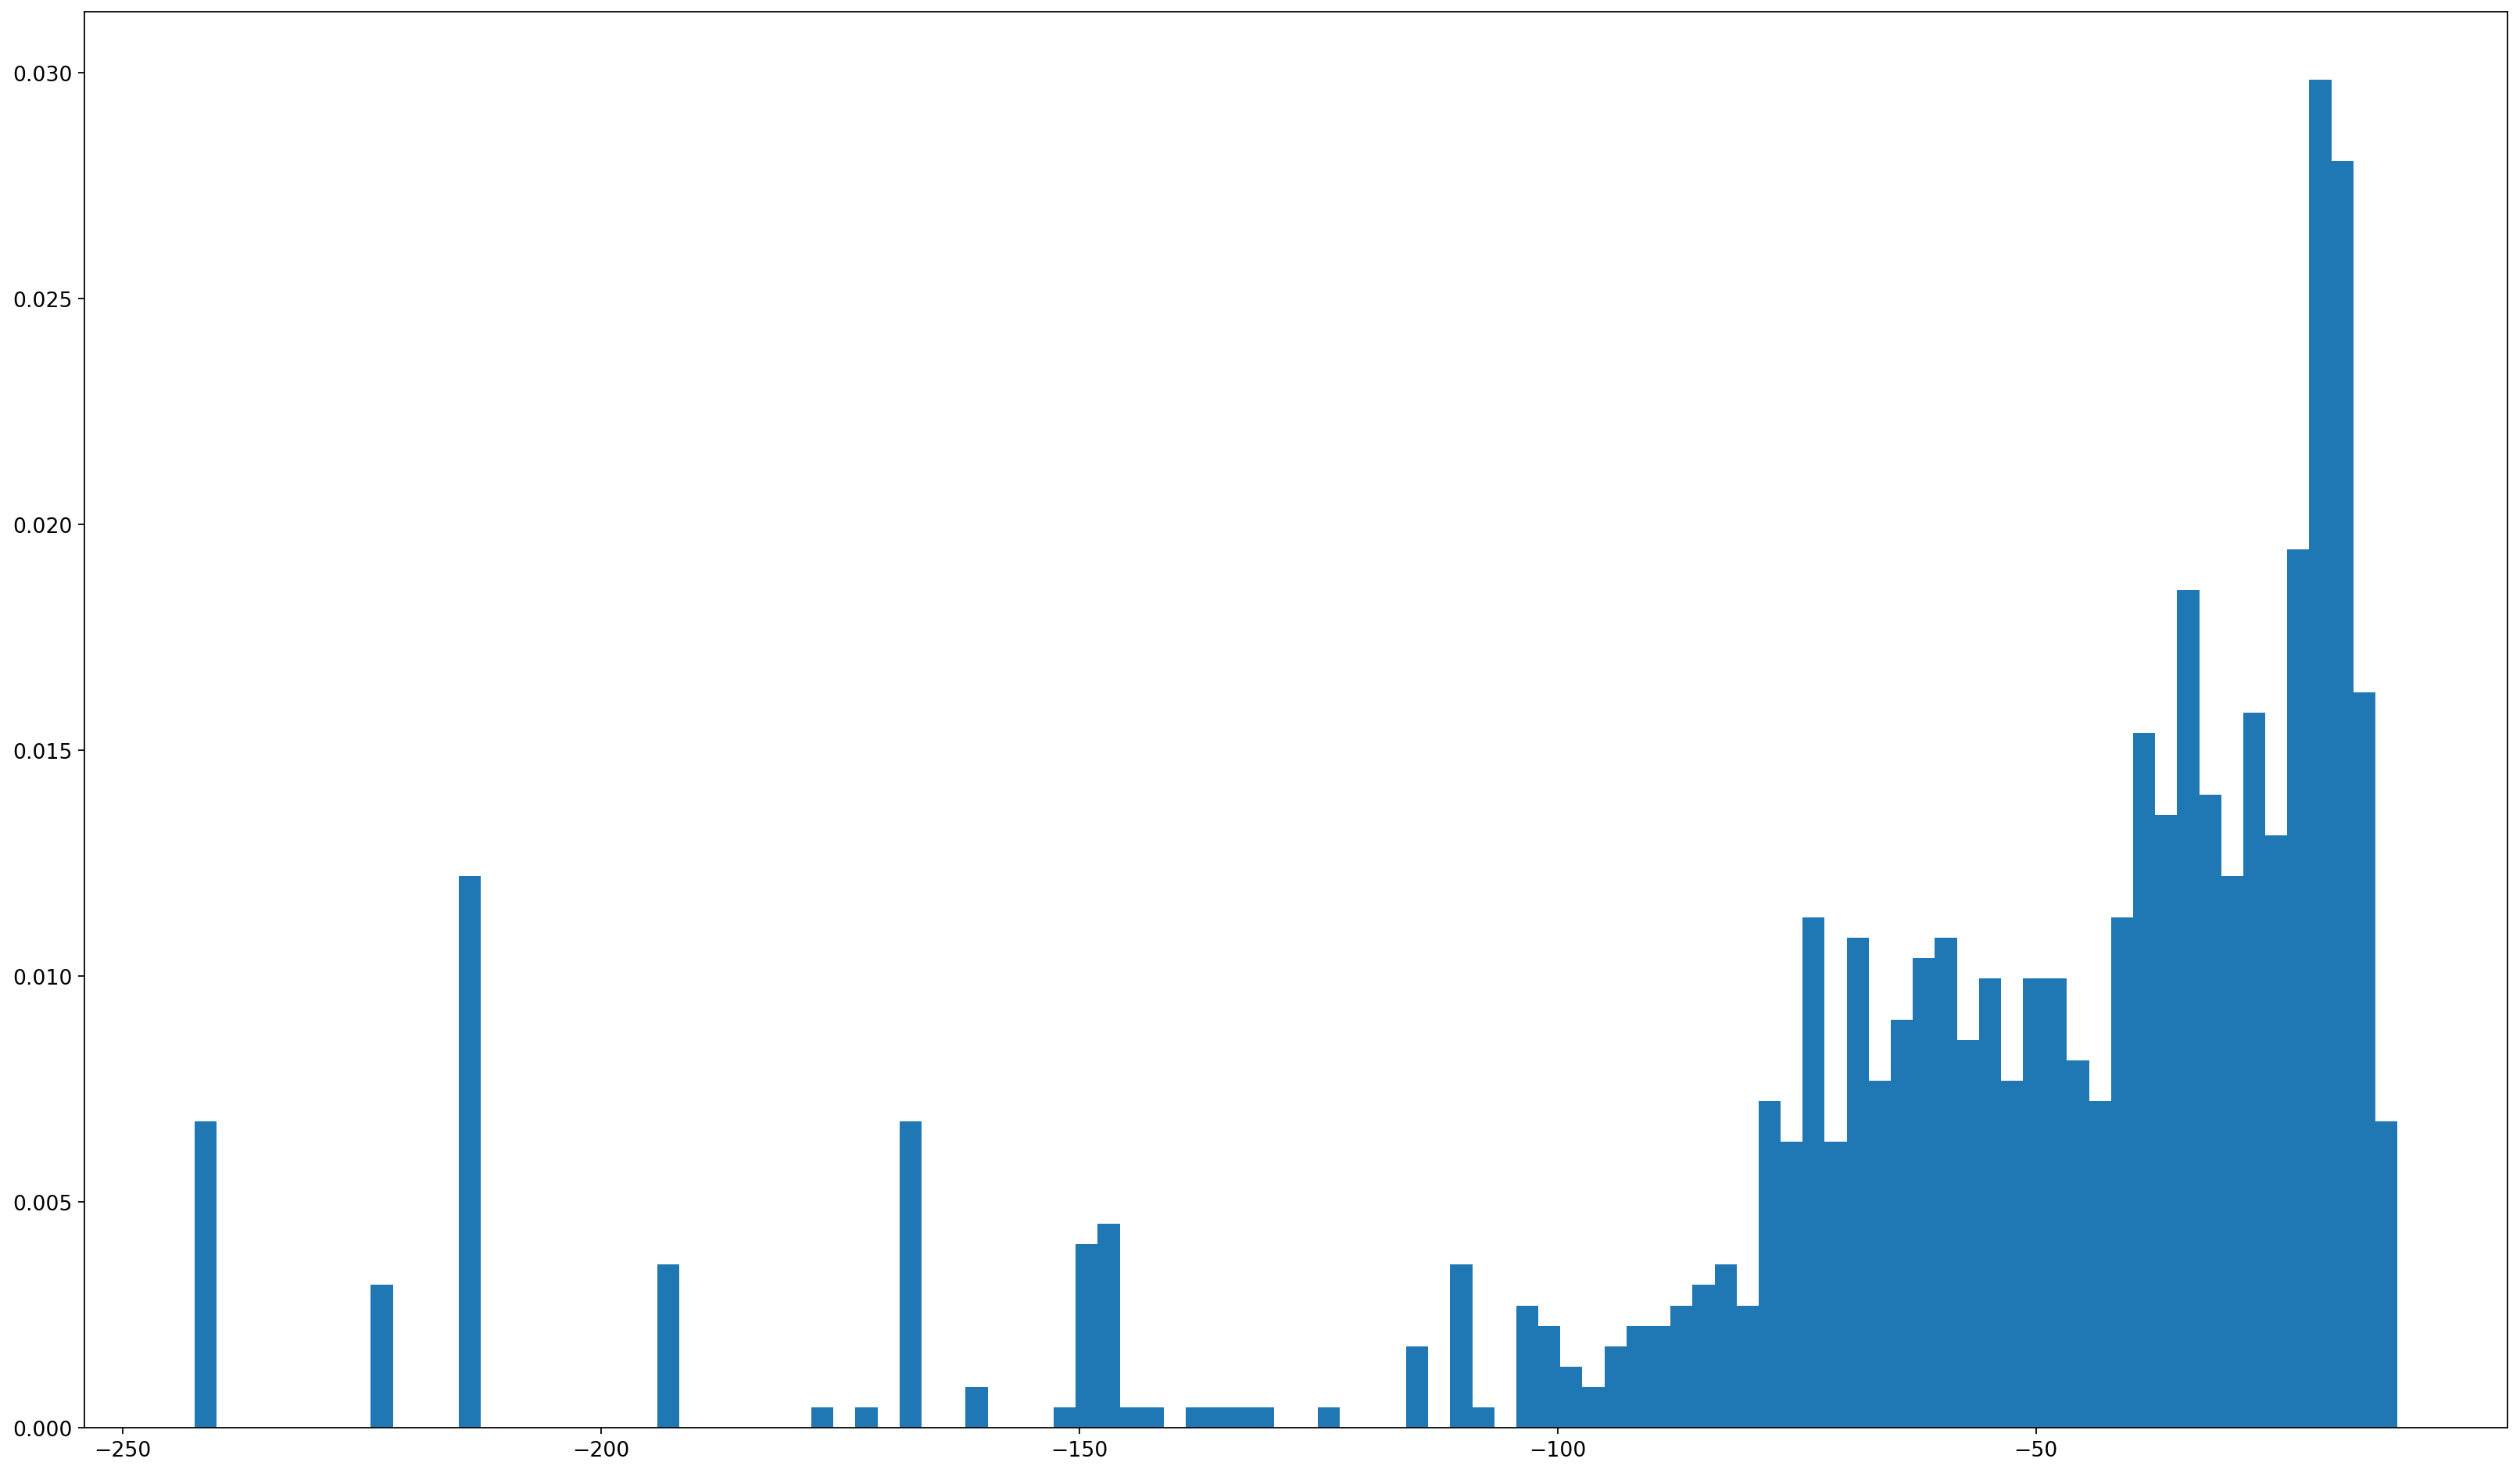

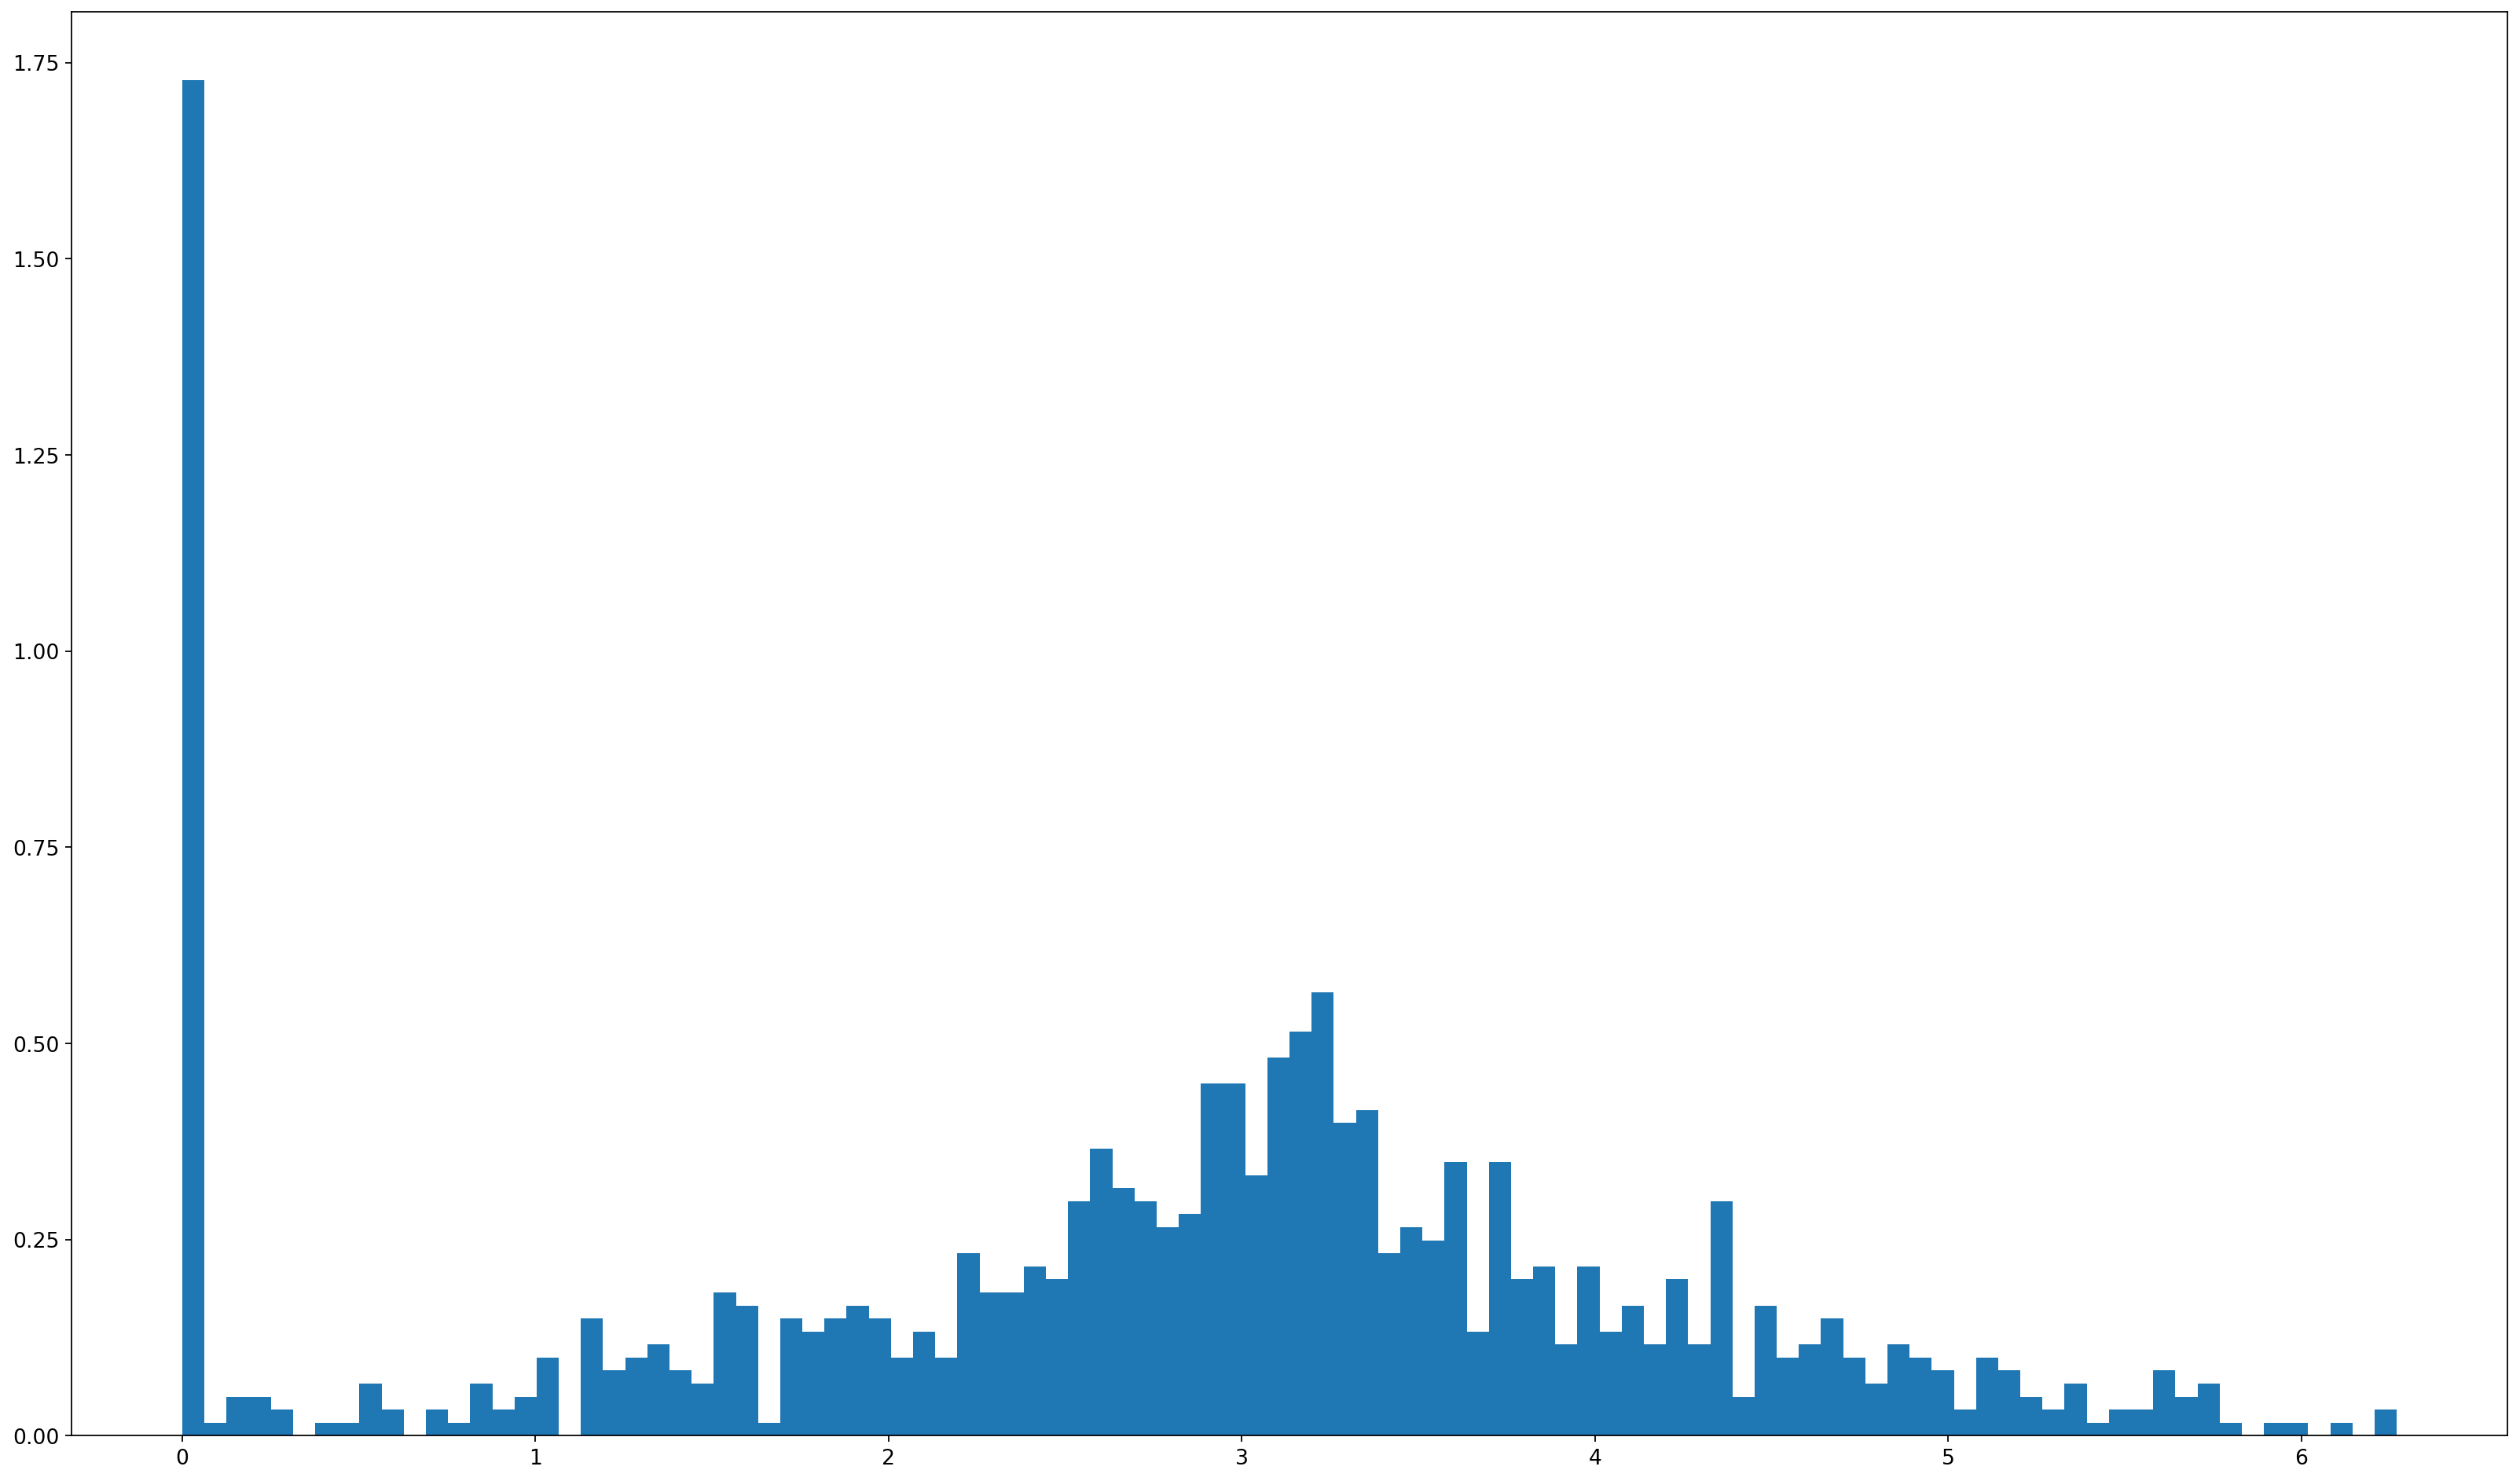

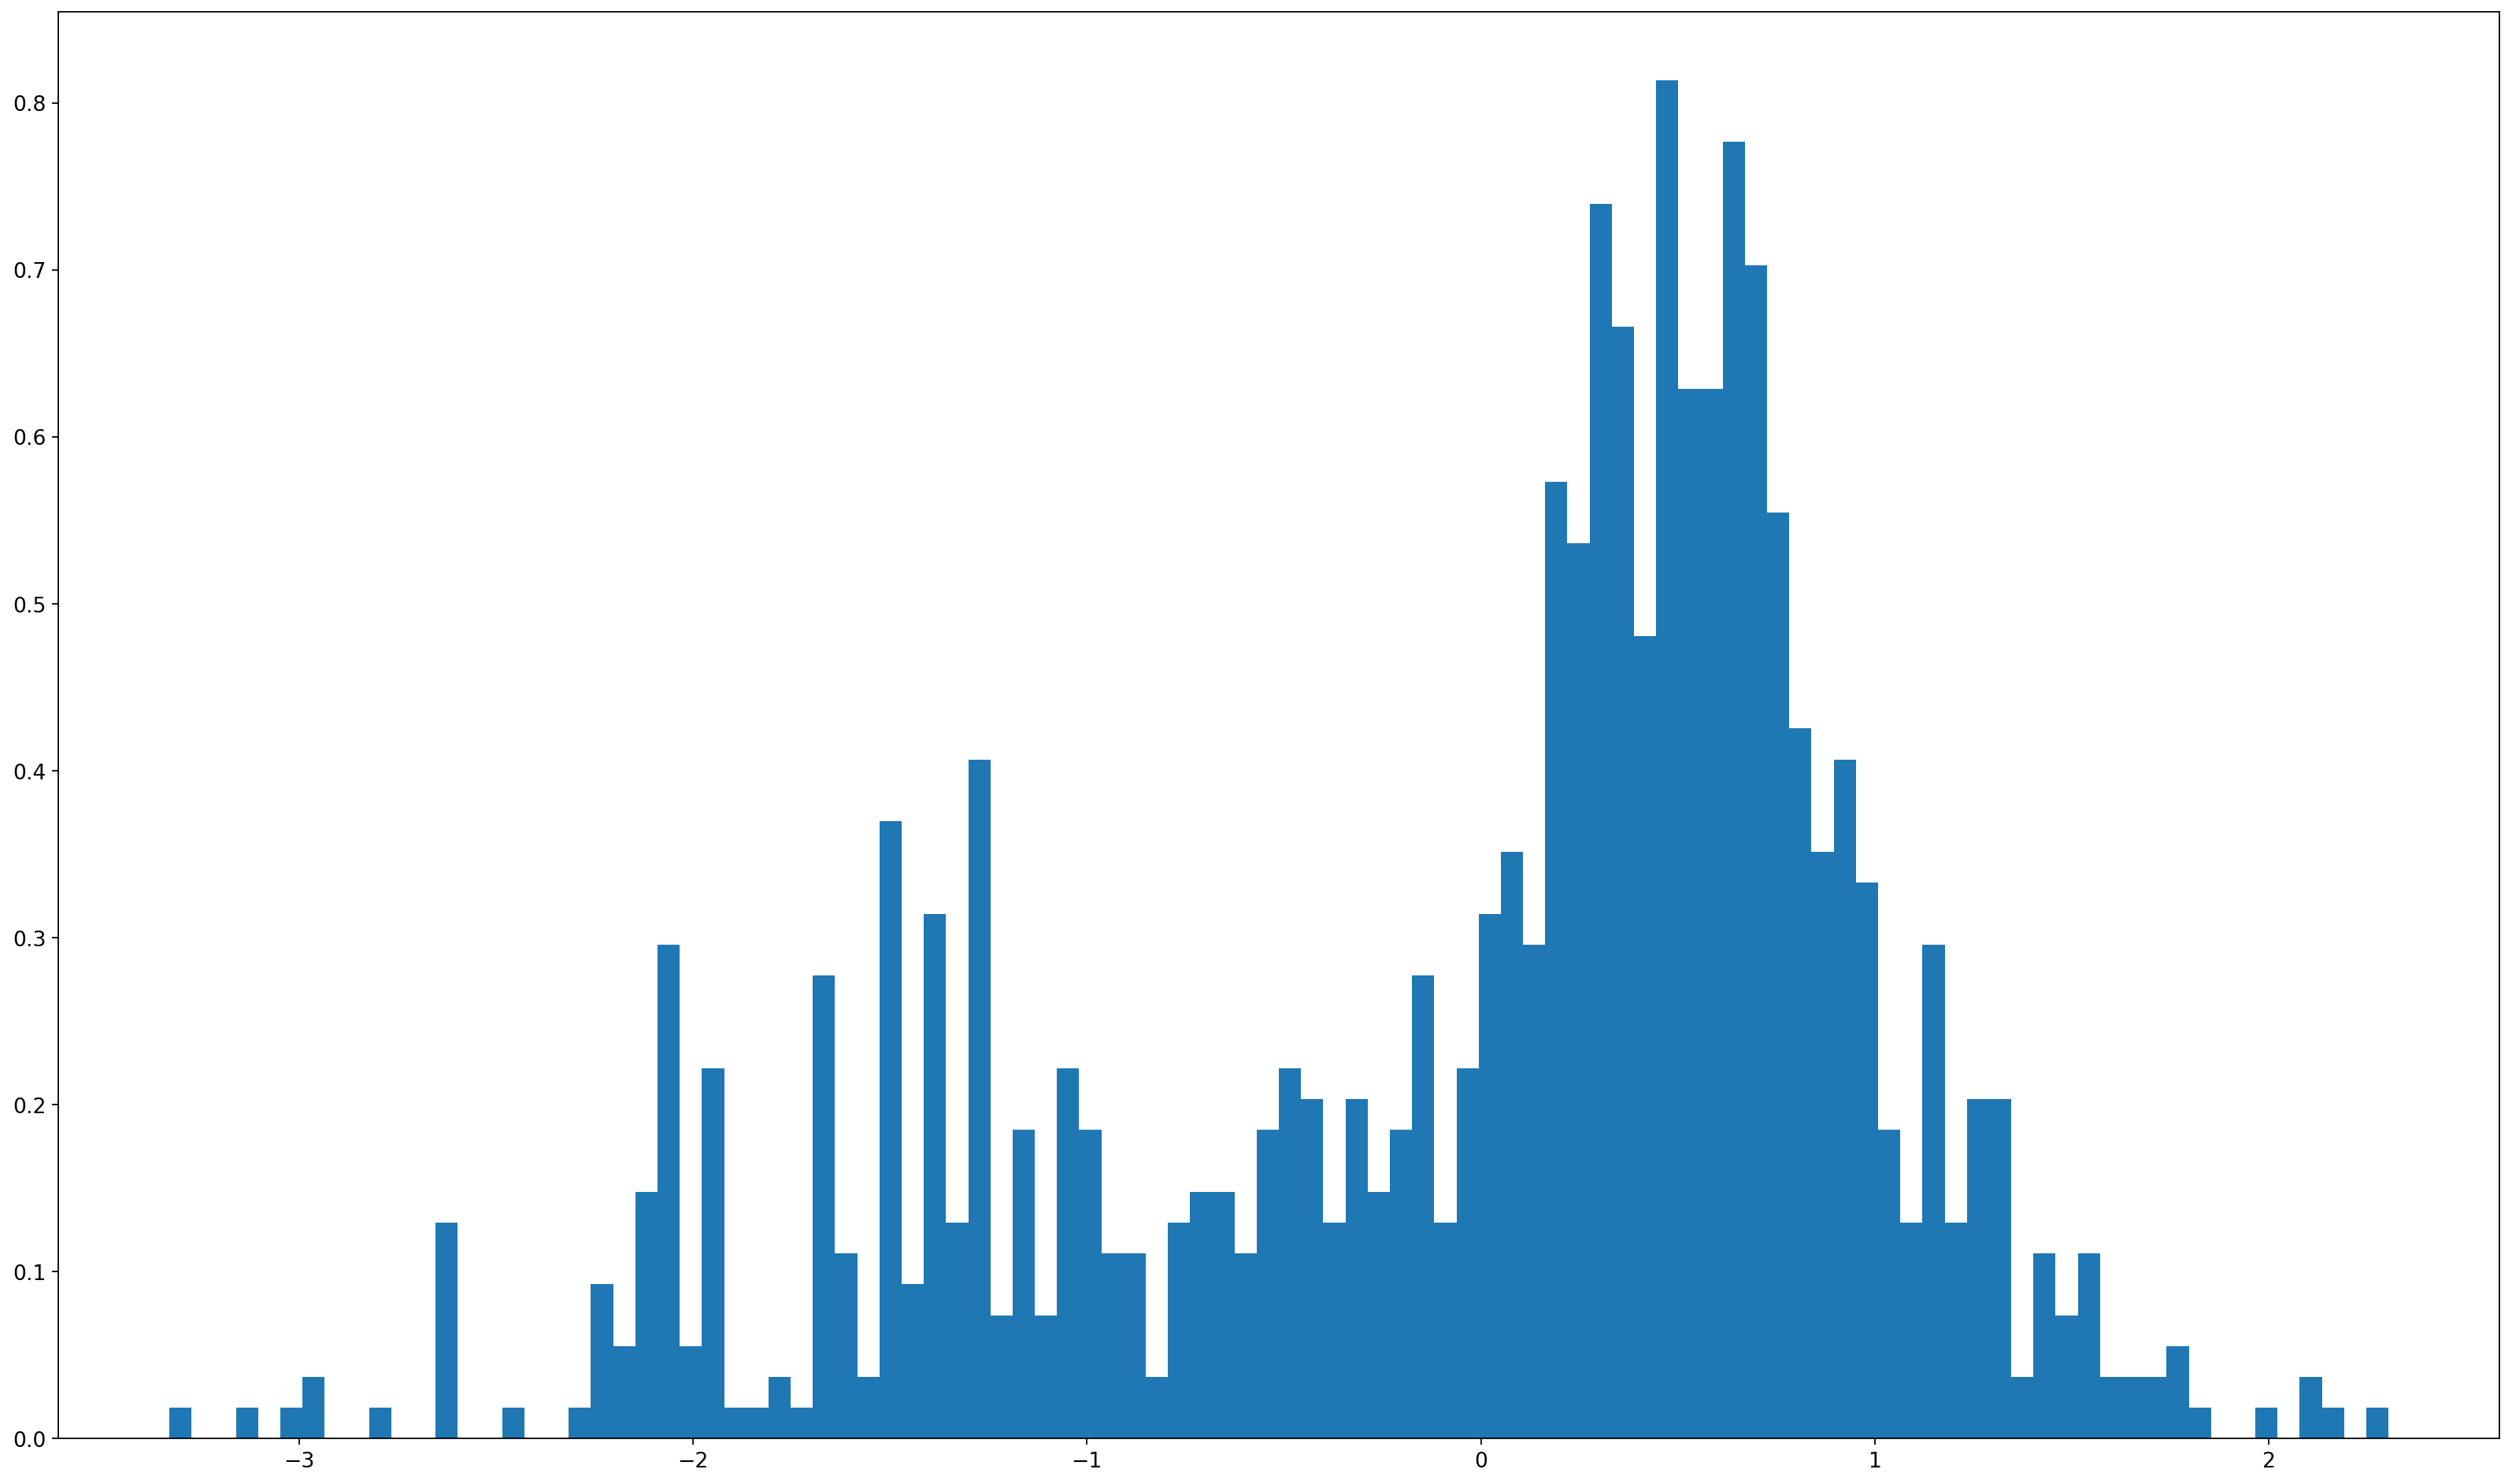

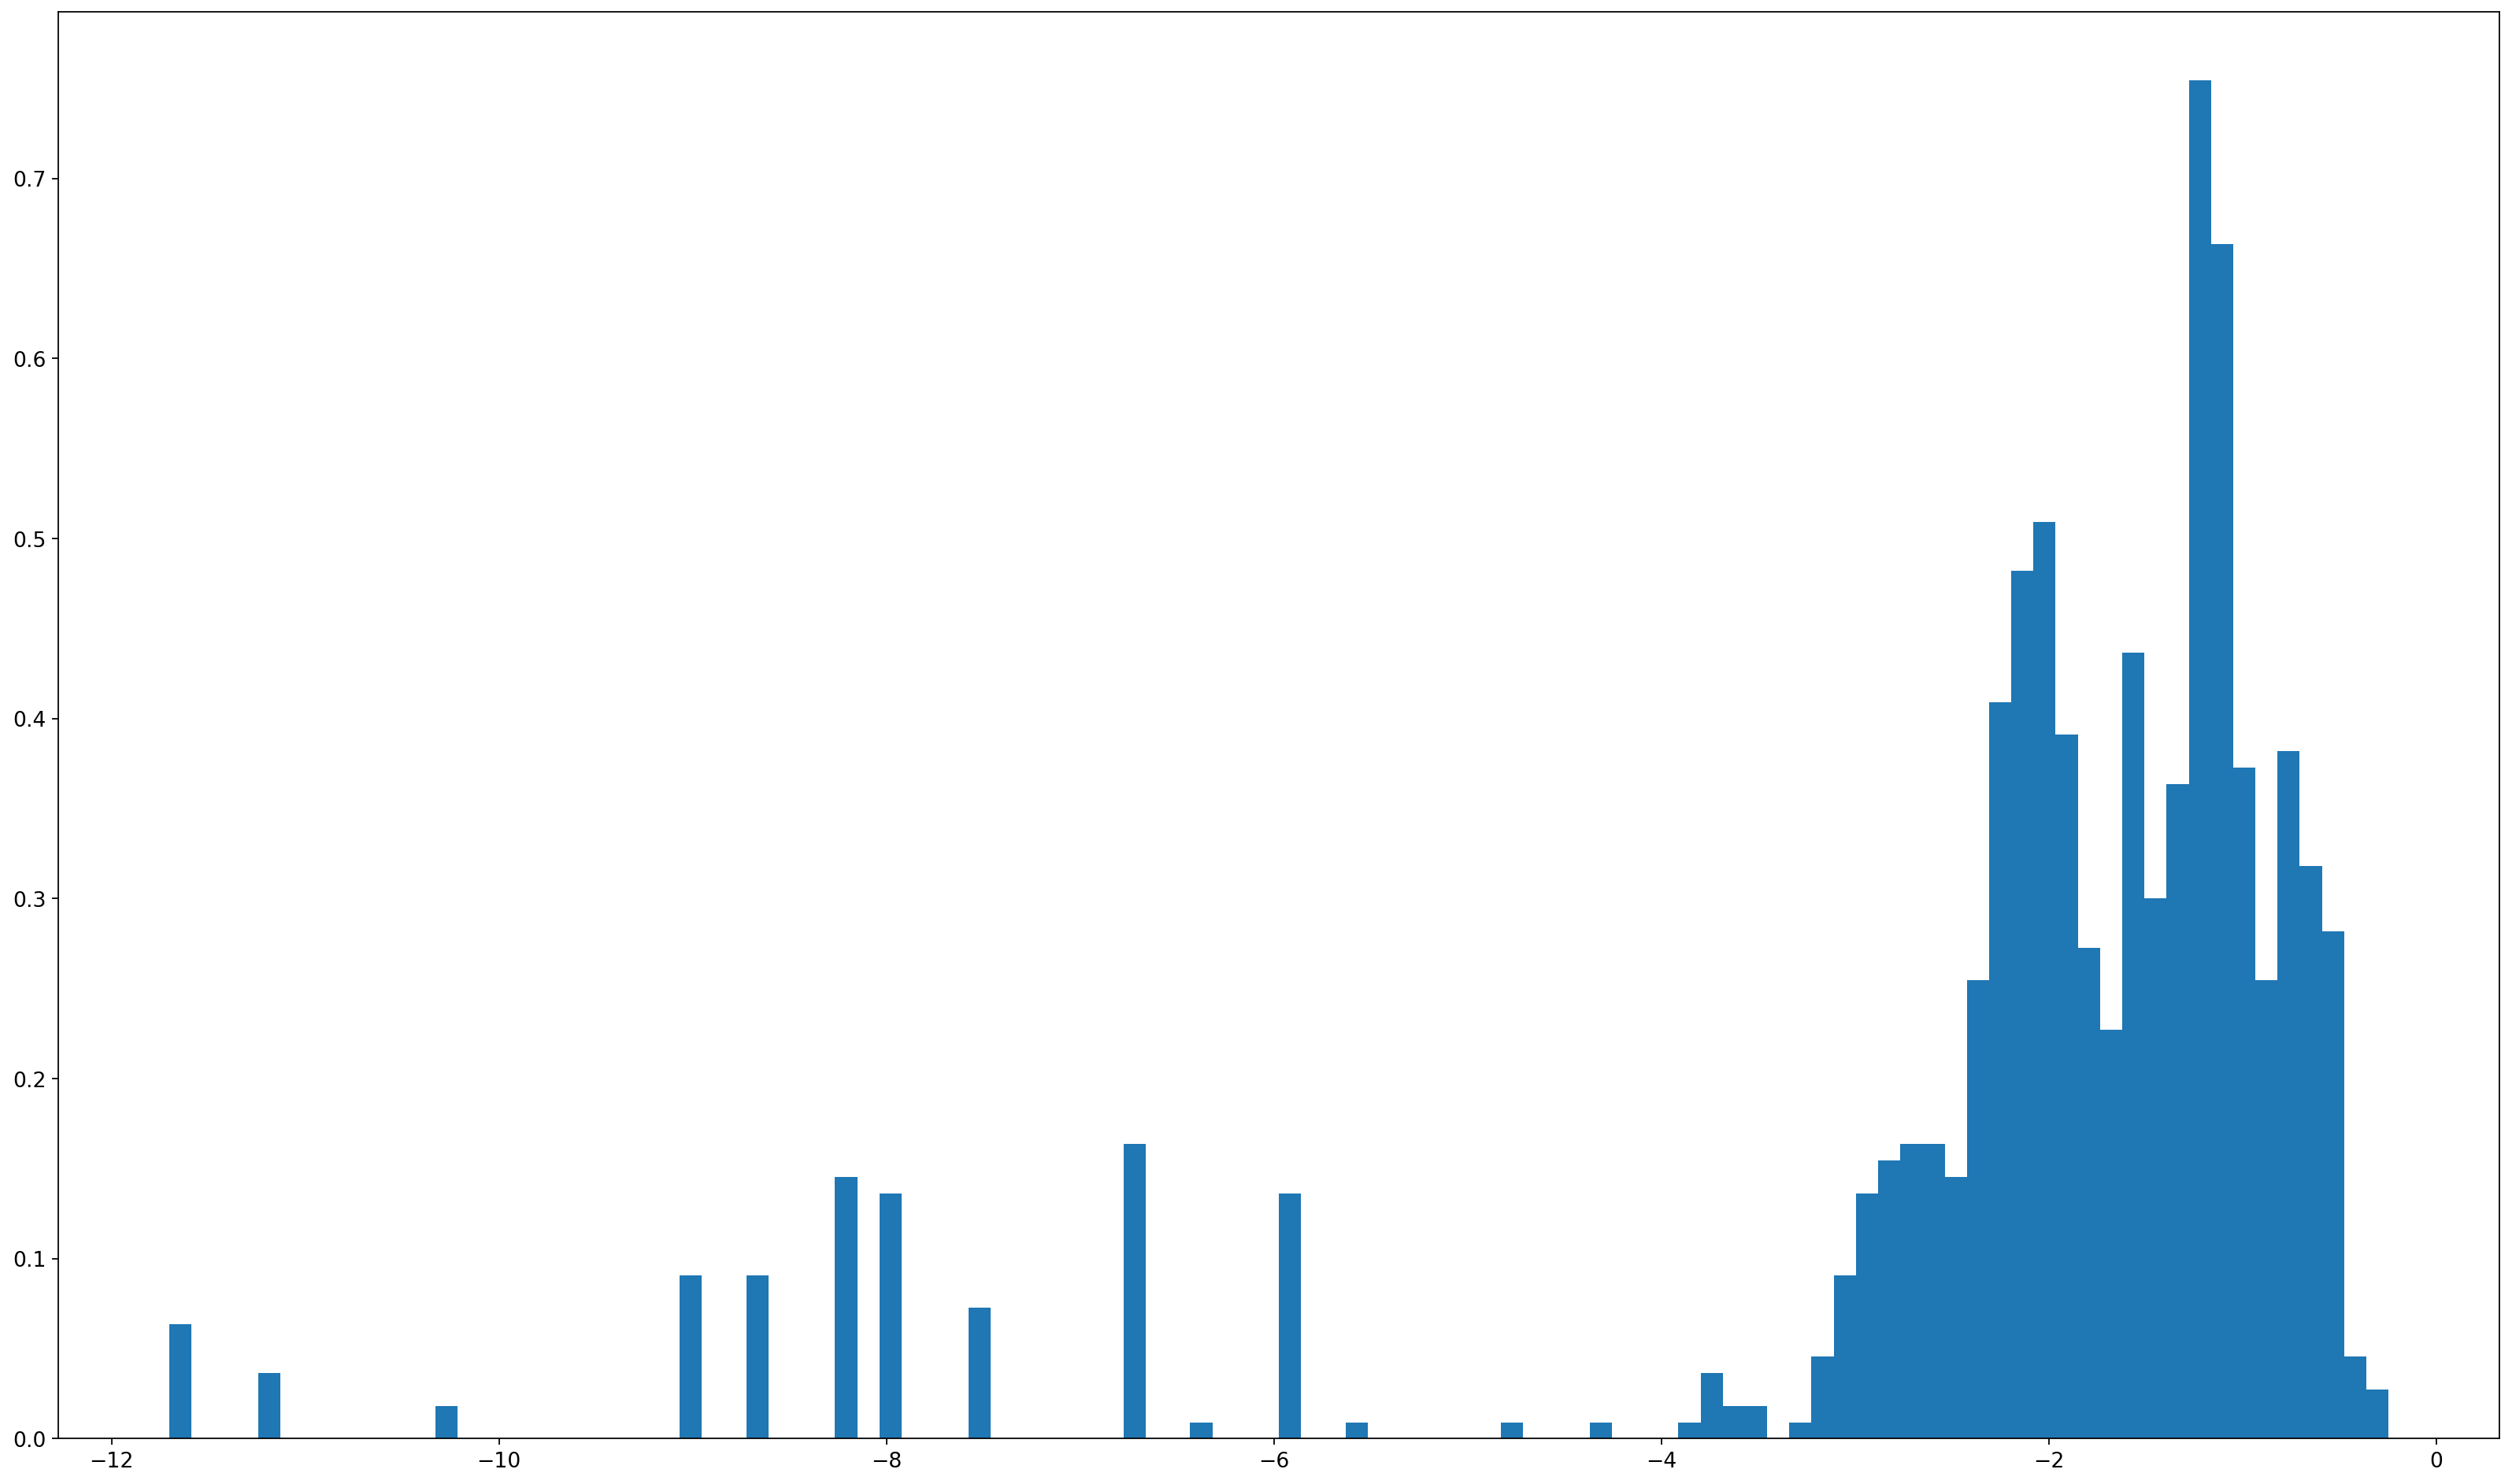

In [82]:
""" Creates scalers and fit them for normalization. Show data distribution before/after normalization. """
def plot_hist(data):
    plt.figure(figsize=(25, 15), dpi=80)
    plt.hist(data.flatten(),density = True, bins = 100)
    plt.show()

scalers = [ StandardScaler() for _ in range(X.shape[1]) ]

for i in range(X.shape[1]):
    data = X[:,i,:]
    plot_hist(data)
    scalers[i].fit(data)
    plot_hist(scalers[i].transform(data))

In [83]:
Xn = np.array([ scalers[i].transform(X[:,i,:]) for i in range(X.shape[1])])
Xn = np.moveaxis(Xn,0,1)
Xn.shape

(60, 3, 16)

# Dataset construction

En el siguiente código construimos el vector característico de cada imagen concatenando nuestras 3 features.

Para construir nuestro dataset sólo tendremos en cuenta imágenes originales (no falsificaciones entrenadas ya que no es el propósito de nuestro trabajo). Simularemos falsificaciones aleatorias con imágenes de otros autores.\
Así formaremos pares de imágenes y asignaremos como clase verdadadera a las que tienen distinto autor (las que levantarían una alerta) y clase falsa a las que tienen mismo autor.\
Si formamos todos los pares de imágenes posibles, tendríamos un desbalance en las clases (habría más pares correspondientes a la clase que tienen distinto autor). Esto haría que el score que optimiza el clasificador esté sesgado por el desbalanceo.\
Existen varios métodos de balanceo de clases. Nosotros hemos probado undersampling (recortar la clase más abundante) y oversampling (repetir la clase más escasa). Los resultados exprimentales han demostrado que no hay mejoría en usar un método u otro en balanceo (ver experimento 3).

Además, dada dos imágenes tenemos dos maneras que juzgamos naturales de, a partir de sus vectores característicos, crear un vector característico para el par: concatenándo o haciéndo la diferencia entre los dos vectores. En el primer caso el clasificador tendría toda la información a su disposición (habría el doble de features también por lo que entrenar es mucho más lento para la mayoría de los clasificadores). El segundo (hacer la diferencia) juzgamos que se basa en el criterio de ver que "tan distintas" son ambas características (en relación a nuestro objetivo de ver que tan similares o distintas son dos firmas).

En *dataset_tools.py* explicamos con más detalle las clases usadas en el siguiente código. *feature_obtainer* determina la manera en la que se combinarán las features de las dos pares de firmas que queremos elegir (diferencia o concatenación).\
*DataSetConstructor* es la clase que encapsula la construcción del dataset de pares de firmas, spliteando en train/test por autores y otras cuestiones como balanceo de clases o de crear un normalizador sólo en datos de test.

In [8]:
feature_obtainer_factory = lambda features_normal: FeatureObtainer_Difference( DataToFeatures_Features(features_normal) )
data_constructor = DataSetConstructor(feature_obtainer_factory,  'UNDERSAMPLE', features_dataset, to_features, MinMaxScaler)

*DataSet* es una clase que contiene los DataFrame de test/train y sus respectivas labels.
Vemos que tan balanceadas están las clases.

In [9]:
""" Construct the Datasets. """
ds = data_constructor.construct_datasets()

# Entrenamiento y evaluación de los modelos

Hemos elegido varios modelos simples (SGD, K-vecinos, Redes Neuronales, SVM con RBF, Random Forest) disponibles en la biblioteca sklearn y aplicado validación cruzada aleatoria de 20 iteraciones (entrenar y validar el modelo en diferentes particiones aleatorias de los datos).

Cómo para la generación de nuestros conjuntos de train y test partimos aleatoriamente por autores (los cuales son pocos) el puntaje obtenido puede depender fuertemente de la partición que hagamos. Es por ello que vamos a recurrir a validación cruzada aleatoria para comparar diferentes configuraciones del modelo.

Para evaluar el modelo hemos variado la sensibilidad del clasificador y tomado la mayor 'precision' para la cuál el recall es mayor a 0.9.

En *classification.py* están los clasificadores que vamos a usar. El mismo módulo contiene funciones para:
- ejecutar el pipeline de entrenamiento (ajustar en conjunto de entrenamiento, evaluar en test, medir el tiempo). 
- validación cruzada aleatoria (ejecutar el pipeline de entrenamiento para distintos datasets generados).
- definir una score_function que devuelva la máxima precision dado un requerimiento de recall

En el siguiente código testeamos el pipeline de generación de datos y entrenamiento con *DataToFeatures_Constant* que debería arrojar resultados muy malos (las features son numeros constantes, el clasificador no tiene patrones que hayar) y *DataToFeatures_Name* que debería arrojar resultados muy buenos (las features contiene el nombre del autor de la firma, el clasificador tiene que ver si matchean o no los autores). Es importante hacer estos chequeos ya que un bug en el pipeline podría arrojarnos incorrectamente malos (o buenos) valores de accuracy.

In [10]:
score_function = precision_by_recall_score_factory(0.9)

""" Usando DataToFeatures_Constant esperamos resultados malos """

feature_obtainer_factory_dummy = lambda features_normal: FeatureObtainer_Difference( DataToFeatures_Constant() )
data_constructor_dummy = DataSetConstructor(feature_obtainer_factory_dummy,  'UNDERSAMPLE', features_dataset, to_features, MinMaxScaler)
ds_dummy = data_constructor_dummy.construct_datasets()

train_and_eval_all_classifiers(fresh_classifiers(), 
    ds_dummy.trainData, ds_dummy.trainLabel, ds_dummy.testData, ds_dummy.testLabel, score_function)

,model_name,train_score,test_score,time_consumed
0,Stochastic Gradient Descent,0.5,0.5,0.005111
1,Neural Network Deep 3,0.5,0.5,0.021188
2,Neural Network Deep 2,0.5,0.5,0.016803
3,KNeighbors,0.5,0.5,0.005950
4,RandomForest,0.5,0.5,0.193416
5,SVM RBF,0.5,0.5,0.003949


In [11]:
""" Usando DataToFeatures_Name esperamos resultados muy buenos """

feature_obtainer_factory_dummy = lambda features_normal: FeatureObtainer_Difference( DataToFeatures_Name() )
data_constructor_dummy = DataSetConstructor(feature_obtainer_factory_dummy,  'UNDERSAMPLE', features_dataset, to_features, MinMaxScaler)
ds_dummy = data_constructor_dummy.construct_datasets()

train_and_eval_all_classifiers(fresh_classifiers(), 
    ds_dummy.trainData, ds_dummy.trainLabel, ds_dummy.testData, ds_dummy.testLabel, score_function)

,model_name,train_score,test_score,time_consumed
0,Stochastic Gradient Descent,0.500000,0.50,0.002309
1,Neural Network Deep 3,1.000000,0.56,0.018030
2,Neural Network Deep 2,0.728814,0.56,0.015319
3,KNeighbors,1.000000,1.00,0.002207
4,RandomForest,1.000000,1.00,0.173015
5,SVM RBF,1.000000,1.00,0.002206


## Primer modelo entrenado

En Machine Learning juega un rol importante la experimentación. Como veremos en la etapa de clasificación existen muchas decisiones e hiperparámetros que podemos variar, pero siempre es importante hacerlo de forma razonable ya que una búsqueda exhaustiva podría ser engorrosa o practicamente inabarcable. 

Hemos probado inicialmente con una configuración que nos pareció razonable como punto de partida:
- Como método de balanceo de clases hemos elegido 'undersample'. Uno de los problemas que observaremos es sobreajuste y no tiene mucho sentido bajo este problema hacer 'oversample'. Además que aumenta el tiempo de entrenamiento.
- Hemos obtenido las features del par de firmas haciendo la diferencia de los vectores característico, capturando la noción de diferencia entre firmas y reduciendo (con respecto a la mitad si se concatenara) la cantidad de features, acelerando el entrenamiento.
- Hemos tomado como cantidad de particiones 16, por haber generado los mejores resultados en \[TESIS-MARIANELA\], no hemos aplicado data augmentation inicialmente ni DFFT.
- Hemos utilizado MaxMinScaler por considerar el más adecuado para nuestras features (diferentes unidades y distribución no normal).

En el modulo *grid_search.py* hay un método que nos genera un DataSet dada una configuración. También hay un backtracking para explorar un espacio de configuraciones que utilizaremos luego para elegiar la configuración más conveniente.

In [12]:
N_FOLDS = 20
RECALL_REQUIRED = 0.9
score_function = precision_by_recall_score_factory(RECALL_REQUIRED)

In [15]:
config = {
    'BALANCE_METHOD' : 'UNDERSAMPLE',
    'FEATURE_MIX_METHOD' : 'FeatureObtainer_Difference',
    'FFT' : 'OFF',
    'DATASET' : '16',
    'DATASET_AUGMENTATION' : 'OFF',
    'SCALER_METHOD' : 'MinMaxScaler',
}

data_constructor = configurate(config)

In [16]:
df_results = test_random_fold(N_FOLDS, fresh_classifiers(), data_constructor, score_function)
df_results

,train_score_0,test_score_0,time_consumed_0,train_score_1,test_score_1,time_consumed_1,train_score_2,test_score_2,time_consumed_2,train_score_3,...,time_consumed_17,train_score_18,test_score_18,time_consumed_18,train_score_19,test_score_19,time_consumed_19,train_score,test_score,time_consumed
model_name,,,,,,,,,,,,,,,,,,,,,
Stochastic Gradient Descent,1.000000,0.500000,0.004526,0.931034,0.500000,0.007427,0.716814,0.529412,0.005769,1.000000,...,0.005145,0.964706,0.500000,0.002457,0.881720,0.562500,0.002584,0.902201,0.511543,0.003609
Neural Network Deep 3,0.535948,0.557692,0.018642,0.517442,0.500000,0.025357,0.530120,0.545455,0.022448,0.586957,...,0.022196,0.532051,0.500000,0.020557,0.518987,0.500000,0.018086,0.537051,0.519198,0.021638
Neural Network Deep 2,0.686441,0.537037,0.045889,0.764151,0.600000,0.027248,0.686441,0.613636,0.048482,0.658537,...,0.052785,0.602941,0.658537,0.042265,0.870968,0.500000,0.052673,0.680580,0.552480,0.045867
KNeighbors,0.941860,0.500000,0.016256,0.952941,0.500000,0.006531,0.857143,0.500000,0.014233,0.945055,...,0.014591,0.906250,0.500000,0.016880,0.945652,0.500000,0.017315,0.914516,0.510366,0.013616
RandomForest,1.000000,0.900000,0.232411,1.000000,1.000000,0.275774,1.000000,0.823529,0.239730,1.000000,...,0.251693,1.000000,0.750000,0.246424,1.000000,0.964286,0.254656,1.000000,0.846358,0.252073
SVM RBF,1.000000,0.583333,0.006990,1.000000,0.617021,0.006422,1.000000,0.636364,0.010529,1.000000,...,0.014154,1.000000,0.729730,0.006119,1.000000,0.794118,0.008333,1.000000,0.727154,0.008745


In [17]:
display(df_results[[c for c in df_results.columns if 'train' in c]])
display(df_results[[c for c in df_results.columns if 'test' in c]])

,train_score_0,train_score_1,train_score_2,train_score_3,train_score_4,train_score_5,train_score_6,train_score_7,train_score_8,train_score_9,...,train_score_11,train_score_12,train_score_13,train_score_14,train_score_15,train_score_16,train_score_17,train_score_18,train_score_19,train_score
model_name,,,,,,,,,,,,,,,,,,,,,
Stochastic Gradient Descent,1.000000,0.931034,0.716814,1.000000,0.845361,0.820000,1.000000,0.861702,0.890110,0.910112,...,0.975904,0.843750,0.890110,0.810000,0.975904,0.773585,0.976744,0.964706,0.881720,0.902201
Neural Network Deep 3,0.535948,0.517442,0.530120,0.586957,0.554054,0.546667,0.526946,0.536424,0.518750,0.512500,...,0.558621,0.530488,0.549020,0.536424,0.522293,0.546667,0.543624,0.532051,0.518987,0.537051
Neural Network Deep 2,0.686441,0.764151,0.686441,0.658537,0.577465,0.604478,0.892473,0.586957,0.551020,0.736364,...,0.750000,0.653226,0.719298,0.786408,0.658537,0.642857,0.578571,0.602941,0.870968,0.680580
KNeighbors,0.941860,0.952941,0.857143,0.945055,0.931818,0.964706,0.966292,0.953488,0.945055,0.810811,...,0.913043,0.966667,0.849057,0.931818,0.841121,0.976471,0.825688,0.906250,0.945652,0.914516
RandomForest,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
SVM RBF,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


,test_score_0,test_score_1,test_score_2,test_score_3,test_score_4,test_score_5,test_score_6,test_score_7,test_score_8,test_score_9,...,test_score_11,test_score_12,test_score_13,test_score_14,test_score_15,test_score_16,test_score_17,test_score_18,test_score_19,test_score
model_name,,,,,,,,,,,,,,,,,,,,,
Stochastic Gradient Descent,0.500000,0.500000,0.529412,0.500000,0.500000,0.526316,0.529412,0.519231,0.518519,0.509091,...,0.509091,0.517857,0.500000,0.509434,0.500000,0.500000,0.500000,0.500000,0.562500,0.511543
Neural Network Deep 3,0.557692,0.500000,0.545455,0.538462,0.508475,0.517241,0.526316,0.586957,0.500000,0.500000,...,0.517857,0.517241,0.551020,0.500000,0.500000,0.517241,0.500000,0.500000,0.500000,0.519198
Neural Network Deep 2,0.537037,0.600000,0.613636,0.519231,0.500000,0.500000,0.756757,0.500000,0.500000,0.500000,...,0.527273,0.540000,0.500000,0.586957,0.692308,0.500000,0.500000,0.658537,0.500000,0.552480
KNeighbors,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,0.707317,0.500000,0.500000,...,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,0.510366
RandomForest,0.900000,1.000000,0.823529,0.933333,0.818182,1.000000,0.800000,1.000000,0.805556,0.823529,...,0.909091,0.763158,0.852941,0.900000,0.630435,0.783784,0.818182,0.750000,0.964286,0.846358
SVM RBF,0.583333,0.617021,0.636364,0.848485,0.697674,0.794118,0.717949,0.848485,0.658537,0.805556,...,0.756757,0.710526,0.729730,0.794118,0.613636,0.725000,0.771429,0.729730,0.794118,0.727154


## Observaciones

Sobre esta configuración inicial podemos observar:
- El score en entrenamiento es practicamente 1, mientres que en validación es considerablemente peor.
- Los score de validación varía mucho de iteración en iteración en la validación cruzada.


El primer punto no sugiere que estamos padeciendo de sobreajuste. Intentamos aplicar data augmentation para solventar dicho problema, aumentando la performance de validación pero permanece un notorio sobreajuste.
El segundo nos reafirma la elección del uso de validación cruzada. El score de validación depende mucho de la partición elegida.
Ambas observaciones probablemente tengan causa en la existencia de pocos autores. Entonces nuestro entrenamiento está sobreajustando por autores. El proceso de data augmentation aumenta la cantidad de firmas pero no de 'tipos de firmas'. Esperamos una mejoría cuando se entrene con los datos de telegramas.

Finalmente hemos aplicado grid search para buscar la mejor configuración (ver final de la sección). Los problemas que hemos observado anteriormente continúan. Aunque hemos encontrado una configuración razonablemente buena.

### Grid search

Como explicamos en el marco teórico, se usa el dataset de test para buscar de hiperparámetros de configuración que den mejores resultados. Para ello probamos exhaustivamente un conjunto de configuraciones para elegir el mejor clasificador.

In [ ]:
# Esto puede tardar demasiado, sugerimos ejecutarlo en terminal
experimento_1()

In [18]:
def calc_experiment_table(grid_search_sumup_file, feature_mix_method):
    with open(grid_search_sumup_file, 'rb') as input_file:
        configs_and_results = pickle.load(input_file)
    
    columns = ['model_name', 'FFT', 'DATASET', 'test_value']
    data    = []
    for config,results in configs_and_results:
        if config['FEATURE_MIX_METHOD']!=feature_mix_method:
            continue
        for model_name,test_value in results['test_score'].iteritems():
            dataset_name = ('AUGMENTED_'if config['DATASET_AUGMENTATION']=='ON' else '') +\
                ('0' if len(config['DATASET'])==1 else '') + config['DATASET']
            data.append((model_name, config['FFT'], dataset_name, test_value))
    df = pd.DataFrame(columns=columns,data=data)
    assert not any(df[[c for c in df.columns if c!='test_value']].duplicated())
    if df.empty:
        return df
    df = df.pivot_table(index=['model_name','FFT'], columns='DATASET', values='test_value')
    return df

In [19]:
for feature_mix_method in ['FeatureObtainer_Concat', 'FeatureObtainer_Difference']:
    print(feature_mix_method)
    display(calc_experiment_table('./grid_search_1.pkl', feature_mix_method))

FeatureObtainer_Concat


DATASET                                08        10        16        32  \
model_name                  FFT                                           
KNeighbors                  OFF  0.538518  0.526878  0.538326  0.517046   
                            ON   0.562310  0.539703  0.567985  0.525304   
Neural Network Deep 2       OFF  0.546340  0.552483  0.530521  0.557023   
                            ON   0.555732  0.560282  0.538990  0.578589   
Neural Network Deep 3       OFF  0.531513  0.537156  0.521116  0.536805   
                            ON   0.550411  0.557244  0.539464  0.531252   
RandomForest                OFF  0.582879  0.569005  0.583576  0.566758   
                            ON   0.574412  0.628143  0.608763  0.547044   
SVM RBF                     OFF  0.557667  0.561653  0.559418  0.541360   
                            ON   0.593176  0.554804  0.555261  0.539558   
Stochastic Gradient Descent OFF  0.524240  0.534565  0.525317  0.515328   
                            ON   0.538356  0.514531  0.513652  0.513133   

DATASET                                64  AUGMENTED_08  AUGMENTED_10  \
model_name                  FFT                                         
KNeighbors                  OFF  0.564181      0.500000      0.505633   
                            ON   0.543822      0.508644      0.500000   
Neural Network Deep 2       OFF  0.538088      0.552392      0.549459   
                            ON   0.528532      0.539332      0.559082   
Neural Network Deep 3       OFF  0.534179      0.541773      0.553843   
                            ON   0.554247      0.526160      0.560889   
RandomForest                OFF  0.615976      0.570508      0.543716   
                            ON   0.595185      0.570135      0.543393   
SVM RBF                     OFF  0.582047      0.545876      0.532395   
                            ON   0.578907      0.528237      0.541735   
Stochastic Gradient Descent OFF  0.545127      0.507879      0.515261   
                            ON   0.550998      0.508126      0.518236   

DATASET                          AUGMENTED_16  AUGMENTED_32  AUGMENTED_64  
model_name                  FFT                                            
KNeighbors                  OFF      0.500000      0.509967      0.500000  
                            ON       0.507664      0.503052      0.504718  
Neural Network Deep 2       OFF      0.538893      0.562870      0.554069  
                            ON       0.560212      0.557644      0.560681  
Neural Network Deep 3       OFF      0.529923      0.563855      0.544775  
                            ON       0.554058      0.554189      0.545212  
RandomForest                OFF      0.540196      0.571882      0.576133  
                            ON       0.545917      0.553127      0.537458  
SVM RBF                     OFF      0.524950      0.535456      0.543045  
                            ON       0.544573      0.548977      0.528405  
Stochastic Gradient Descent OFF      0.523218      0.513914      0.512519  
                            ON       0.511658      0.513469      0.507587

FeatureObtainer_Difference


DATASET                                08        10        16        32  \
model_name                  FFT                                           
KNeighbors                  OFF  0.523158  0.518548  0.515000  0.513889   
                            ON   0.513571  0.517424  0.500000  0.500000   
Neural Network Deep 2       OFF  0.528010  0.528146  0.567359  0.548271   
                            ON   0.514920  0.518522  0.544890  0.512877   
Neural Network Deep 3       OFF  0.596044  0.548419  0.508431  0.512471   
                            ON   0.616523  0.532071  0.525508  0.515353   
RandomForest                OFF  0.825379  0.899450  0.854561  0.832713   
                            ON   0.879399  0.844427  0.834453  0.815643   
SVM RBF                     OFF  0.761354  0.714002  0.746331  0.710402   
                            ON   0.778888  0.707088  0.731393  0.709813   
Stochastic Gradient Descent OFF  0.520729  0.551677  0.553387  0.522567   
                            ON   0.528399  0.522272  0.536605  0.510502   

DATASET                                64  AUGMENTED_08  AUGMENTED_10  \
model_name                  FFT                                         
KNeighbors                  OFF  0.518548      0.500000      0.500000   
                            ON   0.500000      0.500000      0.500000   
Neural Network Deep 2       OFF  0.546818      0.573637      0.586960   
                            ON   0.555632      0.573201      0.611964   
Neural Network Deep 3       OFF  0.553379      0.599808      0.598672   
                            ON   0.542796      0.597928      0.632290   
RandomForest                OFF  0.811089      0.679606      0.702264   
                            ON   0.789702      0.699579      0.706491   
SVM RBF                     OFF  0.710238      0.578539      0.605556   
                            ON   0.683009      0.604268      0.601713   
Stochastic Gradient Descent OFF  0.521027      0.507651      0.518015   
                            ON   0.533846      0.519529      0.509638   

DATASET                          AUGMENTED_16  AUGMENTED_32  AUGMENTED_64  
model_name                  FFT                                            
KNeighbors                  OFF      0.500000      0.500000      0.500000  
                            ON       0.500000      0.500000      0.500000  
Neural Network Deep 2       OFF      0.577848      0.572852      0.564132  
                            ON       0.626842      0.628899      0.555489  
Neural Network Deep 3       OFF      0.584179      0.549225      0.565529  
                            ON       0.635168      0.608226      0.558600  
RandomForest                OFF      0.695074      0.671283      0.696188  
                            ON       0.715209      0.680825      0.648414  
SVM RBF                     OFF      0.608213      0.574086      0.588098  
                            ON       0.628921      0.610952      0.577503  
Stochastic Gradient Descent OFF      0.526488      0.502768      0.512354  
                            ON       0.524786      0.526658      0.514388

## Observaciones experimento 1

A la hora de analizar los resultados anteriores es importante considerar que el data augmentation ha aumentado también los datos considerados de test. Por este motivo se observan resultados que parecen peores cuando aplicamos data augmentation pero en realidad esto puede deberse a que es un dataset más desafiante.

De los resultados de la exploración de hiperparámetros podemos concluir:

- Dada dos imágenes a matchear, restar componentes a componentes para obtener las features es un método significativamente superior a concatenar las features de ambas imágenes.
- Aplicar FFT parece no demostrar ser significativamente superior a no aplicarlo.
- Random Forest es el mejor clasificador de los propuestos. El segundo modelo es SVM RBF, quizás valdría la pena experimentar con SVM's aunque poseen más parámetros que ajustar.

## Random Forest

Los modelos que hemos encontrado con mejores resultados iniciales es Random Forest. Esto no es de sorprender, ya que es un modelo que provee una buena base inicial para problemas de clasificación sin demasiado tuning. A continuación nos quedamos con Random Forest y probamos sobre ellos las diferentes configuraciones.

Probaremos variando max_features, la cantidad de features a considearar al partir un nodo. Esto es debido a que probablemente sea el hiperparámetro más importante a la hora de solucionar nuestro problema de overfitting.

In [ ]:
# Esto puede tardar demasiado, sugerimos ejecutarlo en terminal
experimento_2()

In [20]:
for feature_mix_method in ['FeatureObtainer_Concat', 'FeatureObtainer_Difference']:
    print(feature_mix_method)
    display(calc_experiment_table('./grid_search_2.pkl', feature_mix_method))

FeatureObtainer_Concat


DATASET                                      08        10        16        32  \
model_name                        FFT                                           
Random Forest (max_features=1)    OFF  0.590652  0.558729  0.562739  0.575757   
                                  ON   0.604889  0.615428  0.570543  0.553966   
Random Forest (max_features=2)    OFF  0.576976  0.574343  0.547298  0.572483   
                                  ON   0.622730  0.631153  0.551230  0.551853   
Random Forest (max_features=3)    OFF  0.603749  0.570861  0.566514  0.572300   
                                  ON   0.607795  0.653973  0.558668  0.542392   
Random Forest (max_features=4)    OFF  0.582427  0.571492  0.550659  0.569947   
                                  ON   0.563742  0.615804  0.537968  0.555710   
Random Forest (max_features=5)    OFF  0.596087  0.580830  0.569303  0.571214   
                                  ON   0.607534  0.651745  0.577356  0.540238   
Random Forest (max_features=6)    OFF  0.592170  0.564423  0.570166  0.560265   
                                  ON   0.594187  0.647064  0.559364  0.568550   
Random Forest (max_features=7)    OFF  0.586346  0.577413  0.557769  0.576762   
                                  ON   0.592426  0.636287  0.558065  0.555474   
Random Forest (max_features=auto) OFF  0.578188  0.568147  0.553983  0.572863   
                                  ON   0.589502  0.662586  0.569276  0.552990   

DATASET                                      64  AUGMENTED_08  AUGMENTED_10  \
model_name                        FFT                                         
Random Forest (max_features=1)    OFF  0.564281      0.558747      0.544179   
                                  ON   0.566312      0.555405      0.550174   
Random Forest (max_features=2)    OFF  0.571223      0.555973      0.539043   
                                  ON   0.549652      0.566456      0.545339   
Random Forest (max_features=3)    OFF  0.566749      0.557194      0.537909   
                                  ON   0.562750      0.559413      0.547407   
Random Forest (max_features=4)    OFF  0.565261      0.560977      0.546002   
                                  ON   0.573369      0.564704      0.549130   
Random Forest (max_features=5)    OFF  0.562681      0.558863      0.542798   
                                  ON   0.546767      0.560868      0.551944   
Random Forest (max_features=6)    OFF  0.585083      0.557718      0.544006   
                                  ON   0.540928      0.565849      0.549170   
Random Forest (max_features=7)    OFF  0.580969      0.556630      0.538561   
                                  ON   0.544714      0.561148      0.555887   
Random Forest (max_features=auto) OFF  0.573690      0.557328      0.542660   
                                  ON   0.546511      0.564305      0.553240   

DATASET                                AUGMENTED_16  AUGMENTED_32  \
model_name                        FFT                               
Random Forest (max_features=1)    OFF      0.556117      0.545523   
                                  ON       0.589518      0.579861   
Random Forest (max_features=2)    OFF      0.549665      0.548824   
                                  ON       0.581045      0.593148   
Random Forest (max_features=3)    OFF      0.552237      0.549842   
                                  ON       0.575888      0.579892   
Random Forest (max_features=4)    OFF      0.550687      0.543395   
                                  ON       0.579124      0.587160   
Random Forest (max_features=5)    OFF      0.550215      0.545055   
                                  ON       0.576445      0.596847   
Random Forest (max_features=6)    OFF      0.559540      0.545414   
                                  ON       0.581974      0.590824   
Random Forest (max_features=7)    OFF      0.553022      0.551072   
                                  ON       0.573176      0.589109   
Random Forest 

FeatureObtainer_Difference


DATASET                                      08        10        16        32  \
model_name                        FFT                                           
Random Forest (max_features=1)    OFF  0.887747  0.869046  0.893726  0.797996   
                                  ON   0.881867  0.876804  0.865717  0.818133   
Random Forest (max_features=2)    OFF  0.884735  0.861851  0.906682  0.815929   
                                  ON   0.854086  0.879092  0.851763  0.841057   
Random Forest (max_features=3)    OFF  0.884138  0.855717  0.889859  0.831170   
                                  ON   0.853507  0.873560  0.843031  0.842926   
Random Forest (max_features=4)    OFF  0.879018  0.844398  0.880142  0.821514   
                                  ON   0.860426  0.854420  0.832790  0.838092   
Random Forest (max_features=5)    OFF  0.864532  0.852076  0.877176  0.820459   
                                  ON   0.835386  0.862548  0.830769  0.841376   
Random Forest (max_features=6)    OFF  0.872336  0.838445  0.865276  0.799636   
                                  ON   0.826225  0.836137  0.845665  0.837392   
Random Forest (max_features=7)    OFF  0.857601  0.845476  0.849265  0.804416   
                                  ON   0.826751  0.833170  0.841396  0.841760   
Random Forest (max_features=auto) OFF  0.871556  0.845697  0.863027  0.779974   
                                  ON   0.816207  0.856618  0.843702  0.839084   

DATASET                                      64  AUGMENTED_08  AUGMENTED_10  \
model_name                        FFT                                         
Random Forest (max_features=1)    OFF  0.863679      0.712840      0.703970   
                                  ON   0.791692      0.733325      0.716893   
Random Forest (max_features=2)    OFF  0.894885      0.707946      0.696744   
                                  ON   0.787083      0.729565      0.710259   
Random Forest (max_features=3)    OFF  0.874963      0.702685      0.694901   
                                  ON   0.806247      0.727708      0.706680   
Random Forest (max_features=4)    OFF  0.874706      0.697960      0.693234   
                                  ON   0.781263      0.722725      0.704943   
Random Forest (max_features=5)    OFF  0.866037      0.694682      0.691170   
                                  ON   0.816584      0.719267      0.699532   
Random Forest (max_features=6)    OFF  0.873258      0.692347      0.687940   
                                  ON   0.791117      0.715021      0.695167   
Random Forest (max_features=7)    OFF  0.875632      0.689894      0.685737   
                                  ON   0.801951      0.714243      0.698320   
Random Forest (max_features=auto) OFF  0.853790      0.695972      0.692247   
                                  ON   0.799314      0.723426      0.700874   

DATASET                                AUGMENTED_16  AUGMENTED_32  \
model_name                        FFT                               
Random Forest (max_features=1)    OFF      0.732460      0.716071   
                                  ON       0.732665      0.696837   
Random Forest (max_features=2)    OFF      0.731648      0.710644   
                                  ON       0.724230      0.688575   
Random Forest (max_features=3)    OFF      0.725464      0.708915   
                                  ON       0.723071      0.686941   
Random Forest (max_features=4)    OFF      0.720962      0.708050   
                                  ON       0.716712      0.679107   
Random Forest (max_features=5)    OFF      0.720643      0.703325   
                                  ON       0.714513      0.673362   
Random Forest (max_features=6)    OFF      0.713054      0.698557   
                                  ON       0.711994      0.671019   
Random Forest (max_features=7)    OFF      0.715231      0.695879   
                                  ON       0.702492      0.668720   
Random Forest 

## Observaciones experimento 2

La primera observación es que claramente conviene obtener el vector característico al par de firmar haciendo la diferencia (componente a componente) de los vectores de características de ambas firmas.

Para configurar Random Forest se observan mejores resultados a valores bajos de max_feature, esto se puede deber probablemente a que tenemos un serio problema de overfitting por lo tanto son mejores los árboles que consideran menos features para dividir cada nodo.

Además se confirma que no parece haber una correlación clara entre que convenga o no aplicar FFT. Por lo que optaremos, siguiendo el principio de mínima complejidad dejarla de lado en trabajos posteriores.

Por último en ambos dataset (aumentado o no) parece observarse una mejor performance para todos los modelos cuando el número de particiones es 16. Es de observar que es el mismo resultado reportado en [TESIS-MARIANELA]

## Encontrando la mejor configuración

En función a lo observado anteriormente nos quedamos con la grilla de 16 divisiones, no aplicaremos FFT y haremos diferencia de features para obtener las features. Probaremos si, para el dataset aumentado y no por considerar distintos.

El proceso de experimentación no es un proceso lineal sino que se hace de forma iterativa.  En esta tercera tanda de experimentos probaremos distintas configuraciones de balanceo y normalización. Aquí es importante recordar que el dataset de test debe estar balanceado para poder hacer comparativas.

Respecto a la normalización hemos probado con: StandardScaler (por ser uno de los métodos más populares y que hasta a veces se usa descuidadamente por defecto), Normalization (también popular, lleva a cada sample individualmente a la norma) y QuantileTransformer-Uniform (por presentar buenos resultados para Random Forest). Nos hemos basado en un artículo interesante que muestra resultados de tipo de preprocesamiento vs clasificadores es https://towardsdatascience.com/normalization-vs-standardization-quantitative-analysis-a91e8a79cebf. 

In [21]:
with open('./experimentos/grid_search_3.pkl', 'rb') as input_file:
    configs_and_results = pickle.load(input_file)
configs_and_results

[({'BALANCE_METHOD': 'UNDERSAMPLE',
   'FEATURE_MIX_METHOD': 'FeatureObtainer_Difference',
   'FFT': 'OFF',
   'DATASET': '16',
   'DATASET_AUGMENTATION': 'ON',
   'SCALER_METHOD': 'MinMaxScaler'},
                                  train_score_0  test_score_0  time_consumed_0  \
  model_name                                                                     
  Random Forest (max_features=1)            1.0      0.793879         2.753002   
  Random Forest (max_features=2)            1.0      0.802837         3.919746   
  
                                  train_score_1  test_score_1  time_consumed_1  \
  model_name                                                                     
  Random Forest (max_features=1)            1.0      0.596576         2.628561   
  Random Forest (max_features=2)            1.0      0.594774         3.936726   
  
                                  train_score_2  test_score_2  time_consumed_2  \
  model_name                                              

In [22]:
columns = ['model_name', 'balance_method', 'scaler_method', 'DATASET', 'test_value']
data    = []
for config,results in configs_and_results:
    assert config['DATASET']=='16'
    assert config['FFT']=='OFF'
    assert config['FEATURE_MIX_METHOD']=='FeatureObtainer_Difference'
    for model_name,test_value in results['test_score'].iteritems():
        dataset_name = ('AUGMENTED_'if config['DATASET_AUGMENTATION']=='ON' else '') +'16'
        data.append((model_name, config['BALANCE_METHOD'], config['SCALER_METHOD'], dataset_name, test_value))
df = pd.DataFrame(columns=columns,data=data)
assert not any(df[[c for c in df.columns if c!='test_value']].duplicated())

df = df.pivot_table(index=['model_name','balance_method', 'scaler_method'], columns='DATASET', values='test_value')
df

DATASET                                                                  16  \
model_name                     balance_method scaler_method                   
Random Forest (max_features=1) NONE           MinMaxScaler         0.809857   
                                              Normalizer           0.533465   
                                              QuantileTransformer  0.823646   
                               OVERSAMPLE     MinMaxScaler         0.850909   
                                              Normalizer           0.550922   
                                              QuantileTransformer  0.847149   
                               UNDERSAMPLE    MinMaxScaler         0.858167   
                                              Normalizer           0.537991   
                                              QuantileTransformer  0.837726   
Random Forest (max_features=2) NONE           MinMaxScaler         0.821780   
                                              Normalizer           0.533731   
                                              QuantileTransformer  0.822225   
                               OVERSAMPLE     MinMaxScaler         0.853572   
                                              Normalizer           0.554827   
                                              QuantileTransformer  0.836315   
                               UNDERSAMPLE    MinMaxScaler         0.847806   
                                              Normalizer           0.530989   
                                              QuantileTransformer  0.842480   

DATASET                                                            AUGMENTED_16  
model_name                     balance_method scaler_method                      
Random Forest (max_features=1) NONE           MinMaxScaler             0.688362  
                                              Normalizer               0.516077  
                                              QuantileTransformer      0.733437  
                               OVERSAMPLE     MinMaxScaler             0.728139  
                                              Normalizer               0.515260  
                                              QuantileTransformer      0.716457  
                               UNDERSAMPLE    MinMaxScaler             0.702112  
                                              Normalizer               0.511269  
                                              QuantileTransformer      0.713969  
Random Forest (max_features=2) NONE           MinMaxScaler             0.682768  
                                              Normalizer               0.517107  
                                              QuantileTransformer      0.724712  
                               OVERSAMPLE     MinMaxScaler             0.733064  
                                              Normalizer               0.514227  
                                              QuantileTransformer      0.716498  
                               UNDERSAMPLE    MinMaxScaler             0.700320  
                                              Normalizer               0.511719  
                                              QuantileTransformer      0.706751

Variamos el indice de nuetro DataFrame para encontrar fácilmente la mejor configuración. Una vez que identificamos que QuantileTransformer es un método de escalado muy superior, lo hacemos primer valor del índice para explorar otras configuraciones habiendo fijado ese valor.

In [23]:
df.reset_index().set_index(['scaler_method','model_name','balance_method']).sort_index()

DATASET                                                                  16  \
scaler_method       model_name                     balance_method             
MinMaxScaler        Random Forest (max_features=1) NONE            0.809857   
                                                   OVERSAMPLE      0.850909   
                                                   UNDERSAMPLE     0.858167   
                    Random Forest (max_features=2) NONE            0.821780   
                                                   OVERSAMPLE      0.853572   
                                                   UNDERSAMPLE     0.847806   
Normalizer          Random Forest (max_features=1) NONE            0.533465   
                                                   OVERSAMPLE      0.550922   
                                                   UNDERSAMPLE     0.537991   
                    Random Forest (max_features=2) NONE            0.533731   
                                                   OVERSAMPLE      0.554827   
                                                   UNDERSAMPLE     0.530989   
QuantileTransformer Random Forest (max_features=1) NONE            0.823646   
                                                   OVERSAMPLE      0.847149   
                                                   UNDERSAMPLE     0.837726   
                    Random Forest (max_features=2) NONE            0.822225   
                                                   OVERSAMPLE      0.836315   
                                                   UNDERSAMPLE     0.842480   

DATASET                                                            AUGMENTED_16  
scaler_method       model_name                     balance_method                
MinMaxScaler        Random Forest (max_features=1) NONE                0.688362  
                                                   OVERSAMPLE          0.728139  
                                                   UNDERSAMPLE         0.702112  
                    Random Forest (max_features=2) NONE                0.682768  
                                                   OVERSAMPLE          0.733064  
                                                   UNDERSAMPLE         0.700320  
Normalizer          Random Forest (max_features=1) NONE                0.516077  
                                                   OVERSAMPLE          0.515260  
                                                   UNDERSAMPLE         0.511269  
                    Random Forest (max_features=2) NONE                0.517107  
                                                   OVERSAMPLE          0.514227  
                                                   UNDERSAMPLE         0.511719  
QuantileTransformer Random Forest (max_features=1) NONE                0.733437  
                                                   OVERSAMPLE          0.716457  
                                                   UNDERSAMPLE         0.713969  
                    Random Forest (max_features=2) NONE                0.724712  
                                                   OVERSAMPLE          0.716498  
                                                   UNDERSAMPLE         0.706751

Como cabría esperar se obtuvieron mucho mejores resultados utilizando normalización (MinMaxScaler o QuantileTransformer) que estandarización (StandardScaler, Normlization). Señalamos, al igual que el artículo de Medium anteriormente citado, lo importante que es la elección adecuada del preprocesamiento de las features: de cometer el tan frecuente error de elegir estandarización por defecto perderíamos 5% de precisión.


## Observaciones experimento 3

- QuantileTransformer o MinMaxScaler son los métodos de normalización más adecuado para nuestro escenario. Nos decantaremos por usar QuantileTransformer por ser ligeramente mejor.
- El método de balanceo no parece influir sustancialmente. Balancear substrayendo ejemplos a la clase más numerosa es tan efectivo como agregar ejemplos repetidos a la clase más escasa y esto último aumenta muchísimo el tiempo de ejecución comparativamente.
- Seleccionaremos max_features=2, no parece haber un cambio sustancial variando dicho parámetro.


## Entrenando con la mejor configuración

A continuación cargamos todos los datos de entrenamiento y los usamos a todos para entrenar. No separamos en validación ya que no es necesario durante nuestro proceso de entrenamiento, y no podemos escatimar en volumen de datos de entrenamiento por el problema de overfitting que tenemos.

In [38]:
features_dataset = load_dataset_sigComp2009Train('./features/features-16', extension='pkl',
        regex_filename = r'NISDCC-([0-9]{3})_([0-9]{3})_([0-9]{3})_6g.')
_, _, to_features = feature_dataset_parameters(features_dataset)
feature_obtainer_factory = lambda features_normal: FeatureObtainer_Difference( DataToFeatures_Features(features_normal) )
data_constructor = DataSetConstructor(feature_obtainer_factory,  'UNDERSAMPLE', features_dataset, to_features, QuantileTransformer, test_ratio = 0)
ds = data_constructor.construct_datasets()
print('Train len: {} | Test len: {}'.format(len(ds.trainData),len(ds.testData)))

N_divisions:{16}
Signature types: 12
Cant_features:{3}
N_division check:{16}
Train len: 240 | Test len: 0


In [39]:
clf = RandomForestClassifier(oob_score=True, max_features=2)
assert is_fitted(clf)==False
clf.fit(ds.trainData, ds.trainLabel)
assert is_fitted(clf)==True
print_scoring(clf, ds, RECALL_REQUIRED)

TrainScore: 1.0 | TestScore: No test data


A continuación mostramos como guardar el modelo en disco.

In [40]:
model_name = 'my_model_NO-AUGMENTATION.joblib'
# model_name = 'my_model_SIGNATURE-AUGMENTATION.joblib'
joblib.dump(clf,model_name)
clf2 = joblib.load(model_name)
print_scoring(clf2, ds, RECALL_REQUIRED)

TrainScore: 1.0 | TestScore: No test data


A continuación cargamos las features extraídas del dataset de Test y evaluamos nuestro modelo final.

In [41]:
def load_test_data():
    """ Load and preprocess data on test set. """
    features_dataset = load_dataset_sigComp2009Test('./test/test-features-16', extension='pkl')
    print("Lodaded {} files.".format(len(flatten_dataset(features_dataset))))
    _, _, to_features = feature_dataset_parameters(features_dataset)
    feature_obtainer_factory = lambda features_normal: FeatureObtainer_Difference( DataToFeatures_Features(features_normal) )
    data_constructor = DataSetConstructor(feature_obtainer_factory,  'UNDERSAMPLE', features_dataset, to_features, QuantileTransformer,test_ratio = 0)
    ds = data_constructor.construct_datasets()
    assert len(ds.testData)==0
    print('Train len: {} | Test len: {}'.format(len(ds.trainData),len(ds.testData)))
    return ds.trainData, ds.trainLabel, ds

testSetData, testSetLabel, ds_test = load_test_data()

Lodaded 940 files.
N_divisions:{16}
Signature types: 79
Cant_features:{3}
N_division check:{16}
Train len: 10282 | Test len: 0


In [42]:
score_function(clf2, testSetData,testSetLabel)

0.8775047258979206

### Resultados

Como el data augmentation propuesto aumentaba también el conjunto usado para validación hacía (como hemos dicho ya) el problema 'más difícil'. Es por ello que durante el entrenamiento se podían observar valores de score menores para el caso de usar data augmentation. A pesar de ello entonces nos inclinamos por usar data augmentation. 

Hemos probado el modelo entrenado con data augmentation (trained_models/with_augmentation.joblib) y sin ello (trained_models/without_augmentation.joblib) sobre el conjunto final de test y corroboramos que es mejor usarlo.

- Score con data augmentation: 
- Score sin data augmentation: 0.877

## Precision-Recall curve

A continuación mostramos la curva precisión-recall. Como se puede observar a medida que aumentamos el recall (reduciendo la sensibilidad del clasificador), obtenemos una menor precisión. La imagen muestra una linea roja en nuestro requerimiento de recall. 

Es interesante observar estar curvas ya que es posible que siendo ligeramente más laxos en nuestro requerimiento de recall obtuviéramos una mucha mejor precisión. Siempre es importante observar la curva para ver que nos encontremos en un buen balance precision-recall. A veces con la relajación sútil de nuestros requerimientos podríamos tener una mejora considerable en la puntuación

Precision at recall 0.9: 0.9009324009324009


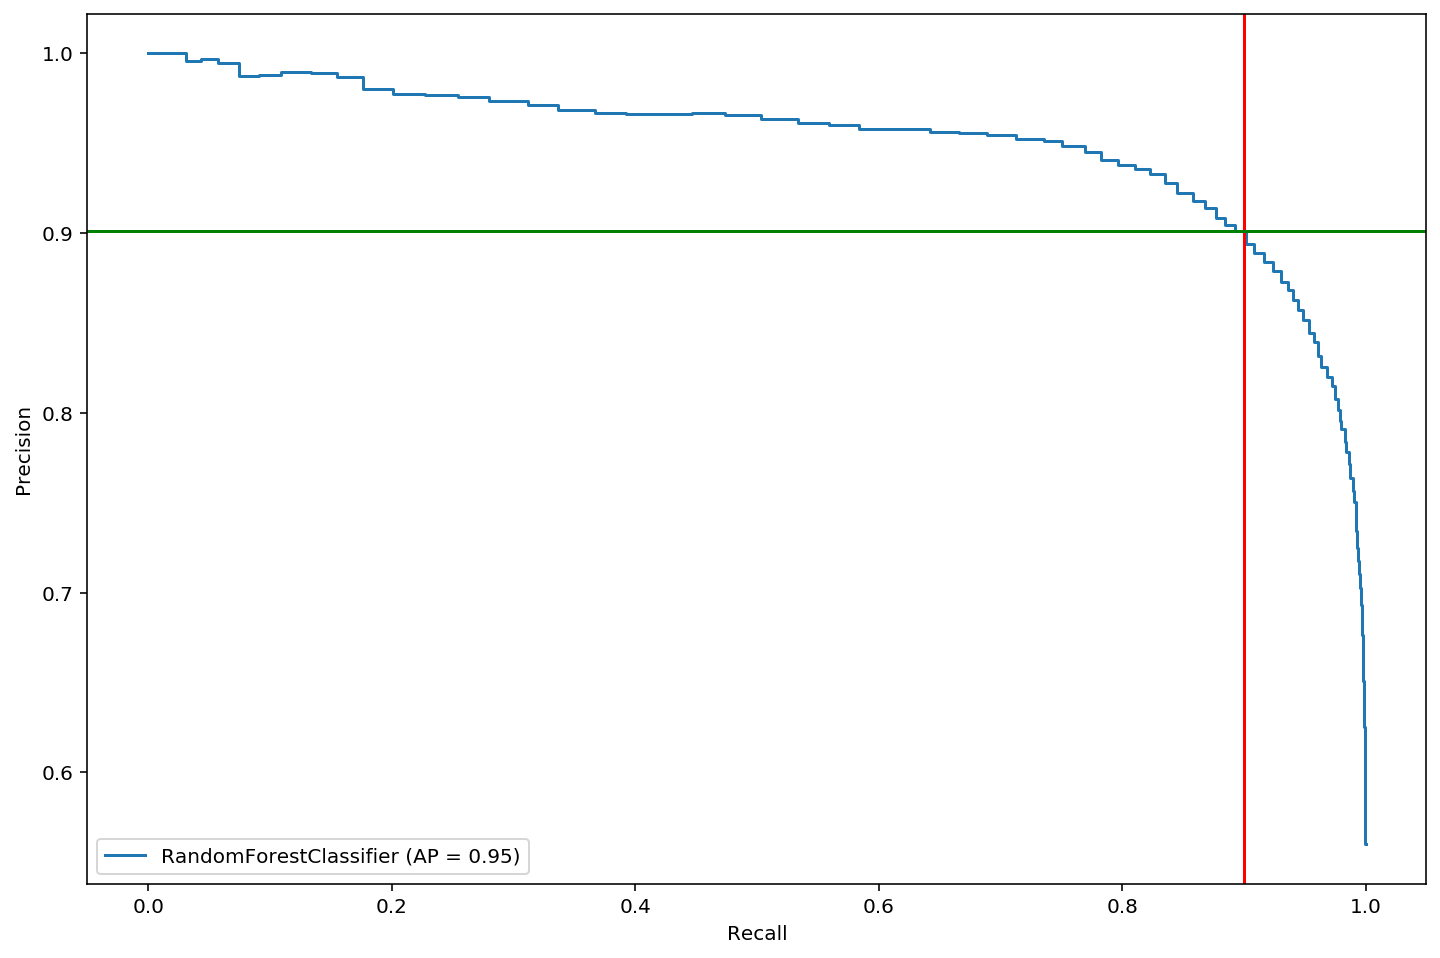

In [31]:
precision_recall_plot(clf, testSetData, testSetLabel, required_recall=0.9)

In [35]:
y_proba = clf.predict_proba(testSetData)[:,1]
y_proba

array([0.82, 0.73, 0.73, ..., 0.7 , 0.82, 0.04])

In [36]:
y_true = np.array(testSetLabel)
epsilon = 1e-5
log_likelihood_elements = y_true*np.log(y_proba+epsilon) + (1-y_true)*np.log(1-y_proba+epsilon)
log_likelihood_elements

array([-0.19843874, -0.31469705, -0.31469705, ..., -0.35666066,
       -0.19843874, -0.04081158])

In [37]:
y_pred = pd.Series(clf.predict(testSetData))
y_pred

0         True
1         True
2         True
3        False
4        False
         ...  
10277    False
10278     True
10279     True
10280     True
10281    False
Length: 10282, dtype: bool

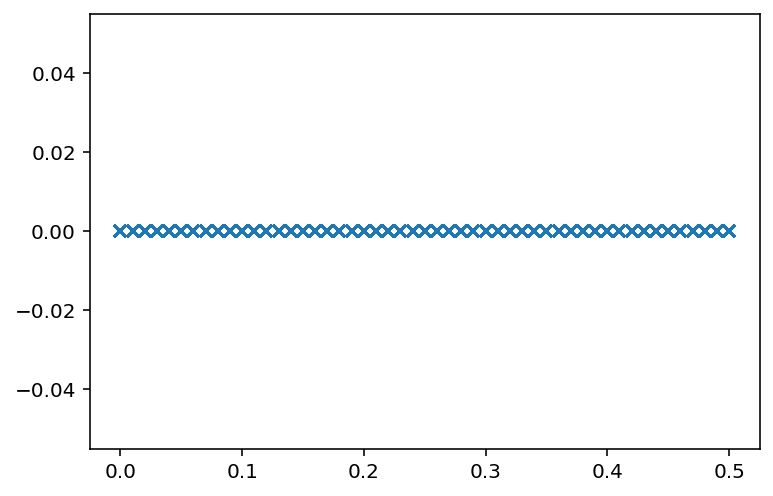

In [38]:
plt.plot(y_proba[~y_pred], np.zeros_like(y_proba[~y_pred]),'x')

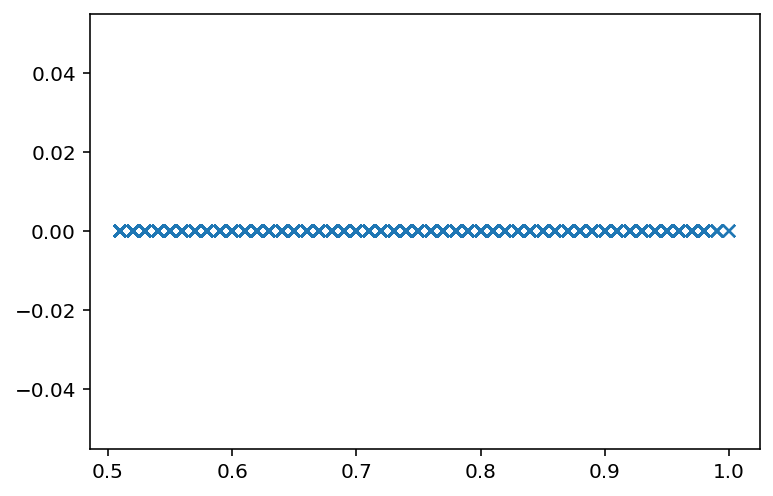

In [39]:
plt.plot(y_proba[y_pred], np.zeros_like(y_proba[y_pred]),'x')

In [40]:
ds_test.df_train

,x_feature_pixel_count_0,x_feature_pixel_count_1,x_feature_pixel_count_2,x_feature_pixel_count_3,x_feature_pixel_count_4,x_feature_pixel_count_5,x_feature_pixel_count_6,x_feature_pixel_count_7,x_feature_pixel_count_8,x_feature_pixel_count_9,...,x_feature_angle_10,x_feature_angle_11,x_feature_angle_12,x_feature_angle_13,x_feature_angle_14,x_feature_angle_15,detail,data_1,data_2,y
9422,0.170329,-0.351617,-0.575082,-0.074915,0.126211,-0.028471,-0.571074,-0.912722,-0.908116,-0.477165,...,0.481826,-0.076021,-0.253202,-0.309107,-0.120307,0.504141,RANDOM_FALSE,./test/test-features-16/NFI-00806008.pkl,./test/test-features-16/NFI-07012070.pkl,True
9417,-0.365193,-0.117069,-0.130118,0.344602,0.333683,0.152167,-0.320623,-0.552890,-0.051803,-0.180203,...,0.064778,0.628559,-0.032443,-0.017964,-0.363591,0.089831,RANDOM_FALSE,./test/test-features-16/NFI-05304053.pkl,./test/test-features-16/NFI-05511055.pkl,True
9298,0.641231,0.133450,-0.196710,-0.311328,-0.200232,-0.224691,0.382079,0.341536,-0.310324,-0.268414,...,-0.058209,-0.329666,0.009608,0.331929,0.208015,0.665616,RANDOM_FALSE,./test/test-features-16/NFI-05510055.pkl,./test/test-features-16/NFI-01205012.pkl,True
4320,0.028668,0.087286,-0.002664,0.037636,0.011519,-0.044341,0.306147,0.333153,-0.025594,0.000466,...,0.025550,-0.040725,0.058539,-0.111118,-0.232064,0.012172,AUTHENTIC,./test/test-features-16/NFI-05404054.pkl,./test/test-features-16/NFI-05402054.pkl,False
2961,-0.012594,-0.032364,0.079686,-0.046515,-0.007112,-0.068060,0.153168,0.053507,0.025362,-0.019558,...,0.997767,-0.057693,-0.028047,-0.018466,-0.091646,0.099302,AUTHENTIC,./test/test-features-16/NFI-06402064.pkl,./test/test-features-16/NFI-06405064.pkl,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3921,0.087914,-0.162268,-0.109284,0.063659,-0.089508,-0.378389,0.114621,0.022187,0.099250,-0.026012,...,0.152319,-0.657308,-0.240768,0.100291,0.011792,-0.224100,AUTHENTIC,./test/test-features-16/NFI-08603086.pkl,./test/test-features-16/NFI-08612086.pkl,False
8394,-0.348328,-0.358233,-0.400843,-0.023074,-0.318227,-0.130994,-0.288362,-0.246475,-0.212269,-0.299879,...,0.199448,-0.400204,0.025679,-0.031460,-0.008898,-0.009008,RANDOM_FALSE,./test/test-features-16/NFI-01606016.pkl,./test/test-features-16/NFI-07503075.pkl,True
5939,-0.006893,-0.076910,-0.396240,0.079525,0.190978,-0.139456,-0.411568,0.055306,0.102692,-0.007662,...,0.349275,-0.044280,0.077346,-0.057038,-0.158666,-0.135229,RANDOM_FALSE,./test/test-features-16/NFI-01412014.pkl,./test/test-features-16/NFI-04110041.pkl,True
5547,0.117756,0.572480,0.163605,-0.436269,-0.359280,-0.019456,0.234805,-0.231420,0.189651,-0.120775,...,0.077053,-0.880934,0.195569,-0.038018,0.155805,-0.079956,RANDOM_FALSE,./test/test-features-16/NFI-09005090.pkl,./test/test-features-16/NFI-08808088.pkl,True


In [49]:
def show_worse_predictions(df,respective_png_path):
    images = []
    titles = []
    c = 0
    for _,r in df.iterrows():
        fp_1 = os.path.join(respective_png_path, os.path.basename(r['data_1'])[:-3]+'png' )
        fp_2 = os.path.join(respective_png_path, os.path.basename(r['data_2'])[:-3]+'png' )
        img_1 = Image.open(fp_1)
        images.append(img_1)
        titles.append('PREDICT={} LABEL={} PROBA={}'.format(r['predict'],r['y'],r['proba']))
        img_2 =  Image.open(fp_2)
        images.append(img_2)
        titles.append('{} {} {}'.format(c,os.path.basename(fp_1),os.path.basename(fp_2)))
        c+=1
        if c>10:
            break
    plot_images_grid(images,width=2, titles=titles, figsize=(15,65))
    
test_by_likelihood =  ds_test.df_train.copy().reset_index(drop=True)
test_by_likelihood['proba'] = y_proba
test_by_likelihood['log_likelihood'] = log_likelihood_elements
test_by_likelihood['predict'] = y_pred
test_by_likelihood = test_by_likelihood.sort_values(by='log_likelihood')

test_by_likelihood_missmatches = test_by_likelihood[ test_by_likelihood['predict'] ]
test_by_likelihood_matches     = test_by_likelihood[ ~test_by_likelihood['predict'] ]

Worst MISSMATCHES


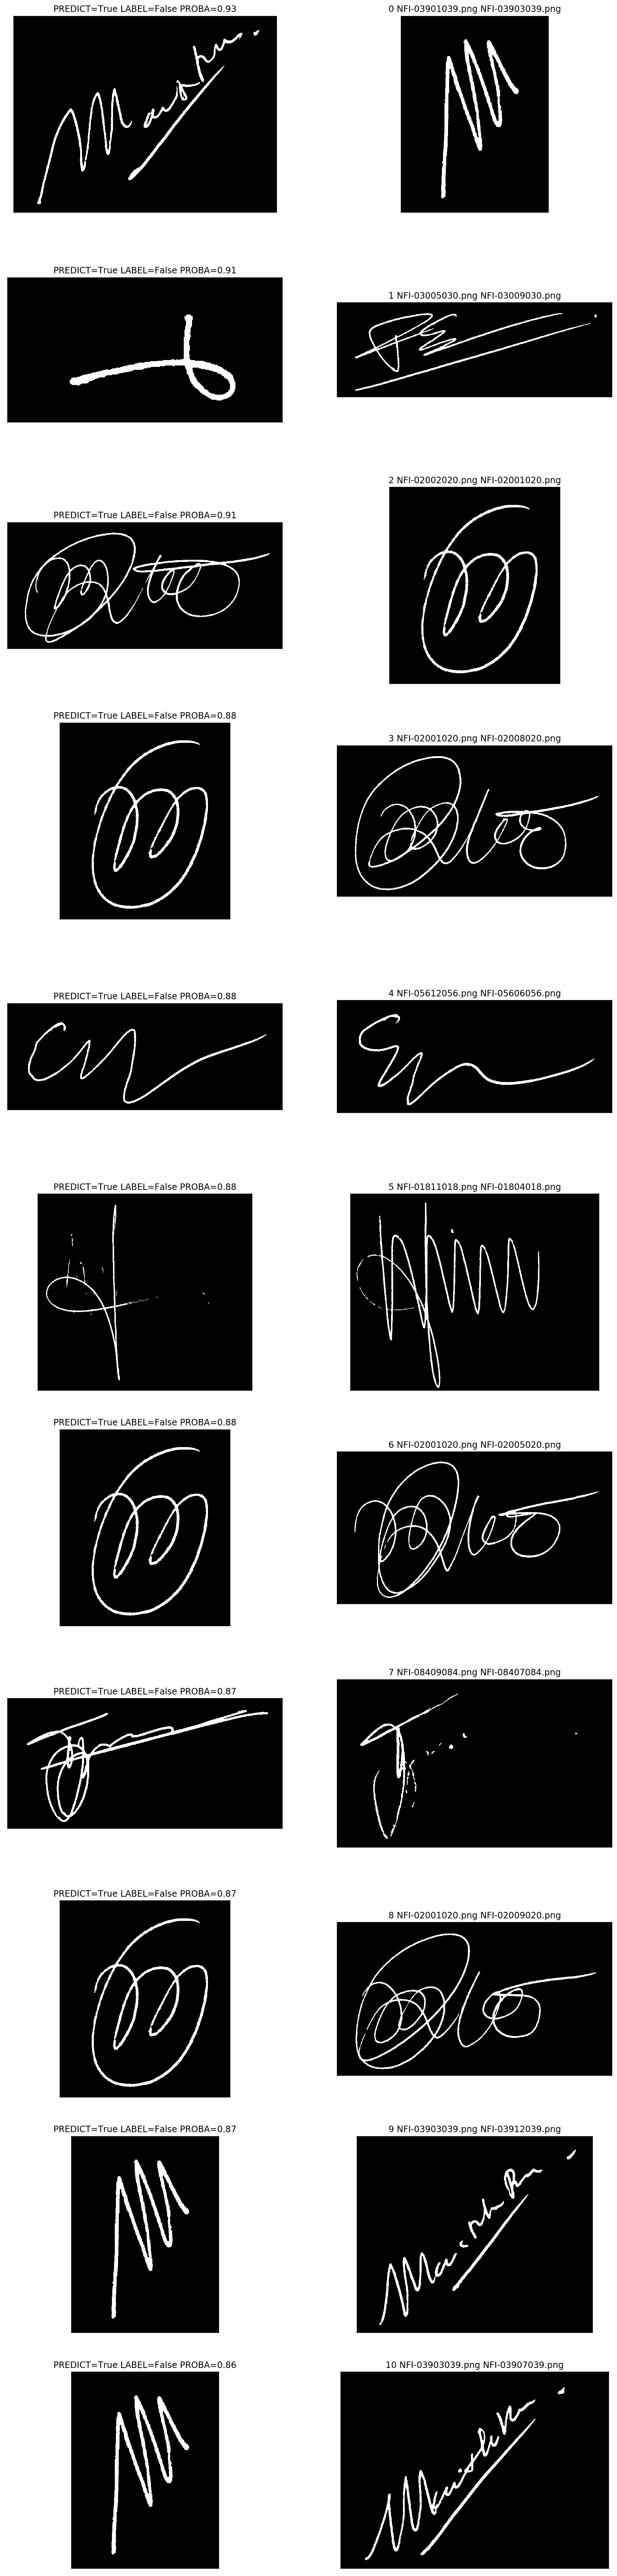

In [50]:
print("Worst MISSMATCHES")
show_worse_predictions(test_by_likelihood_missmatches, './test/preprocessed-test')

Worst MATCHES


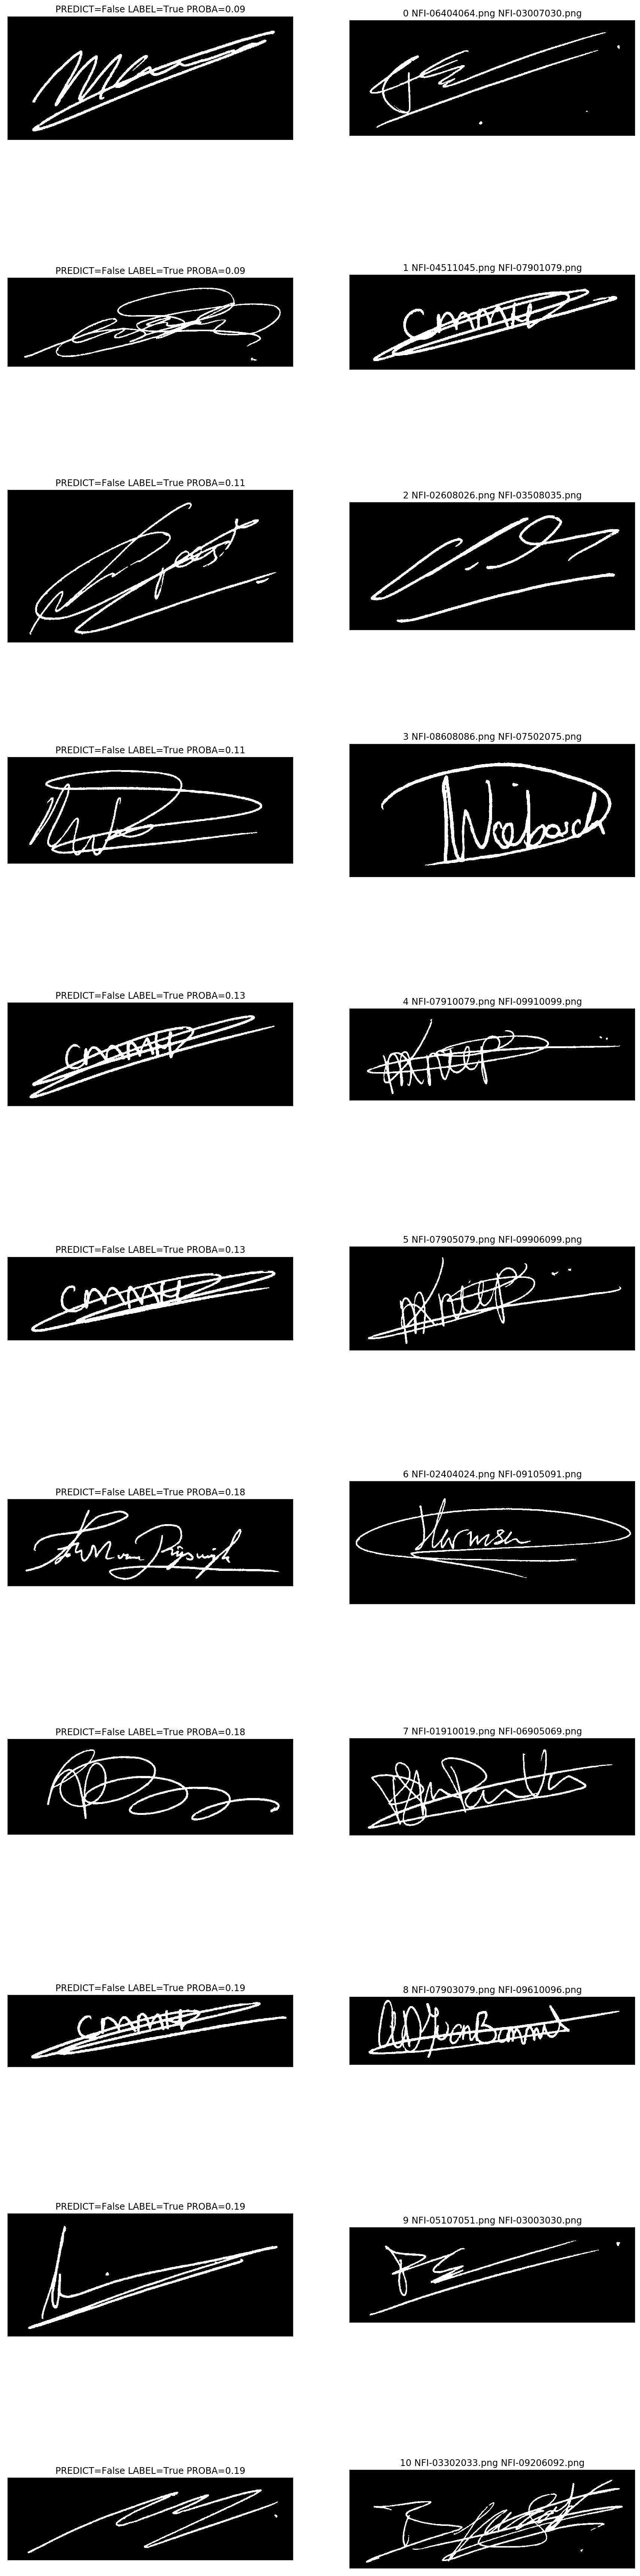

In [51]:
print("Worst MATCHES")
show_worse_predictions(test_by_likelihood_matches,'./test/preprocessed-test')

10282
117600
5313


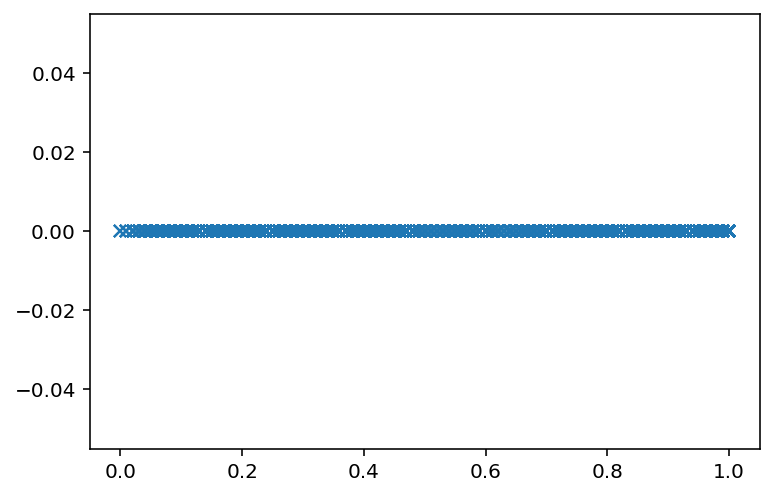

In [32]:
print(len(test_by_likelihood))
print(len(pd.Series(clf.predict(ds.trainData))))
data = test_by_likelihood[test_by_likelihood['predict']]['proba']
#data = y_proba[y_pred]
print(len(data))
plt.plot(data, np.zeros_like(data),'x')

# PCA para visualizar y entender los datos

El análisis de componentes principales nos puede ser últil para, reduciendo la dimensionalidad de los datos, visualizarlos y verificar ciertas propiedades. Podemos analizar tanto el dataset original (donde cada autor podría verse como una clase) como el dataset de nuestro problemas (pares de firmas y las clases son matcheos no matcheos).


## Visualización de 'matcheos', 'no matcheos'

A continuación vemos que las features de los 'matcheos' se encuentran más cerca del origen, esto es esperable ya que en este dataset tomamos la diferencia de features componente a componente por lo cuál firmas del mismo autor serán más coincidentes.
La contrapartida de lo que se observa es que existen pares de firmas que están cerca del origen y no corresponden firmas que coincidan en autoría

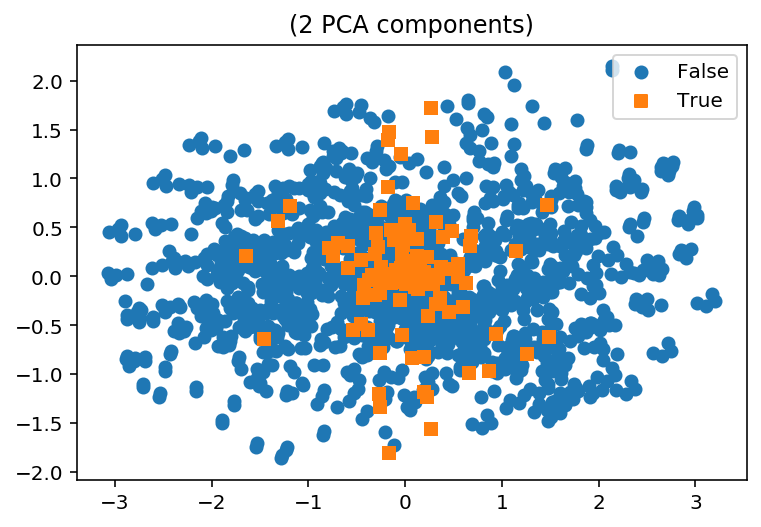

In [10]:
pca = PCA(n_components=2)
plot_2d_space(pca.fit_transform(ds.trainData), [not(x) for x in ds.trainLabel], '(2 PCA components)')

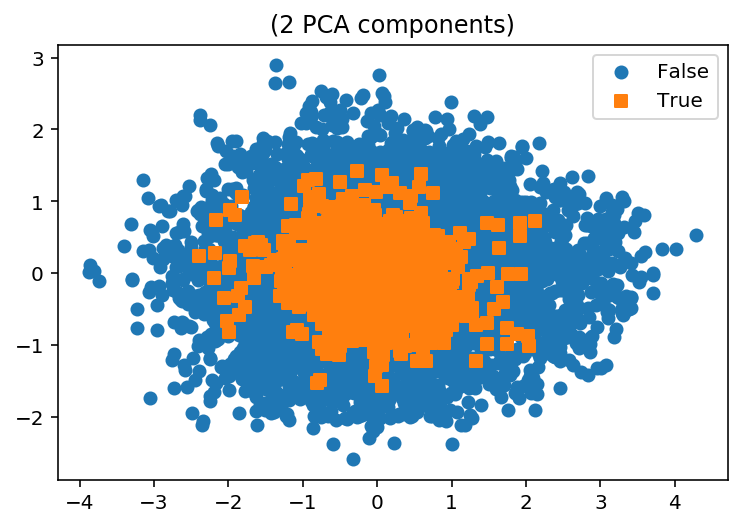

In [11]:
plot_2d_space(pca.fit_transform(testSetData), [not(x) for x in testSetLabel], '(2 PCA components)')

## Visualización por autores

Visualizando cada firma y no pares de firmas y cada autor como una clase diferente podemos ver que:

- Las features elegidas en general clusterizan y separan las firmas.
- En el dataset de entrenamiento parece estar todo más separado, más fácil de diferenciar. Es bueno que el dataset de test sea desafiante.

In [4]:
""" Load and preprocess data on test set. """
test_features_dataset = load_dataset_sigComp2009Test('./test/test-features-16', extension='pkl')
print("Lodaded {} files.".format(len(flatten_dataset(test_features_dataset))))
_, _, test_to_features = feature_dataset_parameters(test_features_dataset)
test_features_normal = to_normal_features(QuantileTransformer,test_features_dataset,test_to_features)

Lodaded 940 files.
N_divisions:{16}
Signature types: 79
Cant_features:{3}
N_division check:{16}


In [12]:
""" Load and preprocess data on test set. """
train_features_dataset = load_dataset_sigComp2009Train(FEATURES_PATH, extension='pkl',
        regex_filename = r'NISDCC-([0-9]{3})_([0-9]{3})_([0-9]{3})_6g.')
print("Lodaded {} files.".format(len(flatten_dataset(train_features_dataset))))
_, _, train_to_features = feature_dataset_parameters(train_features_dataset)
train_features_normal = to_normal_features(QuantileTransformer,train_features_dataset,train_to_features)

Lodaded 1898 files.
N_divisions:{16}
Signature types: 12
Cant_features:{3}
N_division check:{16}


In [19]:
def data_by_author_class(features_dataset,features_normal):
    data_to_features = DataToFeatures_Features(features_normal)
    data = []
    for pa,sa,sid,fp in flatten_dataset(features_dataset):
        if pa==sa:
            features = list(list(zip(*data_to_features.feature_calc(fp)))[1])        
            data.append( [pa]+ features)
    df = pd.DataFrame(data=data,columns=['author']+data_to_features.feature_labels())

    x = df[[c for c in df.columns if c!='author']].to_numpy()
    y = df['author']
    return x,y
def pca_by_author_2d(features_dataset, features_normal):
    x,y = data_by_author_class(features_dataset, features_normal)
    pca = PCA(n_components=2)
    x_pca = pca.fit_transform(x)
    plt.scatter(x_pca[:,0], x_pca[:,1],c=pd.factorize(y)[0], cmap=plt.get_cmap('Set1'))

def pca_by_author_3d(features_dataset, features_normal):
    x,y = data_by_author_class(features_dataset, features_normal)
    pca = PCA(n_components=3)
    x_pca_3 = pca.fit_transform(x)
    
    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')
    ax.scatter(x_pca_3[:,0], x_pca_3[:,1], x_pca_3[:,2],c=pd.factorize(y)[0], cmap=plt.get_cmap('Set1'))
    ax.set_xlabel('X Label')
    ax.set_ylabel('Y Label')
    ax.set_zlabel('Z Label')
    plt.show()

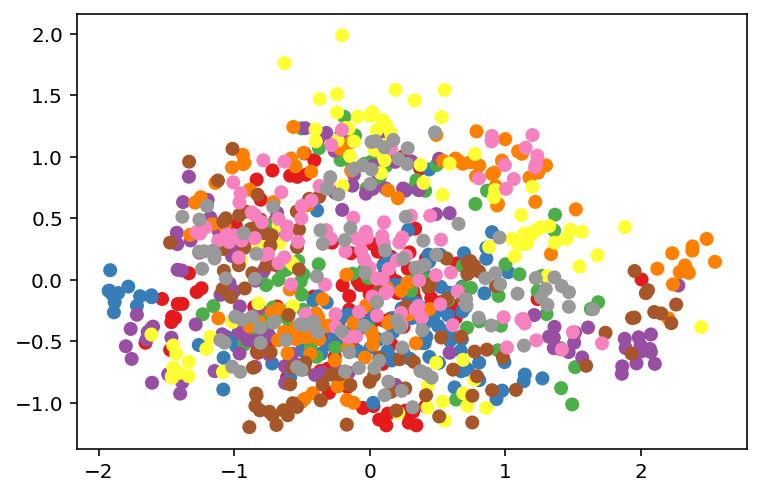

In [11]:
pca_by_author_2d(test_features_dataset,test_features_normal)

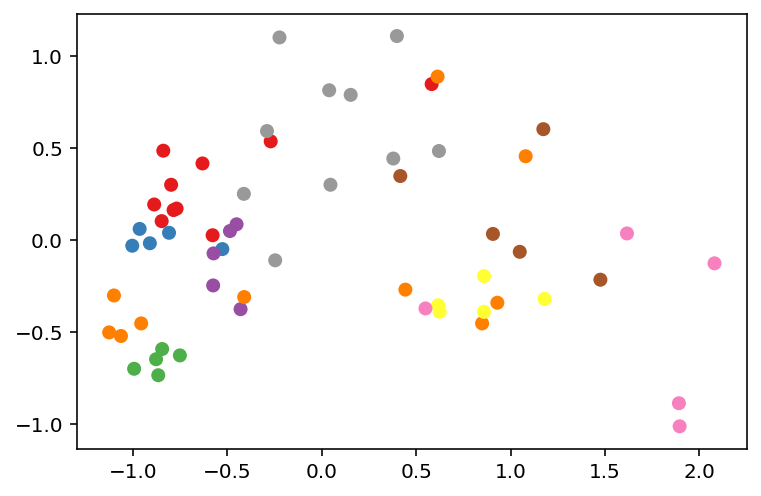

In [13]:
pca_by_author_2d(train_features_dataset,train_features_normal)

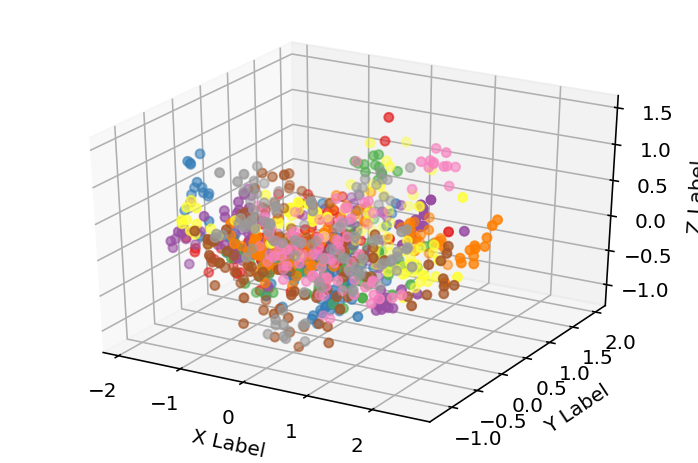

In [20]:
pca_by_author_3d(test_features_dataset,test_features_normal)

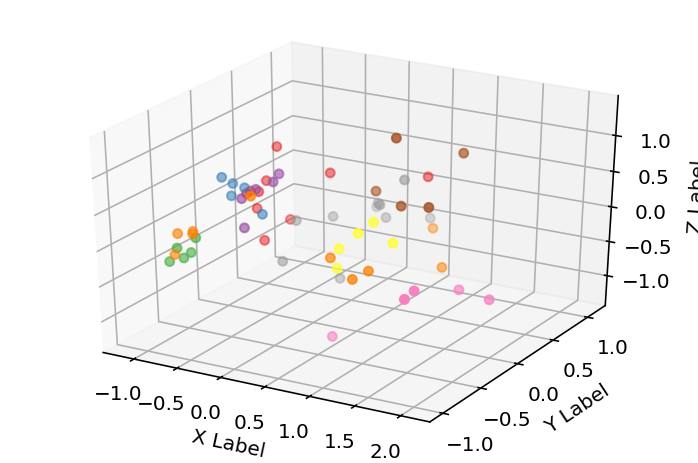

In [21]:
pca_by_author_3d(train_features_dataset,train_features_normal)

# Ultimos intentos de fine tunning

El método hallado parece ser *suficientemente bueno* acorde a lo que estábamos buscando: una precisión del 87% para un recall del 90%.

TODO COMPARAR CON ESTADO DEL ARTE

Sin embargo, la diferencia de score obtenida en train (aproximadamente 1) y test nos da la pauta que tenemos un problema de overfitting, incluso haciendo data augmentation para tener más cantidad de firmas por autor. El problema de esto es que puede ser que exista *sobreajuste por los autores* y no estamos con el data augmentation que propusimos, generando nuevos autores. Tenemos pocos autores (12) y puede ser que nuetro algoritmo esté aprendiendo muy bien a detectar coincidencias de firmas *para esos autores* pero que no sea tan bueno para autores que no aparezcan en el conjunto de entrenamiento.

Intentaremos dos últimas ideas con el objetivo de obtener aún mejores resultados disminuyendo el sobreajuste: encontrar mejores parámetros de random forest, para lo que usaremos la GridSearch de sklearn y realizar data augmentation de autres, generando autores sintéticos.

## Author data augmentation

La cantidad de autores es poca y el problema de overfitting puede ser causado por un sobreajuste *por autor* y la carencia de nueestro modelo a generalizar para autores desconocidos.

Una idea que se nos ha ocurrido para solucionar esto es hacer data augmentation de autores: generar nuevos autores flipeando verticalmente/horizontalmente las firmas, de modo que cada autor genere otros 4 autores *distintos*.

In [20]:
AUTHOR_AUGMENTATION_PATH_FEATURES16 = './author_augmentation_features16'
AUTHOR_AUGMENTATION_PATH = './author_augmentation'

In [6]:
# Solo trabajaremos sobre firmas originales porque son las que usa el presente trabajo. Asi ahorramos tiempo de procesamiento.
preprocess_dataset = load_dataset_sigComp2009Train(PREPROCESSED_PATH)
only_authenthic_flatten = [x for x in flatten_dataset(preprocess_dataset) if x[0]==x[1]]
print('Total signatures {} | Only authentics: {}'.format(len(flatten_dataset(preprocess_dataset)),len(only_authenthic_flatten)))

Total signatures 1898 | Only authentics: 60


Seleccionamos un autor y le aplicamos *author_augmentation_callback* para ver que funcione correctamente:

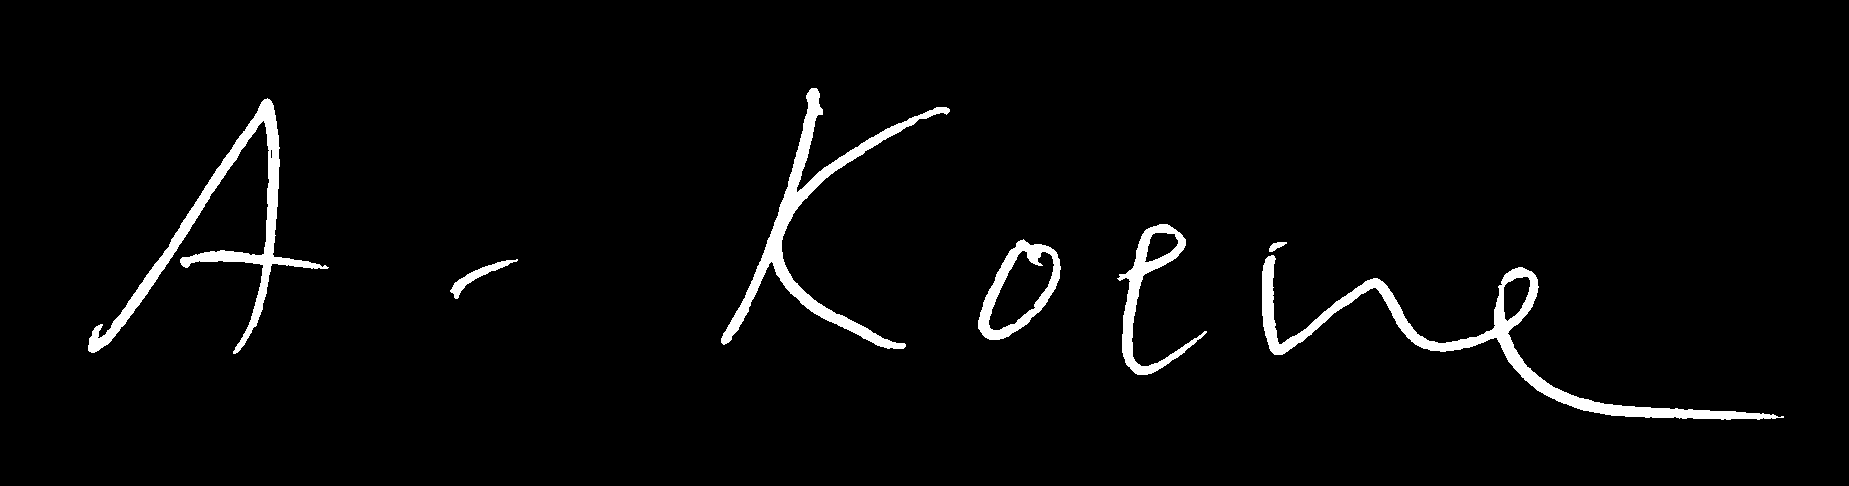

In [9]:
Image.open(only_authenthic_flatten[0][3])

('006', '006', '004')


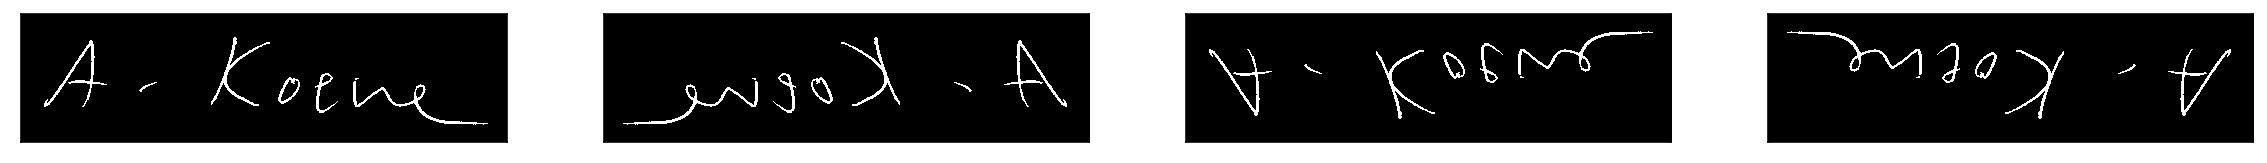

In [13]:
augmented = [Image.open(x[3]) for x in author_augmentation_callback('./',only_authenthic_flatten[0])]
plot_images_grid(augmented,width=4,figsize=(20,20))

In [8]:
# Aquí producimos el data augmentation por autores
parallel_mapping(author_augmentation_callback, only_authenthic_flatten, AUTHOR_AUGMENTATION_PATH)

Are you sure to delete ./author_augmentation? ['yes' for yes]
yes


  0%|          | 0/60 [00:00<?, ?it/s]

('006', '006', '003')
('006', '006', '001')
('005', '005', '003')
('005', '005', '004')
('006', '006', '004')
('005', '005', '005')
('006', '006', '005')
('006', '006', '002')
('005', '005', '001')
('011', '011', '001')
('005', '005', '002')
('011', '011', '003')
('011', '011', '004')
('011', '011', '002')


  2%|▏         | 1/60 [00:00<00:24,  2.45it/s]

('004', '004', '005')
('011', '011', '005')
('004', '004', '003')
('004', '004', '001')


 17%|█▋        | 10/60 [00:00<00:14,  3.44it/s]

... (17 outputs left out)

 78%|███████▊  | 47/60 [00:02<00:00, 15.39it/s]

('009', '009', '002')
('008', '008', '001')
('008', '008', '004')
('008', '008', '005')
('008', '008', '002')
('008', '008', '003')


100%|██████████| 60/60 [00:02<00:00, 20.45it/s]


[('0060', '0060', '004', './author_augmentation/NISDCC-0060_0060_004_6g.PNG'),
 ('0061', '0061', '004', './author_augmentation/NISDCC-0061_0061_004_6g.PNG'),
 ('0062', '0062', '004', './author_augmentation/NISDCC-0062_0062_004_6g.PNG'),
 ('0063', '0063', '004', './author_augmentation/NISDCC-0063_0063_004_6g.PNG'),
 ('0060', '0060', '001', './author_augmentation/NISDCC-0060_0060_001_6g.PNG'),
 ('0061', '0061', '001', './author_augmentation/NISDCC-0061_0061_001_6g.PNG'),
 ('0062', '0062', '001', './author_augmentation/NISDCC-0062_0062_001_6g.PNG'),
 ('0063', '0063', '001', './author_augmentation/NISDCC-0063_0063_001_6g.PNG'),
 ('0060', '0060', '003', './author_augmentation/NISDCC-0060_0060_003_6g.PNG'),
 ('0061', '0061', '003', './author_augmentation/NISDCC-0061_0061_003_6g.PNG'),
 ('0062', '0062', '003', './author_augmentation/NISDCC-0062_0062_003_6g.PNG'),
 ('0063', '0063', '003', './author_augmentation/NISDCC-0063_0063_003_6g.PNG'),
 ('0060', '0060', '005', './author_augmentation/NISD

### Data augmentation - Extraccion de features

A este nuevo dataset con el cuádruple de autores podemos aplicarle el data augmentation original (que aumentaba la cantidad de firmas por autor). Hemos explorado esta posibilidad así surge *author_augmentation-augmented*.

Extraemos las features para una grilla de 16 divisiones del mismo modo que hacíamos antes

### Evaluación

Finalmente evaluamos los resultados sobre el dataset de autores aumentados. Podemos observar una vez más que aplicar el data augmentation original mejora los resultados.TODO

In [5]:
preprocess_dataset_author_augmented = load_dataset_sigComp2009Train('./author_augmentation-augmented_features16',
    extension = 'pkl',
    regex_filename = r'NISDCC-([0-9]{4})_([0-9]{4})_([0-9]{4})_6g.')
print("Lodaded {} files.".format(len(flatten_dataset(preprocess_dataset_author_augmented)))) 

_, _, to_features_author_augmented = feature_dataset_parameters(preprocess_dataset_author_augmented)
feature_obtainer_factory = lambda features_normal: FeatureObtainer_Difference( DataToFeatures_Features(features_normal) )
data_constructor = DataSetConstructor(feature_obtainer_factory,  'UNDERSAMPLE', preprocess_dataset_author_augmented, to_features_author_augmented, QuantileTransformer, test_ratio = 0)
ds = data_constructor.construct_datasets()
print('Train len: {} | Test len: {}'.format(len(ds.trainData),len(ds.testData)))

Lodaded 2400 files.
N_divisions:{16}
Signature types: 48
Cant_features:{3}
N_division check:{16}
Train len: 117600 | Test len: 0


In [6]:
clf = RandomForestClassifier(oob_score=True, max_features=2)
assert is_fitted(clf)==False
clf.fit(ds.trainData, ds.trainLabel)
assert is_fitted(clf)==True
print_scoring(clf,ds,0.9)

TrainScore: 1.0 | TestScore: No test data


In [7]:
score_function = precision_by_recall_score_factory(0.9)
score_function(clf, testSetData,testSetLabel)

0.8980854766969638

### Conclusiones

Como conclusión de esta sección cabe señalar que el data augmentation de autores es una buena idea, aumentó en 3 puntos porcentuales nuestra precisión en el conjunto de test.

## Parámetros de RandomForest

In [21]:
from sklearn.model_selection import GroupKFold
y = np.array([0,1, 2, 3, 4,5,6,7,8,9,10,11])
X = y
groups = y
group_kfold = GroupKFold(n_splits=6)
group_kfold.get_n_splits(X, y, groups)

for train_index, test_index in group_kfold.split(X, y, groups):
     print("TRAIN:", train_index, "TEST:", test_index)
     X_train, X_test = X[train_index], X[test_index]
     y_train, y_test = y[train_index], y[test_index]

TRAIN: [ 0  1  2  3  4  6  7  8  9 10] TEST: [ 5 11]
TRAIN: [ 0  1  2  3  5  6  7  8  9 11] TEST: [ 4 10]
TRAIN: [ 0  1  2  4  5  6  7  8 10 11] TEST: [3 9]
TRAIN: [ 0  1  3  4  5  6  7  9 10 11] TEST: [2 8]
TRAIN: [ 0  2  3  4  5  6  8  9 10 11] TEST: [1 7]
TRAIN: [ 1  2  3  4  5  7  8  9 10 11] TEST: [0 6]
